# Frame inspector: every validation frame, every model, and why each box was right or wrong

**Inputs (attach both as Kaggle datasets):**
1. **DSERT-RoLL** as you already have it: `processed_data/<Weather>/<drive>/` with `label.pkl`, the LiDAR and radar
   `.npy` files and the camera images. It may be split over several datasets; the notebook finds the pieces.
2. **The four `result.pkl` files** from Snellius. Every evaluation already ran its model on every validation frame and
   saved all predicted boxes there; nothing is run again here. Download them (OnDemand file browser) from
   `~/DSERT-RoLL-3DOD/detection/output/det_model_cfgs/dsert/lidar_only/` and name them after the model:

   | upload as | from |
   |---|---|
   | `radar_scratch.pkl` | `radar_scratch/eval/eval_with_train/epoch_20/val/result.pkl` |
   | `radar_ft_from_livox.pkl` | `radar_ft_from_livox/eval/eval_with_train/epoch_20/val/result.pkl` |
   | `livox_e20_on_radar.pkl` | `livox_e20_on_radar/eval/epoch_20/val/result.pkl` |
   | `livox_pretrain.pkl` | `livox_pretrain/eval/eval_with_train/epoch_20/val/result.pkl` |

   Optional: the `log_train_*.txt` / `log_eval_*.txt` files of those runs, to compare with the official AP.

On a laptop (no `/kaggle/input`) it looks in `~/dsert-roll-sample` and `dsert_results/` instead (see `INPUTS` in section 1).

Run the cells top to bottom. The first run reads every radar and LiDAR file once (section 1) and caches the result in
the output folder; after that everything is fast.

## How the scores work

Same rules as the DSERT-RoLL paper and its evaluation code (official Waymo Open Dataset metrics):
* only labelled and predicted boxes **within 70 m** of the car count (`distance < 70.5 m`, as the code does it)
* a predicted box is **correct** if it overlaps a labelled box of the same class enough: **3D IoU ≥ 0.5 for
  vehicles** (≥ 0.3 for pedestrians and bikes); each labelled box can be taken by **one** predicted box only, and
  boxes are paired by an optimal (Hungarian) assignment within each frame
* only **level-1** labelled boxes are scored; a box that lands on a level-2 one is neither right nor wrong

**The official number (AP, the "0.36" on wandb)** is computed over *all* frames at once, per class: for score
cut-offs 0.00, 0.01, ..., 1.00, keep the boxes above the cut-off, count *precision* = correct / kept boxes and
*recall* = correct / all labelled boxes; **AP = area under that precision-recall curve**. One number for the
whole set; there is no "AP of a frame".

**Per frame (this notebook)** there is **no extra score cut-off**: every box the model output (all boxes in
`result.pkl`, i.e. score ≥ 0.1, the model's own `SCORE_THRESH`) counts, which is the lowest cut-off of the official
sweep. Then for each frame:
* **found** = labelled boxes matched by a predicted box, **missed** = labelled boxes nobody matched,
  **false** = predicted boxes that match no labelled box
* verdict: **GOOD** = everything found and no false boxes, **BAD** = at least one miss,
  **UGLY** = at least one false box (a frame can be BAD+UGLY)

Every miss and every false box gets a **reason** (section 3), and section 4 draws any frame with all of it written
on the picture.

## 1. Load

In [1]:
import os, io, re, zipfile, pickle, time, hashlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
pd.set_option("display.max_rows", 300); pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)

# The setups (what was trained, how), in the order they are reported. A setup can have several runs (seeds): the
# prediction files are named <setup>.pkl (the first, unseeded run), <setup>_s1.pkl, <setup>_s2.pkl, ...
# "_xyz" = the radar's Doppler value was not given to the model (4th point value all zeros).
SETUP_NAME = {"radar_scratch": "radar, from scratch",
              "radar_ft_from_livox": "radar, fine-tuned from LiDAR",
              "radar_scratch_xyz": "radar without Doppler, from scratch",
              "radar_ft_from_livox_xyz": "radar without Doppler, fine-tuned from LiDAR",
              "livox_e20_on_radar": "LiDAR model fed radar (no training)",
              "livox_e20_on_radar_xyz": "LiDAR model fed radar without Doppler (no training)",
              "livox_pretrain": "LiDAR model, LiDAR input"}
# The comparisons reported wherever setups are averaged over their runs: (what it shows, setup, minus setup)
COMPARISONS = [("LiDAR pre-training adds (with Doppler)", "radar_ft_from_livox", "radar_scratch"),
               ("LiDAR pre-training adds (without Doppler)", "radar_ft_from_livox_xyz", "radar_scratch_xyz"),
               ("Doppler adds (from scratch)", "radar_scratch", "radar_scratch_xyz"),
               ("Doppler adds (fine-tuned)", "radar_ft_from_livox", "radar_ft_from_livox_xyz")]
def setup_of(run):
    return re.sub(r"_s\d+$", "", run)
CLASSES = ["Vehicle", "Pedestrian", "Bike"]                   # CLASS_NAMES of lidar_only.yaml; id c = CLASSES[c - 1]
IOU_THR = {"Vehicle": 0.5, "Pedestrian": 0.3, "Bike": 0.3}    # same as the official evaluation
MAX_DIST = 70.5                                               # the evaluation ignores everything beyond this
PCR = np.array([0, -76.8, -2, 76.8, 76.8, 4])                 # POINT_CLOUD_RANGE the models were trained with
ON_KAGGLE = os.path.isdir("/kaggle/input")
OUT_DIR = "/kaggle/working" if ON_KAGGLE else "frame_inspector_output"
os.makedirs(OUT_DIR, exist_ok=True)
# Where to look for data and predictions: Kaggle's attached datasets, or on a laptop the DSERT-RoLL sample
# folder and the downloaded result.pkl files (add your own paths here).
INPUTS = ["/kaggle/input"] if ON_KAGGLE else \
    [os.path.expanduser("~/dsert-roll-sample"), "dsert_results_all", "dsert_results", "detection/data/dsert-roll"]

# One walk over the attached datasets: drive folders (and their label.pkl), the result.pkl files, the eval logs.
DRIVE = re.compile(r"\d{4}(_\d{2}){5}$")                      # drive folders are named like 2025_04_16_07_04_30
ROOTS, LABELS, PKLS, LOGS = [], {}, [], []
for path, dirs, files in (w for top in INPUTS if os.path.isdir(top) for w in os.walk(top, followlinks=True)):
    dirs[:] = [d for d in dirs if not d.startswith(".")]     # skip e.g. a download tool's .cache
    for d in [d for d in dirs if DRIVE.match(d)]:
        dirs.remove(d)                                        # do not walk into a drive's thousands of frame files
        root = os.path.dirname(path)                          # .../processed_data (path is .../processed_data/<Weather>)
        if root not in ROOTS:
            ROOTS.append(root)
        if os.path.exists(os.path.join(path, d, "label.pkl")):
            LABELS.setdefault(d, os.path.join(path, d, "label.pkl"))
    PKLS += [os.path.join(path, f) for f in files if f.endswith(".pkl")]
    LOGS += [os.path.join(path, f) for f in files if re.match(r"log_(eval|train)_.*\.txt$", f)]

# Every prediction file of a known setup: <run>.pkl, or a run folder's own .../<run>/.../result.pkl (epoch 20 first).
found = {}
for p in PKLS:
    run, rank = os.path.basename(p)[:-4], 0
    if run == "result":
        run = next((d for d in reversed(re.split(r"[\\/]", p)) if setup_of(d) in SETUP_NAME), "")
        rank = 1 if "epoch_20" in p else 2
    if setup_of(run) in SETUP_NAME:
        found.setdefault(run, []).append((rank, p))
seed_of = lambda run: int(re.search(r"_s(\d+)$", run).group(1)) if re.search(r"_s\d+$", run) else 0
RESULT = {m: min(found[m])[1] for m in sorted(found, key=lambda m: (list(SETUP_NAME).index(setup_of(m)), seed_of(m)))}
MODELS = list(RESULT)                                         # every run
assert MODELS, "no predictions found: attach the result.pkl files (named radar_scratch.pkl, radar_scratch_s1.pkl, ...)"
assert LABELS, "no label.pkl found: attach the DSERT-RoLL dataset (processed_data/<Weather>/<drive>/label.pkl)"
SETUP = {m: setup_of(m) for m in MODELS}
RUNS = {s: [m for m in MODELS if SETUP[m] == s] for s in SETUP_NAME if s in SETUP.values()}   # setup -> its runs
MAIN = [runs[0] for runs in RUNS.values()]                    # one run per setup (the unseeded one if it exists):
                                                              # the run the per-frame sections 3, 3c, 4-7 look at
NAME = {m: SETUP_NAME[SETUP[m]] + (", seed %d" % seed_of(m) if seed_of(m) else "") for m in MODELS}
SENSOR = {m: ("lidar" if SETUP[m] == "livox_pretrain" else "radar") for m in MODELS}        # what each model sees
for m, p in RESULT.items():
    print("predictions %-28s <- %s" % (m, p))
print("setups and their runs:")
for s, runs in RUNS.items():
    print("   %-52s %d run(s): %s" % (SETUP_NAME[s], len(runs), ", ".join(runs)))

def pm(values, digits=4):
    "'mean ± standard deviation' over runs (sample standard deviation, n - 1; a single run: the number alone)."
    v = np.array([x for x in values if x == x], float)
    if not len(v):
        return ""
    return "%.*f" % (digits, v.mean()) + (" ± %.*f" % (digits, v.std(ddof=1)) if len(v) > 1 else "")

def setup_table(value, columns, setups=None):
    "Rows = setups, one column per entry of columns: mean ± std of value(run, column) over the setup's runs."
    return pd.DataFrame.from_dict({SETUP_NAME[s]: {c: pm([value(m, c) for m in RUNS[s]]) for c in columns}
                                   for s in (setups or RUNS) if s in RUNS}, orient="index")

def gain_table(value, columns):
    """Rows = COMPARISONS, entries = mean of the first setup's runs minus mean of the second's.
    A '*' means every single run of one setup lies above every run of the other (the runs do not overlap)."""
    rows = {}
    for label, a, b in COMPARISONS:
        if a in RUNS and b in RUNS:
            rows[label] = {}
            for c in columns:
                va, vb = [value(m, c) for m in RUNS[a]], [value(m, c) for m in RUNS[b]]
                va, vb = [x for x in va if x == x], [x for x in vb if x == x]
                rows[label][c] = "" if not va or not vb else \
                    "%+.4f%s" % (np.mean(va) - np.mean(vb), " *" if min(va) > max(vb) or max(va) < min(vb) else "")
    return pd.DataFrame.from_dict(rows, orient="index")
print("%d drives with labels, data folders: %s" % (len(LABELS), ROOTS))

def resolve(rel):
    "A path from label.pkl (relative to processed_data) -> the file in whichever attached dataset has it ('' if none)."
    for r in ROOTS:
        p = os.path.join(r, rel)
        if os.path.exists(p):
            return p
    return ""

def part(key, k):
    "Rows of a flat array that belong to frame k (k = 0..N-1)."
    off = F[key + "_off"]
    return slice(off[k], off[k + 1])

predictions radar_scratch                <- /kaggle/input/datasets/muhammadibnerafiq/dsert-results-all/dsert_results/radar_scratch.pkl
predictions radar_scratch_s1             <- /kaggle/input/datasets/muhammadibnerafiq/dsert-results-all/dsert_results/radar_scratch_s1.pkl
predictions radar_scratch_s2             <- /kaggle/input/datasets/muhammadibnerafiq/dsert-results-all/dsert_results/radar_scratch_s2.pkl
predictions radar_ft_from_livox          <- /kaggle/input/datasets/muhammadibnerafiq/dsert-results-all/dsert_results/radar_ft_from_livox.pkl
predictions radar_ft_from_livox_s1       <- /kaggle/input/datasets/muhammadibnerafiq/dsert-results-all/dsert_results/radar_ft_from_livox_s1.pkl
predictions radar_ft_from_livox_s2       <- /kaggle/input/datasets/muhammadibnerafiq/dsert-results-all/dsert_results/radar_ft_from_livox_s2.pkl
predictions radar_scratch_xyz_s1         <- /kaggle/input/datasets/muhammadibnerafiq/dsert-results-all/dsert_results/radar_scratch_xyz_s1.pkl
predictions radar_

In [2]:
# Geometry: 3D IoU of rotated boxes [x, y, z, dx, dy, dz, heading] (z = box centre), as the evaluation computes it
def bev_corners(b):
    "Corners of the box seen from above, counter-clockwise."
    c = np.array([[1, 1], [-1, 1], [-1, -1], [1, -1]]) * [b[3] / 2, b[4] / 2]
    ch, sh = np.cos(b[6]), np.sin(b[6])
    return c @ np.array([[ch, sh], [-sh, ch]]) + b[:2]

def clip_polygon(poly, window):
    "The part of convex polygon `poly` inside convex polygon `window` (both counter-clockwise)."
    for a, b in zip(window, np.roll(window, -1, 0)):
        if not len(poly):
            break
        side = lambda p: (b[0] - a[0]) * (p[1] - a[1]) - (b[1] - a[1]) * (p[0] - a[0])
        out = []
        for p, q in zip(np.roll(poly, 1, 0), poly):          # edge p -> q
            sp, sq = side(p), side(q)
            if sq >= 0:
                if sp < 0:
                    out.append(p + (q - p) * sp / (sp - sq))
                out.append(q)
            elif sp >= 0:
                out.append(p + (q - p) * sp / (sp - sq))
        poly = np.array(out)
    return poly

def area(poly):
    if len(poly) < 3:
        return 0.0
    x, y = poly[:, 0], poly[:, 1]
    return 0.5 * abs(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)))

def iou3d(a, b):
    if np.hypot(a[0] - b[0], a[1] - b[1]) > (np.hypot(a[3], a[4]) + np.hypot(b[3], b[4])) / 2:
        return 0.0
    inter = area(clip_polygon(bev_corners(a), bev_corners(b)))
    dz = max(0.0, min(a[2] + a[5] / 2, b[2] + b[5] / 2) - max(a[2] - a[5] / 2, b[2] - b[5] / 2))
    v = inter * dz
    return v / max(a[3] * a[4] * a[5] + b[3] * b[4] * b[5] - v, 1e-9)

def points_in_box(pts, b):
    d = pts[:, :3] - b[:3]
    c, s = np.cos(-b[6]), np.sin(-b[6])
    lx, ly = d[:, 0] * c - d[:, 1] * s, d[:, 0] * s + d[:, 1] * c
    return int(((np.abs(lx) <= b[3] / 2) & (np.abs(ly) <= b[4] / 2) & (np.abs(d[:, 2]) <= b[5] / 2)).sum())

_t = np.array([10, 0, 0, 4, 2, 1.5, 0.])
assert abs(iou3d(_t, _t) - 1) < 1e-9 and abs(iou3d(_t, _t + [1, 0, 0, 0, 0, 0, 0]) - 3 / 5) < 1e-9
assert abs(iou3d(_t, _t + [0, 0, 0, 0, 0, 0, np.pi / 2]) - 1 / 3) < 1e-9   # crossed 4x2 boxes share a 2x2 square

In [3]:
# Collect every frame the evaluation scored: labelled boxes, radar points, point counts, each model's boxes.
# Same steps as the training / evaluation code (DSERTSingleSensorDataset + dsert_dataset.evaluation):
#   * points: read the .npy, drop empty / NaN points, move radar into LiDAR coordinates through the calibration chain
#     radar -> thermal camera -> LiDAR, keep the point cloud range the models saw
#   * labelled boxes: classes Vehicle / Pedestrian / Bike within 70 m; difficulty 0 = level 1 (scored), else level 2
# The first run reads every radar and LiDAR file once; the result is cached in the output folder.
COUNT_LIDAR = True             # False = do not read the LiDAR files now (faster; LiDAR point counts become -1)
# The cache is named after the drives, prediction files and COUNT_LIDAR it was built from: change any of them
# (e.g. attach more drives) and it is rebuilt instead of silently reusing an old one.
CACHE = os.path.join(OUT_DIR, "frames_cache_%s.npz" % hashlib.md5(repr(
    (sorted(LABELS), sorted((m, os.path.basename(p), os.path.getsize(p)) for m, p in RESULT.items()), COUNT_LIDAR)
).encode()).hexdigest()[:10])
FEATURE_FALLBACKS = ["intensity", "reflectivity", "signal", "doppler"]

def load_points(path, feature):
    "(N, 4) [x, y, z, feature] from a DSERT .npy, as DSERTSingleSensorDataset.load_sensor_points reads it."
    raw = np.load(path)
    if raw.size == 0:
        return np.zeros((0, 4))
    if raw.dtype.names is not None:
        name = next((f for f in [feature] + FEATURE_FALLBACKS if f in raw.dtype.names), "")
        pts = np.stack([raw["x"], raw["y"], raw["z"], raw[name] if name else np.zeros(raw.shape[0])], -1)
    else:
        arr = raw.reshape(-1, raw.shape[-1])
        pts = np.c_[arr[:, :3], arr[:, 3] if arr.shape[1] > 3 else np.zeros(len(arr))]
    pts = pts.astype(np.float64)
    return pts[np.isfinite(pts).all(1) & (np.abs(pts[:, :3]).sum(1) > 0)]

def inverse_T(T):
    T_inv = np.eye(4)
    T_inv[:3, :3] = np.linalg.inv(T[:3, :3])
    T_inv[:3, 3] = -T_inv[:3, :3] @ T[:3, 3]
    return T_inv

def radar_to_lidar(cal):
    "4x4 radar -> Livox transform, as DSERTSingleSensorDataset.sensor_to_livox builds it."
    src = cal.get("Radar", {}) if isinstance(cal.get("Radar"), dict) else {}
    lv = cal.get("Livox", {}) if isinstance(cal.get("Livox"), dict) else {}
    if "Livox" in src:
        return np.asarray(src["Livox"], np.float64)
    if "Radar" in lv:
        return inverse_T(np.asarray(lv["Radar"], np.float64))
    common = [k for k in src if k in lv]
    via = "Thermal_L" if "Thermal_L" in common else common[0]
    return inverse_T(np.asarray(lv[via], np.float64)) @ np.asarray(src[via], np.float64)

def in_range(pts):
    return pts[(pts[:, 0] >= PCR[0]) & (pts[:, 0] < PCR[3]) & (pts[:, 1] >= PCR[1]) & (pts[:, 1] < PCR[4])
               & (pts[:, 2] >= PCR[2]) & (pts[:, 2] < PCR[5])]

def labelled_boxes(info):
    "Boxes the evaluation scores against: (M, 7), class ids (M,), level (M,)."
    a = info.get("annos")
    if not a or len(a["name"]) == 0:
        return np.zeros((0, 7)), np.zeros(0, np.int8), np.zeros(0, np.int8)
    boxes, names = np.asarray(a["gt_boxes_livox"], np.float64), np.asarray(a["name"])
    diff = np.asarray(a.get("difficulty", np.zeros(len(names))), np.int64).reshape(-1)
    diff = np.full(len(names), diff[0]) if diff.size == 1 else diff
    keep = np.isin(names, CLASSES) & (np.hypot(boxes[:, 0], boxes[:, 1]) < MAX_DIST)
    return (boxes[keep, :7], np.array([CLASSES.index(n) + 1 for n in names[keep]], np.int8),
            np.where(np.clip(diff[keep], 0, None) == 0, 1, 2).astype(np.int8))

if os.path.exists(CACHE):
    with np.load(CACHE, allow_pickle=False) as z:
        F = {k: z[k] for k in z.files}
    print("loaded", CACHE, "(delete it to rebuild)")
else:
    preds = {m: {(str(a["sequence_name"]).split("/")[-1], int(a["frame_id"])): a for a in pickle.load(open(p, "rb"))}
             for m, p in RESULT.items()}
    keys = sorted(set().union(*preds.values()))              # (drive, sample) of every frame the evaluation scored
    infos = {}
    for drive in sorted({d for d, _ in keys}):
        if drive in LABELS:
            z = pickle.load(open(LABELS[drive], "rb"))
            for inf in z["info"]:
                inf = dict(inf); inf.update(z["meta"])
                infos[drive, int(inf["sample_idx"])] = inf
    missing = [key for key in keys if key not in infos]
    if missing:
        print("WARNING: %d scored frames have no label.pkl in the attached data (drives: %s); they are skipped"
              % (len(missing), sorted({d for d, _ in missing})))
    keys = [key for key in keys if key in infos]
    assert keys, "none of the predicted frames has a label.pkl in the attached data"

    # Check on the first frame that the files listed in label.pkl are found, before the long pass
    s0 = infos[keys[0]]["sensor"]
    for what, rel in [("radar", s0.get("radar_path", "")), ("LiDAR", s0.get("livox_path", "")),
                      ("camera", s0.get("rgb_left_path", ""))]:
        print("%-6s %s -> %s" % (what, rel, resolve(rel) or "NOT FOUND"))
    assert resolve(s0["radar_path"]), ("radar file not found: label.pkl lists it relative to processed_data, looked in "
                                       "%s. Check that the dataset keeps processed_data/<Weather>/<drive>/..." % ROOTS)
    n_missing = {"radar": 0, "LiDAR": 0, "camera": 0}

    meta = {k: [] for k in ["sample_idx", "sequence", "weather", "light", "has_image", "K", "T_cam", "calib_wh",
                            "img_path", "lidar_path"]}
    flat = {k: [] for k in ["radar_pts", "gt_box", "gt_cls", "gt_level", "gt_radar_pts", "gt_lidar_pts"]}
    for m in MODELS:
        flat.update({"pred_%s_%s" % (m, x): [] for x in ["box", "score", "cls", "pts"]})
    t0 = time.time()
    for n, key in enumerate(keys):
        info = infos[key]
        cal, sensor = info["calibration"], info["sensor"]
        rpath, lpath, ipath = resolve(sensor["radar_path"]), resolve(sensor["livox_path"]), \
            resolve(sensor.get("rgb_left_path", ""))
        for what, p in [("radar", rpath), ("LiDAR", lpath), ("camera", ipath)]:
            n_missing[what] += not p
        rad = load_points(rpath, "doppler") if rpath else np.zeros((0, 4))
        if len(rad):
            rad[:, :3] = rad[:, :3] @ radar_to_lidar(cal)[:3, :3].T + radar_to_lidar(cal)[:3, 3]
        rad = in_range(rad)
        lid = in_range(load_points(lpath, "intensity")) if (COUNT_LIDAR and lpath) else None
        box, cls, level = labelled_boxes(info)
        try:
            K, T_cam = np.asarray(cal["RGB_L"]["intrinsic"], float), np.asarray(cal["Livox"]["RGB_L"], float)
            wh = tuple(cal["RGB_L"].get("shape", (0, 0)))
        except (KeyError, TypeError):
            K, T_cam, wh, ipath = np.zeros((3, 3)), np.zeros((4, 4)), (0, 0), ""
        for k_, v in [("sample_idx", key[1]), ("sequence", str(info.get("sequence_name", key[0]))),
                      ("weather", str(info.get("weather", "?"))), ("light", str(info.get("light", "?"))),
                      ("has_image", bool(ipath)), ("K", K), ("T_cam", T_cam), ("calib_wh", wh),
                      ("img_path", ipath), ("lidar_path", lpath)]:
            meta[k_].append(v)
        flat["radar_pts"].append(rad.astype(np.float32))
        flat["gt_box"].append(box.astype(np.float32)); flat["gt_cls"].append(cls); flat["gt_level"].append(level)
        flat["gt_radar_pts"].append(np.array([points_in_box(rad, b) for b in box], np.int32))
        flat["gt_lidar_pts"].append(np.array([points_in_box(lid, b) if lid is not None else -1 for b in box], np.int32))
        for m in MODELS:
            a = preds[m].get(key)
            ps = np.asarray(a["score"], np.float32).reshape(-1) if a else np.zeros(0, np.float32)
            # boxes_lidar is (n, 7) [x y z dx dy dz heading], or (n, 9) with two velocities: keep the first 7
            pb = np.asarray(a["boxes_lidar"], np.float32).reshape(len(ps), -1)[:, :7] if len(ps) else np.zeros((0, 7), np.float32)
            pc = np.array([CLASSES.index(str(x)) + 1 for x in a["name"]], np.int8) if a else np.zeros(0, np.int8)
            pts = rad if SENSOR[m] == "radar" else lid
            flat["pred_%s_box" % m].append(pb); flat["pred_%s_score" % m].append(ps); flat["pred_%s_cls" % m].append(pc)
            flat["pred_%s_pts" % m].append(np.array([points_in_box(pts, b) if pts is not None else -1 for b in pb],
                                                    np.int32))
        if (n + 1) % 250 == 0 or n + 1 == len(keys):
            print("%d / %d frames, %.0f s" % (n + 1, len(keys), time.time() - t0))

    F = {k: np.array(v) for k, v in meta.items()}
    for k, parts in flat.items():
        F[k] = np.concatenate(parts)
        group = {"radar_pts": "radar", "gt_box": "gt"}.get(k) or (k[:-4] if k.startswith("pred_") and
                                                                   k.endswith("_box") else None)
        if group:
            F[group + "_off"] = np.r_[0, np.cumsum([len(p) for p in parts])]
    F["pred_names"] = np.array(MODELS)
    np.savez(CACHE, **F)
    print("cached in", CACHE)
    if any(n_missing.values()):
        print("WARNING: frames with a file missing in the attached data:", n_missing)

N = len(F["sample_idx"])
MODELS = [str(m) for m in F["pred_names"]]
FR = pd.DataFrame({"drive": [s.split("/")[-1] for s in F["sequence"]], "sample": F["sample_idx"],
                   "weather": F["weather"], "light": F["light"], "has_image": F["has_image"].astype(bool)})
W_ORDER = ["Clear", "Light_Rain", "Heavy_Rain", "Fog", "Light_Snow", "Heavy_Snow"]
WEATHERS = [w for w in W_ORDER if w in set(FR.weather)] + sorted(set(FR.weather) - set(W_ORDER))
print("%d frames (%d with a camera image), %d labelled boxes | models: %s"
      % (N, FR.has_image.sum(), len(F["gt_box"]), MODELS))
display(FR.groupby("weather").agg(frames=("drive", "size"), drives=("drive", "nunique")).reindex(WEATHERS))

/tmp/ipykernel_16/970883666.py:74: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  z = pickle.load(open(LABELS[drive], "rb"))


radar  Light_Snow/2025_02_12_04_40_15/RADAR_Tilted/0000.npy -> /kaggle/input/datasets/muhammadibnerafiq/all-dsert-roll/Light_Snow__RADAR_Tilted__part01/processed_data/Light_Snow/2025_02_12_04_40_15/RADAR_Tilted/0000.npy
LiDAR  Light_Snow/2025_02_12_04_40_15/LIDAR_LIVOX_Tilted/0000.npy -> /kaggle/input/datasets/muhammadibnerafiq/all-dsert-roll/Light_Snow__LIDAR_LIVOX_Tilted__part01/processed_data/Light_Snow/2025_02_12_04_40_15/LIDAR_LIVOX_Tilted/0000.npy
camera Light_Snow/2025_02_12_04_40_15/rectified_crop_RGB_L/0000.jpg -> /kaggle/input/datasets/muhammadibnerafiq/all-dsert-roll/Light_Snow__rectified_crop_RGB_L__part01/processed_data/Light_Snow/2025_02_12_04_40_15/rectified_crop_RGB_L/0000.jpg
250 / 5637 frames, 27 s
500 / 5637 frames, 53 s
750 / 5637 frames, 81 s
1000 / 5637 frames, 107 s
1250 / 5637 frames, 133 s
1500 / 5637 frames, 160 s
1750 / 5637 frames, 187 s
2000 / 5637 frames, 213 s
2250 / 5637 frames, 236 s
2500 / 5637 frames, 260 s
2750 / 5637 frames, 285 s
3000 / 5637 frames

,frames,drives
weather,,
Clear,3248,30
Light_Rain,576,5
Heavy_Rain,496,6
Fog,608,9
Light_Snow,469,6
Heavy_Snow,240,2


In [4]:
# Match every model's boxes to the labelled boxes, frame by frame (takes a few minutes), the way the official
# evaluation does it (matcher_type TYPE_HUNGARIAN in dsert_eval_detection.py): per frame and class, the one-to-one
# pairing of predicted and labelled boxes with the largest total IoU, using only pairs whose IoU passes the class
# threshold. All boxes the model output take part (no score cut-off; the official lowest cut-off). Labelled boxes of
# difficulty level 2 are matched but not scored at level 1: boxes matching them are 'IGNORED', like in the evaluation.
from scipy.optimize import linear_sum_assignment
GT_ROWS, PRED_ROWS, IOU, STATUS = [], [], {}, {}
for k in range(N):
    gb, gc, gl = F["gt_box"][part("gt", k)], F["gt_cls"][part("gt", k)], F["gt_level"][part("gt", k)]
    gdist = np.hypot(gb[:, 0], gb[:, 1])
    for j in range(len(gb)):
        GT_ROWS.append((k, j, CLASSES[gc[j] - 1], int(gl[j]), gdist[j], int(F["gt_radar_pts"][part("gt", k)][j]),
                        int(F["gt_lidar_pts"][part("gt", k)][j])))
    for m in MODELS:
        s = part("pred_" + m, k)
        pb, ps, pc = F["pred_%s_box" % m][s], F["pred_%s_score" % m][s], F["pred_%s_cls" % m][s]
        inside = np.hypot(pb[:, 0], pb[:, 1]) < MAX_DIST
        I = np.array([[iou3d(p, g) for g in gb] for p in pb]).reshape(len(pb), len(gb))
        IOU[m, k] = I
        status, match = np.where(inside, "FP", "OUT_OF_RANGE").astype(object), np.full(len(pb), -1)
        for c in np.unique(pc):
            pi, gj = np.flatnonzero(inside & (pc == c)), np.flatnonzero(gc == c)
            if not len(pi) or not len(gj):
                continue
            sub = I[np.ix_(pi, gj)]
            ok = sub >= IOU_THR[CLASSES[c - 1]]
            for r, q in zip(*linear_sum_assignment(np.where(ok, sub, 0.0), maximize=True)):
                if ok[r, q]:
                    i, j = pi[r], gj[q]
                    match[i] = j
                    status[i] = "TP" if gl[j] == 1 else "IGNORED"
        STATUS[m, k] = status
        inside_pts = F["pred_%s_pts" % m][s]
        for i in range(len(pb)):
            PRED_ROWS.append((k, m, i, CLASSES[pc[i] - 1], float(ps[i]), status[i], int(match[i]),
                              float(I[i].max()) if len(gb) else 0.0, int(inside_pts[i])))

GT = pd.DataFrame(GT_ROWS, columns=["k", "j", "cls", "level", "dist", "radar_pts", "lidar_pts"])
PRED = pd.DataFrame(PRED_ROWS, columns=["k", "model", "i", "cls", "score", "status", "matched_gt", "best_iou",
                                        "pts_inside"])
GT = GT.merge(FR[["drive", "sample", "weather", "light"]], left_on="k", right_index=True)
PRED = PRED.merge(FR[["drive", "sample", "weather", "light"]], left_on="k", right_index=True)
print("%d labelled boxes (%d level 1), %d predicted boxes" % (len(GT), (GT.level == 1).sum(), len(PRED)))
display(PRED.groupby(["model", "status"]).size().unstack(fill_value=0))

10709 labelled boxes (10709 level 1), 2011451 predicted boxes


status,FP,OUT_OF_RANGE,TP
model,,,
livox_e20_on_radar,148125,2810,762
livox_e20_on_radar_xyz,144040,2839,754
livox_pretrain,30779,719,9531
radar_ft_from_livox,97685,1693,5439
radar_ft_from_livox_s1,99965,1972,5411
radar_ft_from_livox_s2,104502,1891,5338
radar_ft_from_livox_xyz_s1,148657,2802,5408
radar_ft_from_livox_xyz_s2,146555,2433,5391
radar_ft_from_livox_xyz_s3,145220,2636,5466


In [5]:
# What the 70 m cut and the class filter drop: every label in label.pkl for the scored frames, before any filter.
# Only reads the label.pkl files (fast). 'kept' = what the evaluation scores (and this notebook counts above).
raw = []
scored = set(zip(FR.drive, FR["sample"]))
for drive in sorted(set(FR.drive)):
    z = pickle.load(open(LABELS[drive], "rb"))
    for inf in z["info"]:
        if (drive, int(inf["sample_idx"])) not in scored or not inf.get("annos") or not len(inf["annos"]["name"]):
            continue
        a = inf["annos"]
        b = np.asarray(a["gt_boxes_livox"], np.float64)
        d = np.hypot(b[:, 0], b[:, 1])
        diff = np.asarray(a.get("difficulty", np.zeros(len(d))), np.int64).reshape(-1)
        diff = np.full(len(d), diff[0]) if diff.size == 1 else diff
        for n, dd, x, df in zip(a["name"], d, b[:, 0], diff):
            raw.append((drive, str(n), dd, x, int(df)))
RAW = pd.DataFrame(raw, columns=["drive", "name", "dist", "x", "difficulty"]).merge(
    FR.drop_duplicates("drive")[["drive", "weather"]], on="drive")
RAW["fate"] = np.select([~RAW.name.isin(CLASSES), RAW.dist >= MAX_DIST, RAW.x < PCR[0]],
                         ["dropped: class not scored", "dropped: beyond 70 m", "kept, but behind the car (x < 0)"],
                         "kept")
print("%d labels in label.pkl for the %d scored frames; %d kept (scored), %d dropped."
      % (len(RAW), N, RAW.fate.str.startswith("kept").sum(), RAW.fate.str.startswith("dropped").sum()))
print("'behind the car': scored, but outside the models' point range (x from %g m), so no model can find them."
      % PCR[0])
display(RAW.groupby(["name", "fate"]).size().unstack(fill_value=0))
print("Per weather:")
display(RAW.groupby(["weather", "fate"]).size().unstack(fill_value=0).reindex(WEATHERS))
print("Distance of all labels (m):")
display(pd.cut(RAW.dist, [0, 20, 40, 60, 70.5, 80, 100, 150, np.inf], right=False).value_counts(sort=False))
print("difficulty values in label.pkl:", RAW.difficulty.value_counts().to_dict())

/tmp/ipykernel_16/2961911168.py:6: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  z = pickle.load(open(LABELS[drive], "rb"))


10709 labels in label.pkl for the 5637 scored frames; 10709 kept (scored), 0 dropped.
'behind the car': scored, but outside the models' point range (x from 0 m), so no model can find them.


fate,kept
name,
Bike,214
Pedestrian,1192
Vehicle,9303


Per weather:


fate,kept
weather,
Clear,6993
Light_Rain,1106
Heavy_Rain,1024
Fog,598
Light_Snow,653
Heavy_Snow,335


Distance of all labels (m):


dist
[0.0, 20.0)       2390
[20.0, 40.0)      4322
[40.0, 60.0)      2835
[60.0, 70.5)      1162
[70.5, 80.0)         0
[80.0, 100.0)        0
[100.0, 150.0)       0
[150.0, inf)         0
Name: count, dtype: int64

difficulty values in label.pkl: {0: 10709}


## 2. AP over all frames, and per weather

First every run on its own (all classes), then **Vehicle AP per setup as mean ± standard deviation over its runs**
(the unseeded first run and the seeded ones; sample standard deviation), and what Doppler and the LiDAR pre-training
add. A `*` behind a difference means the runs of the two setups do not overlap: every run of one lies above every run
of the other.

In [6]:
from scipy.optimize import linear_sum_assignment
# AP the way the official evaluation computes it (Waymo Open Dataset detection metrics, dsert_eval_detection.py):
#  * score cut-offs 0.00, 0.01, ..., 0.99, 1.00; at each one keep the predicted boxes with score >= cut-off and
#    redo the Hungarian matching per frame and class (so a high-score box can be the hit at a high cut-off even if a
#    better-overlapping low-score box takes the object at cut-off 0)
#  * precision = TP / (TP + FP), recall = TP / labelled boxes, at each cut-off (precision 1 where recall is 0)
#  * AP = Waymo's ComputeMeanAveragePrecision: precision made non-increasing, recall gaps filled every 0.05,
#    trapezoid area
CUTOFFS = np.r_[np.arange(100) * 0.01, 1.0].astype(np.float32)

def tp_fp_per_cutoff(m, cls):
    "(frames, cut-offs) arrays of TP and FP counts for model m and class cls, matching redone at every cut-off."
    c = CLASSES.index(cls) + 1
    TP = np.zeros((N, len(CUTOFFS)), np.int32); FP = np.zeros((N, len(CUTOFFS)), np.int32)
    for k in range(N):
        s = part("pred_" + m, k)
        pb, ps, pc = F["pred_%s_box" % m][s], F["pred_%s_score" % m][s], F["pred_%s_cls" % m][s]
        keep = (pc == c) & (np.hypot(pb[:, 0], pb[:, 1]) < MAX_DIST)
        if not keep.any():
            continue
        pi = np.flatnonzero(keep)
        gc, gl = F["gt_cls"][part("gt", k)], F["gt_level"][part("gt", k)]
        gj = np.flatnonzero(gc == c)
        above = ps[pi][None, :] >= CUTOFFS[:, None]                       # (cut-offs, kept boxes)
        n_above = above.sum(1)
        tp = np.zeros(len(CUTOFFS), np.int32); ign = np.zeros(len(CUTOFFS), np.int32)
        if len(gj):
            sub = IOU[m, k][np.ix_(pi, gj)]
            ok = sub >= IOU_THR[cls]
            cand = np.flatnonzero(ok.any(1))                                # boxes that can match anything
            if len(cand):
                cand = cand[np.argsort(-ps[pi][cand], kind="stable")]       # by score, highest first
                n_cand = above[:, cand].sum(1)                              # kept candidates at each cut-off
                for n in np.unique(n_cand):                                 # = the top n by score
                    r_, q_ = linear_sum_assignment(np.where(ok[cand[:n]], sub[cand[:n]], 0.0), maximize=True)
                    hit = [q for r, q in zip(r_, q_) if ok[cand[r], q]]
                    tp[n_cand == n] = sum(gl[gj[q]] == 1 for q in hit)
                    ign[n_cand == n] = sum(gl[gj[q]] != 1 for q in hit)
        TP[k], FP[k] = tp, n_above - tp - ign
    return TP, FP

def waymo_ap(precision, recall, delta=0.05):
    "Waymo's ComputeMeanAveragePrecision (metrics_utils.cc), line by line."
    rp = {0.0: 1.0}
    for p, r in zip(precision, recall):
        rp[float(r)] = max(rp.get(float(r), 0.0), float(p))
    pr, last, best = [], min(rp), 0.0
    for r in sorted(rp, reverse=True):
        while last - r > delta + 1e-6:
            last -= delta
            pr.append((best, last))
        best = max(rp[r], best)
        pr.append((best, r))
        last = r
    if len(pr) >= 2:
        pr[-1] = (pr[-2][0], pr[-1][1])
    return sum(0.5 * (pr[i - 1][1] - pr[i][1]) * (pr[i - 1][0] + pr[i][0]) for i in range(1, len(pr)))

def ap_of(TP, FP, n_gt):
    tp, fp = TP.sum(0).astype(np.float32), FP.sum(0).astype(np.float32)
    recall = tp / n_gt if n_gt else np.zeros_like(tp)
    precision = np.where(tp + fp > 0, tp / np.maximum(tp + fp, 1), 0.0).astype(np.float32)
    precision = np.where(recall == 0, 1.0, precision)
    return waymo_ap(precision, recall), recall[0], (tp[0] / (tp[0] + fp[0]) if tp[0] + fp[0] else np.nan)

GROUPS = {"all": np.ones(N, bool)} | {w: (FR.weather == w).values for w in WEATHERS}
rows, AP = [], {}
for m in MODELS:
    for cls in CLASSES:
        TP, FP = tp_fp_per_cutoff(m, cls)
        n_gt_frame = GT[(GT.cls == cls) & (GT.level == 1)].groupby("k").size().reindex(range(N), fill_value=0).values
        row = {"model": m, "class": cls}
        for g, mask in GROUPS.items():
            AP[m, cls, g], rec, prec = ap_of(TP[mask], FP[mask], n_gt_frame[mask].sum())
            row["AP " + g] = round(AP[m, cls, g], 4)
            if g == "all":
                row.update({"labelled": int(n_gt_frame.sum()), "predicted": int(TP[:, 0].sum() + FP[:, 0].sum()),
                            "recall (all boxes)": round(float(rec), 3), "precision (all boxes)": round(float(prec), 3)})
        rows.append(row)
print("AP per class, over all frames and per weather (frames per weather: %s)"
      % ", ".join("%s %d" % (w, GROUPS[w].sum()) for w in WEATHERS))
T = pd.DataFrame(rows).set_index(["model", "class"])
display(T[[c for c in T if c.startswith("AP ")] + [c for c in T if not c.startswith("AP ")]])

print("\nVehicle AP of every run")
display(pd.DataFrame.from_dict({NAME[m]: {"AP " + g: round(AP[m, "Vehicle", g], 4) for g in GROUPS} for m in MODELS},
                               orient="index"))
T = setup_table(lambda m, g: AP[m, "Vehicle", g], list(GROUPS))
T.insert(0, "runs", [len(RUNS[s]) for s in RUNS])
print("\nVehicle AP per setup: mean ± standard deviation over its runs")
display(T.rename(columns={g: "AP " + g for g in GROUPS}))
print("\nDifferences between setups (mean minus mean); '*' = every run of one setup is above every run of the other")
display(gain_table(lambda m, g: AP[m, "Vehicle", g], list(GROUPS)).rename(columns={g: "AP " + g for g in GROUPS}))

# No score cut-off on the per-frame pages: every box in result.pkl counts (the official lowest cut-off).
# Raising a value here by hand hides boxes below it (drawn grey dashed); the matching above stays the one with all boxes.
CUT = {m: 0.0 for m in MODELS}

AP per class, over all frames and per weather (frames per weather: Clear 3248, Light_Rain 576, Heavy_Rain 496, Fog 608, Light_Snow 469, Heavy_Snow 240)


AP all  AP Clear  AP Light_Rain  AP Heavy_Rain  AP Fog  AP Light_Snow  AP Heavy_Snow  labelled  predicted  recall (all boxes)  precision (all boxes)
model                      class                                                                                                                                                           
radar_scratch              Vehicle     0.3170    0.2898         0.5001         0.3139  0.4442         0.3460         0.1922      9303     124311               0.572                  0.043
                           Pedestrian  0.0008    0.0002         0.0127         0.0000  0.0000         0.0010         0.0000      1192        408               0.013                  0.037
                           Bike        0.0000    0.0000         0.0000         0.0000  0.0000         0.0000         0.0000       214        213               0.000                  0.000
radar_scratch_s1           Vehicle     0.3324    0.2994         0.4849         0.3108  0.4896         0.4181         0.2714      9303     114651               0.571                  0.046
                           Pedestrian  0.0008    0.0005         0.0090         0.0000  0.0000         0.0043         0.0000      1192        563               0.019                  0.041
                           Bike        0.0000    0.0000         0.0000         0.0000  0.0000         0.0000         0.0000       214        192               0.000                  0.000
radar_scratch_s2           Vehicle     0.3112    0.2802         0.4750         0.3123  0.4364         0.3705         0.2098      9303     121685               0.568                  0.043
                           Pedestrian  0.0004    0.0001         0.0063         0.0000  0.0000         0.0000         0.0000      1192        478               0.012                  0.029
                           Bike        0.0000    0.0000         0.0000         0.0000  0.0000         0.0000         0.0000       214        355               0.000                  0.000
radar_ft_from_livox        Vehicle     0.3564    0.3181         0.5343         0.3616  0.5240         0.3960         0.3232      9303     102377               0.581                  0.053
                           Pedestrian  0.0024    0.0001         0.0206         0.0000  0.0000         0.0053         0.0000      1192        532               0.024                  0.055
                           Bike        0.0000    0.0000         0.0004         0.0000  0.0000         0.0000         0.0000       214        215               0.005                  0.005
radar_ft_from_livox_s1     Vehicle     0.3554    0.3167         0.5017         0.3881  0.5232         0.4036         0.3142      9303     104637               0.579                  0.051
                           Pedestrian  0.0030    0.0002         0.0261         0.0000  0.0000         0.0005         0.0000      1192        614               0.021                  0.041
                           Bike        0.0000    0.0000         0.0000         0.0000  0.0000         0.0000         0.0000       214        125               0.000                  0.000
radar_ft_from_livox_s2     Vehicle     0.3470    0.3096         0.5127         0.3643  0.5202         0.3706         0.3253      9303     108890               0.570                  0.049
                           Pedestrian  0.0041    0.0006         0.0209         0.0000  0.0000         0.0086         0.0000      1192        772               0.032                  0.049
                           Bike        0.0000    0.0001         0.0000         0.0000  0.0000         0.0000         0.0000       214        178               0.005                  0.006
radar_scratch_xyz_s1       Vehicle     0.2439    0.2097         0.3684         0.3134  0.2940         0.2897         0.2589      9303     166474               0.565                  0.032
                           Pedestrian  0.0014    0.0007         0.0076         0.0000  0.00


Vehicle AP of every run


,AP all,AP Clear,AP Light_Rain,AP Heavy_Rain,AP Fog,AP Light_Snow,AP Heavy_Snow
"radar, from scratch",0.3170,0.2898,0.5001,0.3139,0.4442,0.3460,0.1922
"radar, from scratch, seed 1",0.3324,0.2994,0.4849,0.3108,0.4896,0.4181,0.2714
"radar, from scratch, seed 2",0.3112,0.2802,0.4750,0.3123,0.4364,0.3705,0.2098
"radar, fine-tuned from LiDAR",0.3564,0.3181,0.5343,0.3616,0.5240,0.3960,0.3232
"radar, fine-tuned from LiDAR, seed 1",0.3554,0.3167,0.5017,0.3881,0.5232,0.4036,0.3142
"radar, fine-tuned from LiDAR, seed 2",0.3470,0.3096,0.5127,0.3643,0.5202,0.3706,0.3253
"radar without Doppler, from scratch, seed 1",0.2439,0.2097,0.3684,0.3134,0.2940,0.2897,0.2589
"radar without Doppler, from scratch, seed 2",0.2460,0.2106,0.3739,0.3183,0.2941,0.2984,0.2520
"radar without Doppler, from scratch, seed 3",0.2601,0.2196,0.4101,0.3292,0.3072,0.3208,0.2944
"radar without Doppler, fine-tuned from LiDAR, seed 1",0.2718,0.2297,0.4356,0.3453,0.3333,0.3378,0.2861



Vehicle AP per setup: mean ± standard deviation over its runs


,runs,AP all,AP Clear,AP Light_Rain,AP Heavy_Rain,AP Fog,AP Light_Snow,AP Heavy_Snow
"radar, from scratch",3,0.3202 ± 0.0110,0.2898 ± 0.0096,0.4867 ± 0.0126,0.3124 ± 0.0015,0.4567 ± 0.0287,0.3782 ± 0.0366,0.2245 ± 0.0416
"radar, fine-tuned from LiDAR",3,0.3530 ± 0.0052,0.3148 ± 0.0046,0.5162 ± 0.0166,0.3713 ± 0.0146,0.5225 ± 0.0020,0.3900 ± 0.0173,0.3209 ± 0.0059
"radar without Doppler, from scratch",3,0.2500 ± 0.0088,0.2133 ± 0.0055,0.3842 ± 0.0227,0.3203 ± 0.0081,0.2985 ± 0.0076,0.3030 ± 0.0161,0.2684 ± 0.0228
"radar without Doppler, fine-tuned from LiDAR",3,0.2692 ± 0.0032,0.2281 ± 0.0049,0.4164 ± 0.0199,0.3365 ± 0.0078,0.3463 ± 0.0123,0.3335 ± 0.0046,0.2763 ± 0.0087
LiDAR model fed radar (no training),1,0.0014,0.0012,0.0037,0.0012,0.0013,0.0046,0.0042
LiDAR model fed radar without Doppler (no training),1,0.0014,0.0013,0.0041,0.0012,0.0009,0.0053,0.0035
"LiDAR model, LiDAR input",1,0.8719,0.9034,0.9584,0.7576,0.7188,0.8766,0.7131



Differences between setups (mean minus mean); '*' = every run of one setup is above every run of the other


,AP all,AP Clear,AP Light_Rain,AP Heavy_Rain,AP Fog,AP Light_Snow,AP Heavy_Snow
LiDAR pre-training adds (with Doppler),+0.0328 *,+0.0250 *,+0.0296 *,+0.0590 *,+0.0657 *,+0.0119,+0.0965 *
LiDAR pre-training adds (without Doppler),+0.0193 *,+0.0148 *,+0.0322,+0.0162 *,+0.0478 *,+0.0305 *,+0.0079
Doppler adds (from scratch),+0.0702 *,+0.0765 *,+0.1025 *,-0.0079,+0.1583 *,+0.0752 *,-0.0440
Doppler adds (fine-tuned),+0.0837 *,+0.0867 *,+0.0998 *,+0.0348 *,+0.1762 *,+0.0565 *,+0.0446 *


## 3. Why each box was missed or false

**Missed labelled box**: the first reason in this list that applies.

| reason | meaning |
|---|---|
| `no <sensor> points on it` | not a single radar (or LiDAR) point hit the object: the model had nothing to see |
| `box shifted / rotated / wrong size` | a box sits on it but does not overlap enough; the biggest error is named |
| `box went to a neighbour` | the nearby box was used for another labelled object |
| `seen as another class` | a box of the wrong class sits on it |
| `nothing predicted near it` | the model saw nothing there (points present, but no box within 4 m) |

`right box, score too low` and `only a weak guess nearby` can only appear if you raise `CUT` by hand in section 2.
With the paper's rule (no cut-off, every box counts) they never appear.

**False box** (a predicted box that is not kept):

| reason | meaning |
|---|---|
| `duplicate` | a second box on an object another box already took |
| `misplaced box on a real object` | it overlaps a labelled object a little (IoU 0.1 or more), but not enough |
| `ghost on clutter` | sensor points inside, but no labelled object; check the camera: it may be an unlabelled car, a pole, a wall... |
| `ghost in empty space` | no sensor points inside at all |

MISSED labelled boxes, by reason (all classes, level 1):


reason_group,no radar points on it,no lidar points on it,nothing predicted near it,box shifted,box rotated,box wrong size,box went to a neighbour,seen as another class
model,,,,,,,,
livox_e20_on_radar,1669,0,4072,1804,936,1465,1,0
livox_e20_on_radar_xyz,1669,0,4058,1848,940,1439,1,0
livox_pretrain,0,64,482,176,246,121,45,44
radar_ft_from_livox,1604,0,1451,1053,367,781,5,9
radar_ft_from_livox_xyz_s1,1610,0,1011,1405,516,743,11,5
radar_scratch,1598,0,1208,1093,649,797,3,22
radar_scratch_xyz_s1,1608,0,1030,1421,558,799,5,9


FALSE boxes, by reason:


reason_group,ghost in empty space,ghost on clutter,misplaced box on a real object,duplicate
model,,,,
livox_e20_on_radar,32206,98124,17509,286
livox_e20_on_radar_xyz,31449,94856,17459,276
livox_pretrain,1994,11636,5287,11862
radar_ft_from_livox,23092,40357,27348,6888
radar_ft_from_livox_xyz_s1,26375,84565,31189,6528
radar_scratch,21642,59308,32362,6281
radar_scratch_xyz_s1,30950,91026,34086,5706


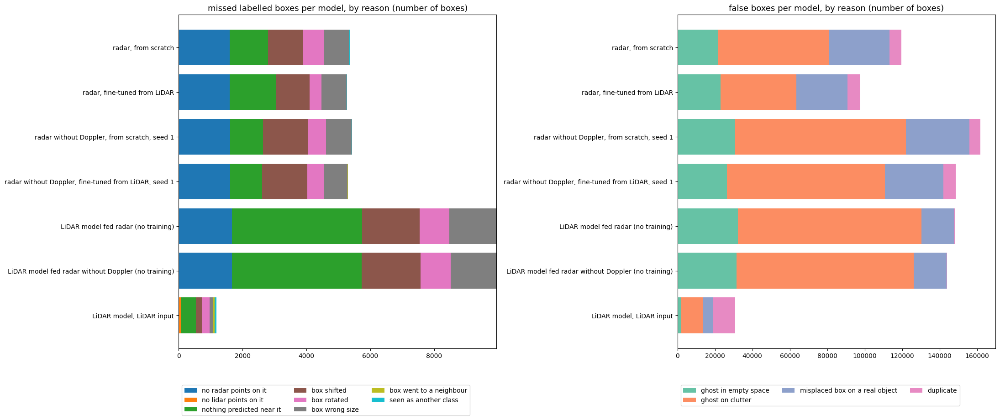

The same per weather (missed boxes, share of each reason):


reason_group                           box rotated  box shifted  box went to a neighbour  box wrong size  no lidar points on it  no radar points on it  nothing predicted near it  seen as another class
model                      weather                                                                                                                                                                      
livox_e20_on_radar         Clear               9.0         17.0                      0.0            14.0                    0.0                   17.0                       43.0                    0.0
                           Fog                 9.0         37.0                      0.0            15.0                    0.0                    3.0                       36.0                    0.0
                           Heavy_Rain         12.0         18.0                      0.0            25.0                    0.0                   16.0                       28.0                    0.0
                           Heavy_Snow         18.0         18.0                      0.0            14.0                    0.0                   17.0                       33.0                    0.0
                           Light_Rain         10.0         16.0                      0.0            10.0                    0.0                   24.0                       40.0                    0.0
                           Light_Snow          5.0         15.0                      0.0            13.0                    0.0                   14.0                       53.0                    0.0
livox_e20_on_radar_xyz     Clear               9.0         18.0                      0.0            14.0                    0.0                   17.0                       43.0                    0.0
                           Fog                 9.0         38.0                      0.0            13.0                    0.0                    3.0                       37.0                    0.0
                           Heavy_Rain         12.0         18.0                      0.0            25.0                    0.0                   16.0                       29.0                    0.0
                           Heavy_Snow         15.0         20.0                      0.0            14.0                    0.0                   17.0                       34.0                    0.0
                           Light_Rain         11.0         17.0                      0.0             9.0                    0.0                   24.0                       39.0                    0.0
                           Light_Snow          7.0         15.0                      0.0            14.0                    0.0                   14.0                       50.0                    0.0
livox_pretrain             Clear              18.0         10.0                      5.0            11.0                    1.0                    0.0                       49.0                    5.0
                           Fog                 5.0         23.0                      0.0            22.0                   43.0                    0.0                        7.0                    0.0
                           Heavy_Rain         20.0         36.0                      0.0             0.0                    6.0                    0.0                       38.0                    0.0
                           Heavy_Snow         10.0         15.0                      0.0            35.0                   15.0                    0.0                       25.0                    0.0
                           Light_Rain         57.0          1.0                     13.0             6.0                    0.0                    0.0                       15.0                    8.0
                           Light_Snow         37.0          4.0                      0.0            18.0                    0.0                    0.0                       41.0    

In [7]:
def miss_reason(m, g, cut):
    "Why model m missed labelled box g (a row of GT) at score cut-off `cut`: (reason, IoU of the closest box)."
    k, j = g.k, g.j
    gb = F["gt_box"][part("gt", k)][j]
    s = part("pred_" + m, k)
    pb, ps, pc = F["pred_%s_box" % m][s], F["pred_%s_score" % m][s], F["pred_%s_cls" % m][s]
    I = IOU[m, k][:, j] if len(pb) else np.zeros(0)
    same = pc == CLASSES.index(g.cls) + 1
    near = np.hypot(pb[:, 0] - gb[0], pb[:, 1] - gb[1]) < 4 if len(pb) else np.zeros(0, bool)
    pts = g.radar_pts if SENSOR[m] == "radar" else g.lidar_pts
    if (same & (I >= IOU_THR[g.cls]) & (ps < cut)).any():
        return "right box, score too low", float(I[same & (ps < cut)].max())
    if pts == 0:
        return "no %s points on it" % SENSOR[m], np.nan
    cand = np.flatnonzero(same & near & (ps >= cut))
    if len(cand):
        i = cand[np.argmax(I[cand])]
        if STATUS[m, k][i] in ("TP", "IGNORED") and I[i] < IOU_THR[g.cls]:
            return "box went to a neighbour", float(I[i])
        shift = np.hypot(*(pb[i][:2] - gb[:2]))
        turn = np.degrees(abs((pb[i][6] - gb[6] + np.pi / 2) % np.pi - np.pi / 2))
        size = max(abs(pb[i][3] - gb[3]) / gb[3], abs(pb[i][4] - gb[4]) / gb[4])
        worst = max([(shift / 1.0, "box shifted %.1f m" % shift), (turn / 20, "box rotated %.0f deg" % turn),
                     (size / 0.25, "box wrong size (%.0f%%)" % (100 * size))])
        return worst[1], float(I[i])
    if ((~same) & (I >= 0.3) & (ps >= cut)).any():
        return "seen as another class", np.nan
    if (near & (ps < cut)).any():
        return "only a weak guess nearby", float(I[near].max())
    return "nothing predicted near it", float(I.max()) if len(I) else 0.0

def false_reason(row):
    "Why a false box (row of PRED with status FP) is false."
    I = IOU[row.model, row.k][row.i]
    same = F["gt_cls"][part("gt", row.k)] == CLASSES.index(row.cls) + 1
    if (same & (I >= IOU_THR[row.cls])).any():      # right place, but that object was already taken
        return "duplicate"
    if row.best_iou >= 0.1:
        return "misplaced box on a real object"
    return "ghost on clutter" if row.pts_inside > 0 else "ghost in empty space"

def explain(cut=None):
    cut = cut or CUT
    miss = []
    for m in MAIN:
        p = PRED[(PRED.model == m) & (PRED.score >= cut[m]) & PRED.status.isin(["TP", "IGNORED"])]
        found = set(zip(p.k, p.matched_gt))
        for g in GT[GT.level == 1].itertuples():
            if (g.k, g.j) not in found:
                r, iou = miss_reason(m, g, cut[m])
                miss.append((m, g.k, g.j, r, re.sub(r" [0-9.]+ ?(m|deg)$| \([0-9]+%\)$", "", r), iou))
    MISS = pd.DataFrame(miss, columns=["model", "k", "j", "reason", "reason_group", "iou"]).merge(
        GT, on=["k", "j"])
    f = PRED[PRED.model.isin(MAIN) & PRED.status.eq("FP") & (PRED.score >= PRED.model.map(cut))].copy()
    f["reason_group"] = [false_reason(r) for r in f.itertuples()]
    return MISS, f

MISS, FALSE = explain()
order_m = ["no radar points on it", "no lidar points on it", "nothing predicted near it", "only a weak guess nearby",
           "right box, score too low", "box shifted", "box rotated", "box wrong size", "box went to a neighbour",
           "seen as another class"]
order_f = ["ghost in empty space", "ghost on clutter", "misplaced box on a real object", "duplicate"]
tab_m = MISS.groupby(["model", "reason_group"]).size().unstack(fill_value=0)
tab_f = FALSE.groupby(["model", "reason_group"]).size().unstack(fill_value=0)
print("MISSED labelled boxes, by reason (all classes, level 1):")
display(tab_m.reindex(columns=[c for c in order_m if c in tab_m.columns]))
print("FALSE boxes, by reason:")
display(tab_f.reindex(columns=[c for c in order_f if c in tab_f.columns]))

REASON_COLOR = dict(zip(order_m + order_f, list(plt.cm.tab10.colors) + list(plt.cm.Set2.colors)))
fig, axes = plt.subplots(1, 2, figsize=(22, 0.9 * len(MAIN) + 3))
for ax, tab, order, title in [(axes[0], tab_m, order_m, "missed labelled boxes"), (axes[1], tab_f, order_f, "false boxes")]:
    cols = [c for c in order if c in tab.columns]
    t = tab.reindex(index=MAIN, columns=cols).fillna(0)
    left = np.zeros(len(t))
    for c in cols:
        ax.barh([NAME.get(m, m) for m in t.index], t[c], left=left, color=REASON_COLOR[c], label=c)
        left += t[c].values
    ax.set_title(title + " per model, by reason (number of boxes)", fontsize=13)
    ax.legend(fontsize=10, bbox_to_anchor=(0, -0.1), loc="upper left", ncol=3)
    ax.invert_yaxis()
plt.tight_layout(); plt.show()

print("The same per weather (missed boxes, share of each reason):")
display((MISS.groupby(["model", "weather", "reason_group"]).size().unstack(fill_value=0)
         .pipe(lambda t: t.div(t.sum(1), axis=0) * 100).round(0)))

## 3b. Recall by angle: do the radar models lose objects at the sides?

**Angle** = direction of a labelled box's centre seen from the Livox: 0° = straight ahead, + = left, − = right.
The sensors see different widths (DSERT-RoLL sensor table): the **radar** (RETINA-4FN) about **±50°**, the **Livox**
about **±60°**, while the models' point range lets boxes reach ±90°. If the radar's narrower view costs detections,
then beyond ~50°:
* the share of labelled boxes with **no radar point** on them goes up, and
* the **recall** (share of labelled boxes found, counting every box the model output) of the radar models drops
  while the LiDAR model's holds up to ~60°.

Wide-angle objects are mostly close by, and close objects are easier, so the second table splits by distance too.
The last tables say *why* the radar models miss at each angle (section 3's reasons) and where their false boxes sit.
Small bins (few boxes) are noisy: the `boxes` column says how many there are.

Labelled boxes (Vehicle, Pedestrian, Bike, level 1) by |angle|: share with points on them, and recall


,boxes,with_radar_pts,with_lidar_pts,recall radar_scratch,recall radar_ft_from_livox,recall livox_e20_on_radar,recall livox_pretrain,ft - scratch
angle_bin,,,,,,,,
0-10°,6821,87%,99%,54%,56%,8%,92%,+1%
10-20°,2125,85%,100%,48%,47%,6%,88%,-1%
20-30°,885,79%,99%,36%,37%,6%,79%,+1%
30-40°,414,75%,100%,39%,41%,8%,85%,+2%
40-50°,261,74%,100%,36%,38%,5%,82%,+2%
50-60°,175,51%,99%,15%,18%,3%,75%,+3%
60-90°,28,50%,100%,25%,21%,0%,79%,-4%


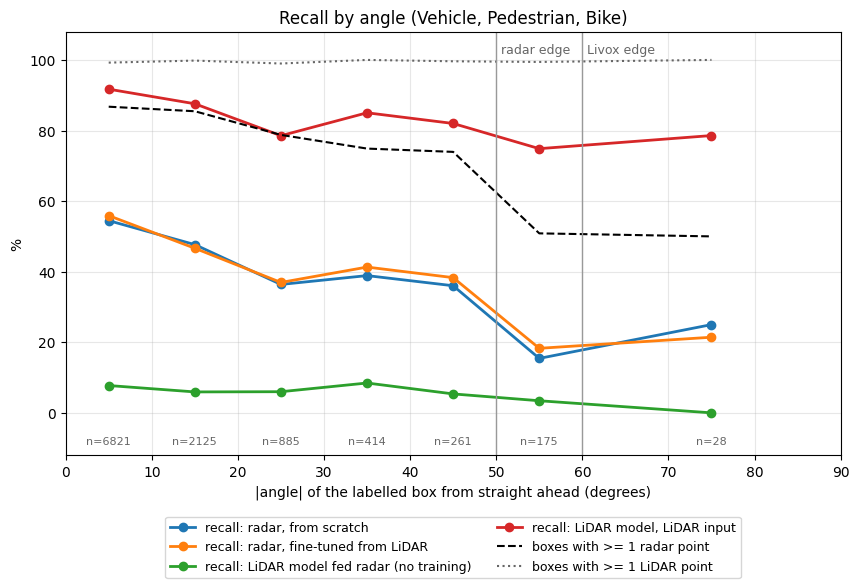

Recall by |angle| and distance, 'recall (boxes)':


angle_bin                                          0-10°     10-20°     20-30°     30-40°     40-50°     50-60°    60-90°
model                               distance                                                                             
radar, from scratch                 0-20m      67% (414)  57% (817)  46% (519)  46% (287)  41% (198)  20% (128)  26% (27)
                                    20-40m    64% (2978)  49% (912)  36% (212)  27% (109)   19% (63)    2% (47)    0% (1)
                                    40-70m    44% (3429)  26% (396)   3% (154)    6% (18)          -          -         -
radar, fine-tuned from LiDAR        0-20m      74% (414)  53% (817)  48% (519)  48% (287)  44% (198)  24% (128)  22% (27)
                                    20-40m    65% (2978)  50% (912)  36% (212)  28% (109)   19% (63)    2% (47)    0% (1)
                                    40-70m    46% (3429)  26% (396)   2% (154)    6% (18)          -          -         -
LiDAR model fed radar (no training) 0-20m       8% (414)   7% (817)   9% (519)  10% (287)   7% (198)   5% (128)   0% (27)
                                    20-40m     8% (2978)   6% (912)   3% (212)   4% (109)    2% (63)    0% (47)    0% (1)
                                    40-70m     7% (3429)   4% (396)   1% (154)    6% (18)          -          -         -
LiDAR model, LiDAR input            0-20m     100% (414)  91% (817)  91% (519)  94% (287)  87% (198)  84% (128)  81% (27)
                                    20-40m    94% (2978)  88% (912)  82% (212)  76% (109)   67% (63)   49% (47)    0% (1)
                                    40-70m    89% (3429)  79% (396)  33% (154)    0% (18)          -          -         -


radar, from scratch: why labelled boxes were missed, per |angle| (share of the misses in that bin, number of misses)


reason_group,no radar points on it,nothing predicted near it,box shifted,box rotated,box wrong size,box went to a neighbour,seen as another class,misses
angle_bin,,,,,,,,
0-10°,27.0,17.0,25.0,12.0,19.0,0.0,0.0,3106
10-20°,27.0,29.0,18.0,12.0,13.0,0.0,1.0,1112
20-30°,33.0,33.0,12.0,14.0,8.0,0.0,0.0,563
30-40°,41.0,26.0,11.0,15.0,7.0,0.0,0.0,253
40-50°,41.0,31.0,11.0,11.0,5.0,0.0,1.0,167
50-60°,57.0,28.0,9.0,2.0,3.0,0.0,0.0,148
60-90°,67.0,14.0,5.0,10.0,5.0,0.0,0.0,21



radar, fine-tuned from LiDAR: why labelled boxes were missed, per |angle| (share of the misses in that bin, number of misses)


reason_group,no radar points on it,nothing predicted near it,box shifted,box rotated,box wrong size,box went to a neighbour,seen as another class,misses
angle_bin,,,,,,,,
0-10°,28.0,22.0,25.0,7.0,18.0,0.0,0.0,3009
10-20°,26.0,37.0,17.0,7.0,13.0,0.0,0.0,1134
20-30°,34.0,36.0,10.0,9.0,10.0,1.0,0.0,558
30-40°,43.0,27.0,12.0,12.0,5.0,1.0,1.0,243
40-50°,42.0,34.0,9.0,6.0,9.0,0.0,0.0,161
50-60°,59.0,29.0,6.0,1.0,5.0,0.0,0.0,143
60-90°,64.0,9.0,14.0,9.0,5.0,0.0,0.0,22



LiDAR model fed radar (no training): why labelled boxes were missed, per |angle| (share of the misses in that bin, number of misses)


reason_group,no radar points on it,nothing predicted near it,box shifted,box rotated,box wrong size,box went to a neighbour,misses
angle_bin,,,,,,,
0-10°,14.0,35.0,20.0,11.0,20.0,0.0,6293
10-20°,15.0,50.0,19.0,8.0,8.0,0.0,1999
20-30°,23.0,56.0,12.0,7.0,3.0,0.0,832
30-40°,27.0,53.0,12.0,7.0,1.0,0.0,379
40-50°,28.0,53.0,11.0,8.0,0.0,0.0,247
50-60°,51.0,38.0,6.0,5.0,0.0,0.0,169
60-90°,50.0,25.0,21.0,4.0,0.0,0.0,28



False boxes per 100 frames, by |angle| of the false box:


angle_bin,0-10°,10-20°,20-30°,30-40°,40-50°,50-60°,60-90°
model,,,,,,,
radar_scratch,951.4,481.6,296.9,196.7,123.1,40.4,31.4
radar_ft_from_livox,869.6,387.7,195.1,129.3,94.1,38.3,18.8
livox_e20_on_radar,1217.7,766.3,369.0,175.2,82.3,15.0,2.1
livox_pretrain,286.3,97.6,39.8,63.5,25.6,18.8,14.5



116 wide-angle (>= 50 deg) boxes found by the LiDAR model but missed by the fine-tuned radar model. Draw one after running section 4 with show(k), e.g. k in [111, 112, 113, 153, 162, 163, 164, 165, 166, 167]


In [8]:
ANGLE_BINS = [0, 10, 20, 30, 40, 50, 60, 90]        # |angle| in degrees
ANGLE_CLASSES = CLASSES                              # e.g. ["Vehicle"] for cars only
DIST_BINS = [0, 20, 40, 70.5]
RADAR_HALF_FOV, LIDAR_HALF_FOV = 50, 60              # RETINA-4FN 100 deg wide, Livox HAP 120 deg wide
A_MODELS = [m for m in ["radar_scratch", "radar_ft_from_livox", "livox_e20_on_radar", "livox_pretrain"] if m in MODELS]
bin_names = ["%d-%d°" % (a, b) for a, b in zip(ANGLE_BINS[:-1], ANGLE_BINS[1:])]

def box_angle(boxes):
    return np.degrees(np.arctan2(boxes[:, 1], boxes[:, 0]))

# Angle and distance of every labelled box (GT row k, j = box j of frame k)
gb_all = F["gt_box"][F["gt_off"][GT.k.values] + GT.j.values]
GT["angle"] = box_angle(gb_all)
G = GT[(GT.level == 1) & GT.cls.isin(ANGLE_CLASSES)].copy()
G["angle_bin"] = pd.cut(G.angle.abs(), ANGLE_BINS, right=False, labels=bin_names)
G["dist_bin"] = pd.cut(G.dist, DIST_BINS, right=False, labels=["%d-%dm" % (a, b) for a, b in zip(DIST_BINS[:-1], [20, 40, 70])])

def found_at_cut(m, cut=None):
    "True for each row of G that model m found (with any box, or above CUT if you raised it in section 2)."
    cut = cut or CUT
    p = PRED[(PRED.model == m) & (PRED.score >= cut[m]) & PRED.status.isin(["TP", "IGNORED"])]
    found = set(zip(p.k, p.matched_gt))
    return np.array([(k, j) in found for k, j in zip(G.k, G.j)])

for m in A_MODELS:
    G["found_" + m] = found_at_cut(m)

# 1. Recall per angle bin, next to how many boxes have any radar / LiDAR point on them
t = G.groupby("angle_bin", observed=False).agg(boxes=("k", "size"),
                                               with_radar_pts=("radar_pts", lambda x: (x > 0).mean()))
if (G.lidar_pts >= 0).any():
    t["with_lidar_pts"] = G.groupby("angle_bin", observed=False).lidar_pts.apply(lambda x: (x > 0).mean())
for m in A_MODELS:
    t["recall " + m] = G.groupby("angle_bin", observed=False)["found_" + m].mean()
if {"radar_scratch", "radar_ft_from_livox"} <= set(A_MODELS):
    t["ft - scratch"] = t["recall radar_ft_from_livox"] - t["recall radar_scratch"]
print("Labelled boxes (%s, level 1) by |angle|: share with points on them, and recall"
      % ", ".join(ANGLE_CLASSES))
display(t.style.format({c: "{:.0%}" for c in t.columns if c != "boxes"} | {"ft - scratch": "{:+.0%}"}))

fig, ax = plt.subplots(figsize=(10, 5.5))
mid = (np.array(ANGLE_BINS[:-1]) + np.array(ANGLE_BINS[1:])) / 2
for m in A_MODELS:
    ax.plot(mid, 100 * t["recall " + m].values, "-o", lw=2, label="recall: " + NAME.get(m, m))
ax.plot(mid, 100 * t.with_radar_pts.values, "k--", lw=1.5, label="boxes with >= 1 radar point")
if "with_lidar_pts" in t:
    ax.plot(mid, 100 * t.with_lidar_pts.values, ":", c="0.4", lw=1.5, label="boxes with >= 1 LiDAR point")
for x, name in [(RADAR_HALF_FOV, "radar edge"), (LIDAR_HALF_FOV, "Livox edge")]:
    ax.axvline(x, c="0.6", lw=1)
    ax.text(x + 0.5, 101, name, fontsize=9, color="0.4", va="bottom")
for x, n in zip(mid, t.boxes.values):
    ax.text(x, -9, "n=%d" % n, ha="center", fontsize=8, color="0.4")
ax.set_xlabel("|angle| of the labelled box from straight ahead (degrees)"); ax.set_ylabel("%")
ax.set_ylim(-12, 108); ax.set_xlim(0, 90); ax.grid(alpha=.3)
ax.legend(fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
ax.set_title("Recall by angle (%s)" % ", ".join(ANGLE_CLASSES)); plt.show()

# 2. The same split by distance (wide angles are mostly close, which is easier)
print("Recall by |angle| and distance, 'recall (boxes)':")
tabs = {}
for m in A_MODELS:
    g = G.groupby(["dist_bin", "angle_bin"], observed=False)["found_" + m].agg(["mean", "size"])
    cell = g.apply(lambda r: "%.0f%% (%d)" % (100 * r["mean"], r["size"]) if r["size"] else "-", axis=1)
    tabs[NAME.get(m, m)] = cell.unstack("angle_bin").reindex(columns=bin_names)
display(pd.concat(tabs, names=["model", "distance"]))

# 3. Why the radar models miss, per angle bin (share of each section-3 reason)
M = MISS.merge(G[["k", "j", "angle_bin"]], on=["k", "j"])
for m in [m for m in A_MODELS if SENSOR[m] == "radar"]:
    tab = M[M.model == m].groupby(["angle_bin", "reason_group"], observed=False).size().unstack(fill_value=0)
    tab = tab.reindex(columns=[c for c in order_m if c in tab.columns])
    print("\n%s: why labelled boxes were missed, per |angle| (share of the misses in that bin, number of misses)"
          % NAME.get(m, m))
    display(tab.div(tab.sum(1).replace(0, np.nan), axis=0).mul(100).round(0).assign(misses=tab.sum(1)))

# 4. Where the false boxes are: per angle bin, false boxes per 100 frames (angle of the predicted box)
fa = []
for r in FALSE.itertuples():
    b = F["pred_%s_box" % r.model][F["pred_%s_off" % r.model][r.k] + r.i]
    fa.append(abs(box_angle(b[None])[0]))
FALSE["angle_bin"] = pd.cut(fa, ANGLE_BINS, right=False, labels=bin_names) if len(fa) else []
print("\nFalse boxes per 100 frames, by |angle| of the false box:")
display((FALSE.groupby(["model", "angle_bin"], observed=False).size().unstack(fill_value=0) * 100 / N).round(1)
        .reindex(A_MODELS))

# 5. Frames to look at: wide-angle boxes the LiDAR model found but the fine-tuned radar model missed
if {"radar_ft_from_livox", "livox_pretrain"} <= set(A_MODELS):
    WIDE = G[(G.angle.abs() >= RADAR_HALF_FOV) & G.found_livox_pretrain & ~G.found_radar_ft_from_livox]
    print("\n%d wide-angle (>= %d deg) boxes found by the LiDAR model but missed by the fine-tuned radar model."
          % (len(WIDE), RADAR_HALF_FOV), "Draw one after running section 4 with show(k), e.g. k in",
          [int(k) for k in sorted(WIDE.k.unique())[:10]])

## 3c. Labelled boxes the radar cannot see at all

Boxes with **not one radar point** on them (the radar points the models saw: moved into LiDAR coordinates, inside the
point range). The radar models have nothing to go on for these, so they cap radar recall. The cell prints:
1. **how many**: boxes, frames they are in, frames where no labelled box has a radar point, frames where the radar
   returned nothing at all
2. **found anyway**: per model, how many of these boxes it still matched (IoU and score of the hit), next to its
   recall on boxes that do have radar points. The LiDAR model is the reference: the object is there, the radar just
   did not see it
3. **per weather**: frames, boxes, zero-point boxes, and found-anyway per model, all as numbers
4. **what kind of boxes**: class, distance, angle, LiDAR points on the box (0 LiDAR points too = probably hidden or a
   doubtful label)
5. **drives** with the most of them
6. **frames to look at** with `show(k)`, including every zero-point box a radar model still found

In [9]:
# Labelled boxes with NO radar point on them (after moving radar into LiDAR coordinates and the point-range cut,
# exactly the points the radar models saw). For these the radar models have nothing to see.
# Needs sections 1 (F, FR, GT) and 3 (MISS) to have run.
L1 = GT[GT.level == 1].copy()
gb = F["gt_box"][F["gt_off"][L1.k.values] + L1.j.values]
L1["angle"] = np.degrees(np.arctan2(gb[:, 1], gb[:, 0]))
L1["zero"] = L1.radar_pts == 0
n_radar = pd.Series(np.diff(F["radar_off"]), name="radar_pts_in_frame")      # radar points per frame (all of them)
fr = L1.groupby("k").agg(boxes=("j", "size"), zero=("zero", "sum")).join(n_radar).join(FR)
fr["all_zero"] = fr.zero == fr.boxes                                          # not one labelled box has a radar point
fr["radar_empty"] = fr.radar_pts_in_frame == 0                                # the radar gave no points at all
Z = L1[L1.zero].copy()

# Which model found which box (matched by one of its boxes, every box counted), with that box's IoU and score
HIT = {}
for m in MAIN:
    p = PRED[(PRED.model == m) & (PRED.score >= CUT[m]) & PRED.status.isin(["TP", "IGNORED"])]
    HIT[m] = {(r.k, r.matched_gt): (float(IOU[m, r.k][r.i, r.matched_gt]), r.score) for r in p.itertuples()}
    L1["found_" + m] = [(k, j) in HIT[m] for k, j in zip(L1.k, L1.j)]
    Z["found_" + m] = L1.loc[Z.index, "found_" + m]

# Radar points close to each zero-point box (centre within 5 m): what a radar model could have guessed from
def radar_near(k, j, r=5.0):
    b = F["gt_box"][part("gt", k)][j]
    p = F["radar_pts"][part("radar", k)]
    return int((np.hypot(p[:, 0] - b[0], p[:, 1] - b[1]) < r).sum())
Z["radar_within_5m"] = [radar_near(k, j) for k, j in zip(Z.k, Z.j)]

print("1. HOW MANY")
print("   %d of %d labelled boxes (%.1f%%) have no radar point on them."
      % (len(Z), len(L1), 100 * len(Z) / len(L1)))
print("   They are in %d of the %d frames with labelled boxes (%.1f%%): %s."
      % ((fr.zero > 0).sum(), len(fr), 100 * (fr.zero > 0).mean(),
         ", ".join("%d frames with %d such box%s" % (v, n, "" if n == 1 else "es")
                   for n, v in fr.loc[fr.zero > 0, "zero"].value_counts().sort_index().items())))
print("   In %d frames NOT ONE labelled box has a radar point. In %d frames the radar returned no point at all "
      "(%d zero-point boxes are in those)." % (fr.all_zero.sum(), fr.radar_empty.sum(), fr.loc[fr.radar_empty, "zero"].sum()))

print("\n2. FOUND ANYWAY: labelled boxes with no radar point that a model still matched (every box counted)")
rows = []
for m in MAIN:
    f = Z[Z["found_" + m]]
    hits = [HIT[m][k, j] for k, j in zip(f.k, f.j)]
    with_pts = L1[~L1.zero]
    rows.append({"model": NAME.get(m, m), "sees": SENSOR[m],
                 "found (of %d zero-point boxes)" % len(Z): len(f),
                 "recall on zero-point boxes": "%.1f%%" % (100 * len(f) / max(len(Z), 1)),
                 "recall on boxes WITH radar points": "%.1f%%" % (100 * with_pts["found_" + m].mean()),
                 "median IoU of the hit": round(float(np.median([h[0] for h in hits])), 2) if hits else np.nan,
                 "median score of the hit": round(float(np.median([h[1] for h in hits])), 2) if hits else np.nan})
display(pd.DataFrame(rows).set_index("model"))
print("   Radar points within 5 m of the zero-point boxes: found by a radar model %s, missed by both radar models %s"
      % ("median %.0f" % Z[Z.found_radar_scratch | Z.found_radar_ft_from_livox].radar_within_5m.median()
         if (Z.found_radar_scratch | Z.found_radar_ft_from_livox).any() else "none found",
         "median %.0f" % Z[~Z.found_radar_scratch & ~Z.found_radar_ft_from_livox].radar_within_5m.median()))

print("\n3. PER WEATHER (numbers, then found-anyway per model)")
w = fr.groupby("weather").agg(frames=("boxes", "size"), frames_with_zero=("zero", lambda x: (x > 0).sum()),
                              frames_all_zero=("all_zero", "sum"), frames_radar_empty=("radar_empty", "sum"),
                              boxes=("boxes", "sum"), zero_boxes=("zero", "sum"),
                              median_radar_pts_per_frame=("radar_pts_in_frame", "median"))
w["% of boxes zero"] = (100 * w.zero_boxes / w.boxes).round(1)
w["% of all zero boxes"] = (100 * w.zero_boxes / max(len(Z), 1)).round(1)
for m in MAIN:
    w["found: " + m] = Z.groupby("weather")["found_" + m].sum().reindex(w.index).fillna(0).astype(int)
display(w.reindex([x for x in WEATHERS if x in w.index]))

print("\n4. WHAT KIND OF BOXES (how many have no radar point, and how many each model still found)")
for name, col in [("class", L1.cls),
                  ("distance", pd.cut(L1.dist, [0, 10, 20, 40, 70.5], right=False)),
                  ("|angle| (radar sees about +-50 deg)", pd.cut(L1.angle.abs(), [0, 30, 50, 60, 90], right=False)),
                  ("LiDAR points on the box", pd.cut(L1.lidar_pts, [-1, 0, 10, 100, 1e9], right=True,
                                                     labels=["0", "1-10", "11-100", ">100"]))]:
    g = L1.groupby(col, observed=False)
    t = g.zero.agg(boxes="size", zero_boxes="sum")
    t["% zero"] = (100 * t.zero_boxes / t.boxes.replace(0, np.nan)).round(1)
    for m in MAIN:
        t["found: " + m] = L1[L1.zero].groupby(col[L1.zero], observed=False)["found_" + m].sum().reindex(t.index).fillna(0).astype(int)
    print("  by", name); display(t)

print("\n5. DRIVES with the most zero-point boxes")
d = fr.groupby(["drive", "weather"]).agg(frames=("boxes", "size"), frames_with_zero=("zero", lambda x: (x > 0).sum()),
                                         boxes=("boxes", "sum"), zero_boxes=("zero", "sum"),
                                         radar_empty_frames=("radar_empty", "sum"))
d["% of boxes zero"] = (100 * d.zero_boxes / d.boxes).round(1)
display(d.sort_values("zero_boxes", ascending=False).head(12))

print("\n6. FRAMES TO LOOK AT with show(k)")
ZERO_FRAMES = fr[fr.zero > 0].sort_values("zero", ascending=False)
print("   most zero-point boxes:", [int(k) for k in ZERO_FRAMES.index[:10]])
for m in [m for m in MAIN if SENSOR[m] == "radar"]:
    f = Z[Z["found_" + m]]
    print("   zero-point boxes %s still found:" % NAME.get(m, m))
    if len(f):
        display(f.assign(iou=[HIT[m][k, j][0] for k, j in zip(f.k, f.j)],
                         score=[HIT[m][k, j][1] for k, j in zip(f.k, f.j)])
                [["k", "j", "drive", "sample", "weather", "cls", "dist", "angle", "lidar_pts", "radar_within_5m",
                  "iou", "score"]].round(2).sort_values("score", ascending=False).head(15))
    else:
        print("   none")

1. HOW MANY
   1673 of 10709 labelled boxes (15.6%) have no radar point on them.
   They are in 1312 of the 5237 frames with labelled boxes (25.1%): 1005 frames with 1 such box, 256 frames with 2 such boxes, 48 frames with 3 such boxes, 3 frames with 4 such boxes.
   In 240 frames NOT ONE labelled box has a radar point. In 0 frames the radar returned no point at all (0 zero-point boxes are in those).

2. FOUND ANYWAY: labelled boxes with no radar point that a model still matched (every box counted)


,sees,found (of 1673 zero-point boxes),recall on zero-point boxes,recall on boxes WITH radar points,median IoU of the hit,median score of the hit
model,,,,,,
"radar, from scratch",radar,75,4.5%,58.3%,0.63,0.25
"radar, fine-tuned from LiDAR",radar,69,4.1%,59.4%,0.60,0.31
"radar without Doppler, from scratch, seed 1",radar,65,3.9%,57.7%,0.62,0.14
"radar without Doppler, fine-tuned from LiDAR, seed 1",radar,63,3.8%,59.2%,0.62,0.15
LiDAR model fed radar (no training),radar,4,0.2%,8.4%,0.53,0.07
LiDAR model fed radar without Doppler (no training),radar,4,0.2%,8.3%,0.53,0.07
"LiDAR model, LiDAR input",lidar,1154,69.0%,92.7%,0.70,0.38


   Radar points within 5 m of the zero-point boxes: found by a radar model median 12, missed by both radar models median 10

3. PER WEATHER (numbers, then found-anyway per model)


,frames,frames_with_zero,frames_all_zero,frames_radar_empty,boxes,zero_boxes,median_radar_pts_per_frame,% of boxes zero,% of all zero boxes,found: radar_scratch,found: radar_ft_from_livox,found: radar_scratch_xyz_s1,found: radar_ft_from_livox_xyz_s1,found: livox_e20_on_radar,found: livox_e20_on_radar_xyz,found: livox_pretrain
weather,,,,,,,,,,,,,,,,
Clear,3121,895,127,0,6993,1127,872.0,16.1,67.4,62,55,51,49,3,3,795
Light_Rain,463,159,35,0,1106,242,960.0,21.9,14.5,7,9,6,6,1,1,199
Heavy_Rain,496,116,10,0,1024,153,459.5,14.9,9.1,1,1,4,3,0,0,47
Fog,481,17,8,0,598,17,629.0,2.8,1.0,1,1,2,1,0,0,10
Light_Snow,453,75,21,0,653,84,636.0,12.9,5.0,0,0,0,1,0,0,63
Heavy_Snow,223,50,39,0,335,50,271.0,14.9,3.0,4,3,2,3,0,0,40



4. WHAT KIND OF BOXES (how many have no radar point, and how many each model still found)
  by class


,boxes,zero_boxes,% zero,found: radar_scratch,found: radar_ft_from_livox,found: radar_scratch_xyz_s1,found: radar_ft_from_livox_xyz_s1,found: livox_e20_on_radar,found: livox_e20_on_radar_xyz,found: livox_pretrain
cls,,,,,,,,,,
Bike,214,40,18.7,0,0,0,0,0,0,19
Pedestrian,1192,599,50.3,0,1,0,0,0,0,345
Vehicle,9303,1034,11.1,75,68,65,63,4,4,790


... (16 outputs left out)

   zero-point boxes LiDAR model fed radar (no training) still found:


,k,j,drive,sample,weather,cls,dist,angle,lidar_pts,radar_within_5m,iou,score
9292,4900,1,2025_07_16_14_24_33,119,Light_Rain,Vehicle,40.570000,-4.27,22,7,0.54,0.19
2631,1402,0,2025_04_14_03_02_53,104,Clear,Vehicle,26.980000,6.51,520,13,0.51,0.10
6280,3484,0,2025_07_04_15_55_05,44,Clear,Vehicle,50.660000,-6.72,77,3,0.50,0.03
6944,3818,0,2025_07_04_17_10_48,28,Clear,Vehicle,38.919998,0.48,156,6,0.55,0.03


   zero-point boxes LiDAR model fed radar without Doppler (no training) still found:


,k,j,drive,sample,weather,cls,dist,angle,lidar_pts,radar_within_5m,iou,score
9292,4900,1,2025_07_16_14_24_33,119,Light_Rain,Vehicle,40.570000,-4.27,22,7,0.55,0.19
2631,1402,0,2025_04_14_03_02_53,104,Clear,Vehicle,26.980000,6.51,520,13,0.52,0.10
6944,3818,0,2025_07_04_17_10_48,28,Clear,Vehicle,38.919998,0.48,156,6,0.55,0.04
6280,3484,0,2025_07_04_15_55_05,44,Clear,Vehicle,50.660000,-6.72,77,3,0.51,0.03


## 4. Look at frames

`show(frame)` draws one frame for the given models side by side:
* top row, three pictures: the **camera image as it is**; the same with **only the LiDAR points** (small grey dots);
  the same with **only the radar points** (big dots, coloured by distance from the car: blue near, green/yellow
  middle, orange/red far, up to 70 m; colour bar underneath)
* per model: the camera image with the points of the sensor that model sees (radar for the radar models, LiDAR for
  the LiDAR model; `both_sensors=True` draws both) and all its boxes in 3D; below it the **top view** (both sensors);
  below that the **list** of every labelled object and every predicted box

Names: labelled objects are **L1, L2, ...**; the model's boxes are **a, b, c, ...** by score (a = highest).
Colours: labelled object **green** = found, **red** = missed; predicted box **blue** = **kept** (paired with a labelled
object, counts as correct, drawn as `c=L1`), **magenta** = **not kept** (a false box; the list says why: duplicate,
misplaced box, ghost on clutter, ghost in empty space).

"Kept" is the pairing with every box counted (score cut-off 0). The official AP redoes the pairing at every score
cut-off, so a stronger box can take the object at higher cut-offs: the line `paired at each cut-off` under each object
shows which box holds it from 0.00 to 1.00, e.g. `c 0.00-0.37, a 0.38-0.56, nobody 0.57-1.00`.

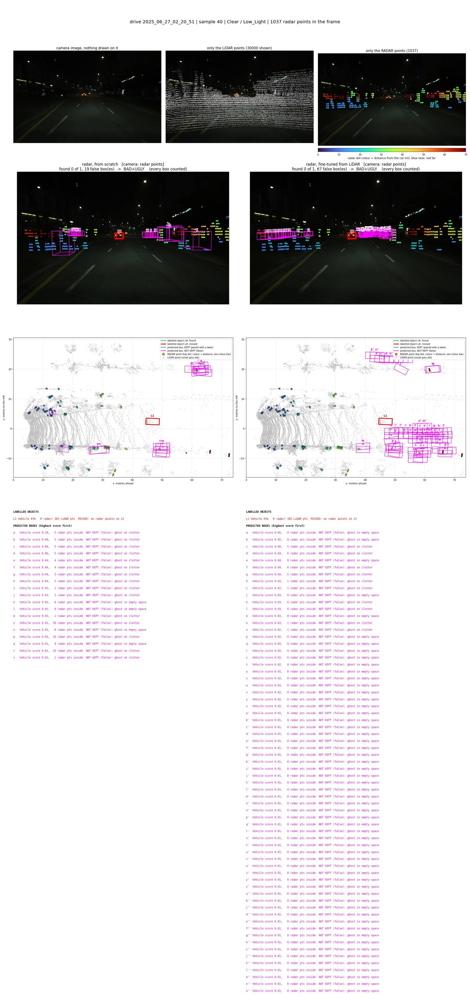

'/kaggle/working/pictures/4_frames/Clear_2025_06_27_02_20_51_s0040.jpg'

In [10]:
from matplotlib.lines import Line2D
from IPython.display import Image as ShowImage

# Every picture show() draws is saved as a .jpg under pictures/<folder>/ in the output folder (Kaggle: /kaggle/working,
# downloadable from the Output tab; zip_pictures() at the end puts them all in one pictures.zip).
PIC_DIR = os.path.join(OUT_DIR, "pictures")
SAVE_DPI = 80          # resolution of the saved pictures (80 -> about 2000 pixels wide for two models)
SHOW_WIDTH = 1400      # width of the copy shown in the notebook (pixels); the saved .jpg keeps SAVE_DPI
SHOW_WIDTH_MANY = 1600 # the same for pictures with more than 3 models side by side
INLINE_BYTES = [0]     # running total of the copies shown in the notebook (Kaggle's notebook download stops at 50 MB)

def zip_pictures():
    "All saved pictures -> pictures.zip in the output folder."
    out = os.path.join(OUT_DIR, "pictures.zip")
    files = [os.path.join(r, f) for r, _, fs in os.walk(PIC_DIR) for f in fs] if os.path.isdir(PIC_DIR) else []
    with zipfile.ZipFile(out, "w") as zf:
        for f in sorted(files):
            zf.write(f, os.path.relpath(f, PIC_DIR))
    print("%d pictures in %s" % (len(files), out))

# Per frame and model: labelled / found / false / missed, every box counted (the official lowest cut-off).
# Used for the picture titles and to pick frames in sections 5 and 6.
def frame_scores(cut=None):
    cut = cut or CUT
    rows = []
    for m in MODELS:
        p = PRED[(PRED.model == m) & (PRED.score >= cut[m])]
        tp = p[p.status == "TP"].groupby("k").size()
        fp = p[p.status == "FP"].groupby("k").size()
        n = GT[GT.level == 1].groupby("k").size()
        d = pd.DataFrame({"labelled": n, "found": tp, "false": fp}).reindex(range(N)).fillna(0).astype(int)
        d["missed"] = d.labelled - d.found
        d["verdict"] = np.select([(d.missed > 0) & (d.false > 0), d.missed > 0, d.false > 0],
                                 ["BAD+UGLY", "BAD", "UGLY"], "GOOD")
        d["model"] = m
        rows.append(d.reset_index().rename(columns={"index": "k"}))
    return pd.concat(rows, ignore_index=True).merge(FR, left_on="k", right_index=True)

S = frame_scores()

EDGES = [(0, 1), (1, 2), (2, 3), (3, 0), (4, 5), (5, 6), (6, 7), (7, 4), (0, 4), (1, 5), (2, 6), (3, 7)]
CMAP = plt.get_cmap("turbo")
COL = {"found": "limegreen", "missed": "red", "kept": "tab:blue", "not kept": "magenta", "below CUT": "0.6"}

def corners3d(b):
    c2 = bev_corners(b)
    return np.r_[np.c_[c2, np.full(4, b[2] - b[5] / 2)], np.c_[c2, np.full(4, b[2] + b[5] / 2)]]

def camera(k, max_width=1600):
    "The frame's colour image (shrunk to max_width) and the camera matrix for that size; (None, None) if missing."
    if not F["has_image"][k]:
        return None, None
    img = Image.open(str(F["img_path"][k])).convert("RGB")
    cw, ch = F["calib_wh"][k] if F["calib_wh"][k].min() > 0 else img.size   # size the calibration was made for
    if img.size[0] > max_width:
        img = img.resize((max_width, round(img.size[1] * max_width / img.size[0])))
    K = F["K"][k].copy()
    K[0] *= img.size[0] / cw
    K[1] *= img.size[1] / ch
    return img, (K, F["T_cam"][k])

def lidar_points(k, n=30000):
    "The frame's LiDAR points (a random n of them), read from the dataset when the frame is drawn."
    p = str(F["lidar_path"][k])
    pts = in_range(load_points(p, "intensity")) if p else np.zeros((0, 4))
    return pts if len(pts) <= n else pts[np.random.default_rng(0).choice(len(pts), n, replace=False)]

def to_image(xyz, cam):
    "LiDAR-frame points -> pixel (u, v) and depth in front of the camera; cam = (K, LiDAR->camera transform)."
    K, T = cam
    p = np.c_[xyz, np.ones(len(xyz))] @ T.T
    z = p[:, 2]
    uv = (p[:, :3] @ K.T)
    with np.errstate(divide="ignore", invalid="ignore"):
        return uv[:, 0] / z, uv[:, 1] / z, z

def draw_box(ax_cam, ax_bev, cam, b, color, lw, ls="-", label=None):
    x, y = np.r_[bev_corners(b), bev_corners(b)[:1]].T
    ax_bev.plot(x, y, color=color, lw=lw, ls=ls)
    if label:
        ax_bev.text(b[0], b[1] + b[4] / 2 + 0.6, label, color=color, fontsize=11, ha="center", fontweight="bold",
                    clip_on=True)
    if ax_cam is not None and cam is not None:
        u, v, z = to_image(corners3d(b), cam)
        if (z > 0.5).all():
            for a, c in EDGES:
                ax_cam.plot(u[[a, c]], v[[a, c]], color=color, lw=lw, ls=ls)
            if label:
                ax_cam.text(u[4:].mean(), v[4:].min() - 4, label, color=color, fontsize=11, ha="center",
                            fontweight="bold", bbox=dict(fc="white", alpha=.6, lw=0, pad=1), clip_on=True)

def box_names(m, k):
    "A name for every scored predicted box of model m in frame k: a, b, c, ... by score (highest first), then a', b', ..."
    p = PRED[(PRED.model == m) & (PRED.k == k) & (PRED.status != "OUT_OF_RANGE")].sort_values("score", ascending=False)
    return {r.i: chr(97 + n % 26) + "'" * (n // 26) for n, r in enumerate(p.itertuples())}

def owners_by_cutoff(m, k):
    "For each labelled box j of frame k: which predicted box is paired with it at each official score cut-off (-1: none)."
    s = part("pred_" + m, k)
    pb, ps, pc = F["pred_%s_box" % m][s], F["pred_%s_score" % m][s], F["pred_%s_cls" % m][s]
    gc = F["gt_cls"][part("gt", k)]
    inside = np.hypot(pb[:, 0], pb[:, 1]) < MAX_DIST
    own = np.full((len(CUTOFFS), len(gc)), -1)
    for ci, cut in enumerate(CUTOFFS):
        for c in np.unique(gc):
            pi, gj = np.flatnonzero(inside & (pc == c) & (ps >= cut)), np.flatnonzero(gc == c)
            if not len(pi):
                continue
            sub = IOU[m, k][np.ix_(pi, gj)]
            ok = sub >= IOU_THR[CLASSES[c - 1]]
            for r, q in zip(*linear_sum_assignment(np.where(ok, sub, 0.0), maximize=True)):
                if ok[r, q]:
                    own[ci, gj[q]] = pi[r]
    return own

def object_lines(m, k):
    """One line per labelled object (found or missed, by which box, and which box takes it as the score cut-off rises)
    and one line per predicted box (kept = paired with a labelled object at cut-off 0, or not kept and why)."""
    lines, names = [], box_names(m, k)
    g = GT[GT.k == k].sort_values("j")
    p = PRED[(PRED.model == m) & (PRED.k == k) & (PRED.status != "OUT_OF_RANGE")].sort_values("score", ascending=False)
    hit = {r.matched_gt: r for r in p[(p.score >= CUT[m]) & p.status.isin(["TP", "IGNORED"])].itertuples()}
    miss = MISS[(MISS.model == m) & (MISS.k == k)].set_index("j")
    own = owners_by_cutoff(m, k)
    lines.append(("LABELLED OBJECTS", "black"))
    for r in g.itertuples():
        head = "L%d %-7s %2.0fm %3d radar/%4d LiDAR pts" % (r.j + 1, r.cls[:7], r.dist, r.radar_pts, r.lidar_pts)
        if r.j in hit:
            h = hit[r.j]
            txt = "%s  FOUND by box %s (score %.2f, IoU %.2f)" % (head, names[h.i], h.score, IOU[m, k][h.i, r.j])
            color = "green"
        elif r.j in miss.index:
            mm = miss.loc[r.j]
            txt = "%s  MISSED: %s" % (head, mm.reason) + ("" if pd.isna(mm.iou) else ", IoU %.2f" % mm.iou)
            color = "red"
        else:
            txt, color = "%s  (level 2, not scored)" % head, "gray"
        runs, start = [], 0                                     # who holds this object as the cut-off rises
        for ci in range(1, len(CUTOFFS) + 1):
            if ci == len(CUTOFFS) or own[ci, r.j] != own[start, r.j]:
                runs.append("%s %.2f-%.2f" % (names.get(own[start, r.j], "nobody"), CUTOFFS[start], CUTOFFS[ci - 1]))
                start = ci
        if (own[:, r.j] >= 0).any():
            txt += "\n      paired at each cut-off: " + ", ".join(runs)
        lines.append((txt, color))
    lines.append(("PREDICTED BOXES (highest score first)", "black"))
    reason = FALSE[(FALSE.model == m) & (FALSE.k == k)].set_index("i").reason_group
    for r in p.itertuples():
        head = "%-3s %-7s score %.2f, %3d %s pts inside" % (names[r.i], r.cls[:7], r.score, r.pts_inside, SENSOR[m])
        if r.score < CUT[m]:
            lines.append(("%s  below CUT, hidden" % head, COL["below CUT"]))
        elif r.status == "TP":
            lines.append(("%s  KEPT: paired with L%d (IoU %.2f)" % (head, r.matched_gt + 1, IOU[m, k][r.i, r.matched_gt]),
                          COL["kept"]))
        elif r.status == "IGNORED":
            lines.append(("%s  on a level-2 label L%d, not scored" % (head, r.matched_gt + 1), "gray"))
        else:
            holds = [("L%d at cut-offs %.2f-%.2f" % (j + 1, CUTOFFS[np.flatnonzero(own[:, j] == r.i)].min(),
                                                     CUTOFFS[np.flatnonzero(own[:, j] == r.i)].max()))
                     for j in range(own.shape[1]) if (own[:, j] == r.i).any()]
            lines.append(("%s  NOT KEPT (false): %s" % (head, reason.get(r.i, "?"))
                          + ("; but holds " + ", ".join(holds) if holds else ""), COL["not kept"]))
    return lines

LEGEND = [Line2D([], [], color=COL["found"], lw=3, label="labelled object L#, found"),
          Line2D([], [], color=COL["missed"], lw=3, label="labelled object L#, missed"),
          Line2D([], [], color=COL["kept"], lw=2, label="predicted box, KEPT (paired with a label)"),
          Line2D([], [], color=COL["not kept"], lw=2, label="predicted box, NOT KEPT (false)"),
          Line2D([], [], marker="o", ls="", mfc="orange", mec="k", ms=8,
                 label="RADAR point (big dot, colour = distance, see colour bar)"),
          Line2D([], [], marker=".", ls="", color="0.6", label="LiDAR point (small grey dot)")]
RADAR_NORM = plt.Normalize(0, 70)                            # radar dot colour: distance from the car, 0 to 70 m

def draw_points(ax, img, cam, pts, kind):
    "LiDAR (small grey dots) or radar (big dots coloured by distance) on the camera image (cam given) or the top view."
    if not len(pts):
        return
    if kind == "lidar":
        style = dict(s=1, c="0.85" if cam else "0.75", alpha=.5 if cam else 1)
    else:
        style = dict(s=40 if cam else 25, c=CMAP(RADAR_NORM(np.hypot(pts[:, 0], pts[:, 1]))), edgecolors="k",
                     linewidths=.7)
    if cam is None:
        ax.scatter(pts[:, 0], pts[:, 1], **style)
        return
    W, H = img.size
    u, v, z = to_image(pts[:, :3], cam)
    ok = (z > 0.5) & (u >= 0) & (u < W) & (v >= 0) & (v < H)
    if kind != "lidar":
        style["c"] = style["c"][ok]
    ax.scatter(u[ok], v[ok], **style)

def radar_colourbar(fig, ax):
    cb = fig.colorbar(plt.cm.ScalarMappable(norm=RADAR_NORM, cmap=CMAP), ax=ax, orientation="horizontal",
                      fraction=0.05, pad=0.02, aspect=40)
    cb.set_label("radar dot colour = distance from the car (m): blue near, red far", fontsize=11)

def show(frame=None, sample=None, models=("radar_scratch", "radar_ft_from_livox"), both_sensors=False, title="",
         folder="4_frames", inline=True, dpi=None):
    """show(k) with k = row of FR (0..N-1), or show(drive_name, sample_number).
    Top row: the plain camera image, the camera image with only the LiDAR points, and with only the radar points.
    Per model: the camera image with the points of the sensor that model sees (both_sensors=True: both) and its boxes.
    Saves the picture as pictures/<folder>/<weather>_<drive>_s<sample>[_<title>].jpg and shows it (inline=False: save only)."""
    k = int(FR.index[(FR.drive == frame) & (FR["sample"] == sample)][0]) if sample is not None else int(frame)
    models = [m for m in models if m in MODELS]
    gb = F["gt_box"][part("gt", k)]
    rad = F["radar_pts"][part("radar", k)]
    lid = lidar_points(k)
    img, cam = camera(k)
    texts = {m: object_lines(m, k) for m in models}
    n_lines = max(sum(t.count("\n") + 1 for t, _ in texts[m]) for m in models)
    ih = 0.75 if img is None else img.size[1] / img.size[0]
    hr = [ih * len(models) / 3 + 0.12, ih, 0.8, 0.032 * max(n_lines, 2) + 0.05]
    fig = plt.figure(figsize=(13 * len(models), 13 * sum(hr)))
    gs = fig.add_gridspec(4, len(models), height_ratios=hr)
    top = gs[0, :].subgridspec(1, 3, wspace=0.03)
    for i, (what, name) in enumerate([(None, "camera image, nothing drawn on it"),
                                      ("lidar", "only the LiDAR points (%d shown)" % len(lid)),
                                      ("radar", "only the RADAR points (%d)" % len(rad))]):
        ax = fig.add_subplot(top[0, i])
        if img is not None:
            ax.imshow(img)
            if what:
                draw_points(ax, img, cam, lid if what == "lidar" else rad, what)
            ax.set_xlim(0, img.size[0]); ax.set_ylim(img.size[1], 0)
            ax.set_title(name, fontsize=14)
            if what == "radar":
                radar_colourbar(fig, ax)
        else:
            ax.text(.5, .5, "no camera image for this frame", ha="center", transform=ax.transAxes)
        ax.axis("off")
    names_all = {m: box_names(m, k) for m in models}
    kept = [F["pred_%s_box" % m][part("pred_" + m, k)][F["pred_%s_score" % m][part("pred_" + m, k)] >= CUT[m]]
            for m in models]
    xy = np.r_[gb[:, :2].reshape(-1, 2), *[b[:, :2] for b in kept], [[5, -10], [40, 10]]]
    xy = xy[np.hypot(xy[:, 0], xy[:, 1]) < MAX_DIST]
    lim = (max(0, xy[:, 0].min() - 6), min(77, xy[:, 0].max() + 6), xy[:, 1].min() - 6, xy[:, 1].max() + 6)
    for col, m in enumerate(models):
        ax_cam, ax_bev, ax_txt = fig.add_subplot(gs[1, col]), fig.add_subplot(gs[2, col]), fig.add_subplot(gs[3, col])
        if img is not None:
            ax_cam.imshow(img)
            for kind in (["lidar", "radar"] if both_sensors else [SENSOR[m]]):
                draw_points(ax_cam, img, cam, lid if kind == "lidar" else rad, kind)
            ax_cam.set_xlim(0, img.size[0]); ax_cam.set_ylim(img.size[1], 0)
        else:
            ax_cam.text(.5, .5, "no camera image for this frame", ha="center", transform=ax_cam.transAxes)
        ax_cam.axis("off")
        draw_points(ax_bev, None, None, lid, "lidar")             # top view: both sensors
        draw_points(ax_bev, None, None, rad, "radar")
        p = PRED[(PRED.model == m) & (PRED.k == k)]
        pb = F["pred_%s_box" % m][part("pred_" + m, k)]
        names = names_all[m]
        for r in p.sort_values("score").itertuples():           # weakest first, so strong boxes are drawn on top
            if r.status == "OUT_OF_RANGE":
                continue
            if r.score < CUT[m]:
                draw_box(None, ax_bev, cam, pb[r.i], COL["below CUT"], 0.8, "--")
            elif r.status in ("TP", "IGNORED"):
                draw_box(ax_cam, ax_bev, cam, pb[r.i], COL["kept"], 2.2, label="%s=L%d" % (names[r.i], r.matched_gt + 1))
            else:
                draw_box(ax_cam, ax_bev, cam, pb[r.i], COL["not kept"], 1.4, label=names[r.i])
        found = set(p[(p.score >= CUT[m]) & p.status.isin(["TP", "IGNORED"])].matched_gt)
        for j, b in enumerate(gb):
            draw_box(ax_cam, ax_bev, cam, b, COL["found"] if j in found else COL["missed"], 3, label="L%d" % (j + 1))
        ax_bev.set_xlim(lim[0], lim[1]); ax_bev.set_ylim(lim[2], lim[3]); ax_bev.set_aspect("equal")
        ax_bev.set_xlabel("x: metres ahead"); ax_bev.set_ylabel("y: metres to the left"); ax_bev.grid(alpha=.3)
        ax_bev.legend(handles=LEGEND, fontsize=9, loc="upper right", framealpha=.85)
        sc = S[(S.model == m) & (S.k == k)].iloc[0]
        ax_cam.set_title("%s   [camera: %s points]\nfound %d of %d, %d false box(es)  ->  %s    (%s)"
                         % (NAME.get(m, m), "LiDAR + radar" if both_sensors else SENSOR[m].replace("lidar", "LiDAR"),
                            sc.found, sc.labelled, sc.false, sc.verdict,
                            "every box counted" if CUT[m] <= 0 else "score cut-off %.2f" % CUT[m]), fontsize=15)
        ax_txt.axis("off")
        n = 0
        for line, color in texts[m]:
            ax_txt.text(0, 1 - n / max(n_lines, 2), line, color=color, fontsize=10.5, family="monospace", va="top",
                        transform=ax_txt.transAxes, clip_on=True,
                        fontweight="bold" if color == "black" else "normal")
            n += line.count("\n") + 1
    fig.suptitle("%sdrive %s | sample %s | %s / %s | %d radar points in the frame"
                 % (title + "  |  " if title else "", FR.drive[k], FR["sample"][k], FR.weather[k], FR.light[k],
                    len(rad)), fontsize=18)
    plt.tight_layout(rect=(0, 0, 1, 0.97))
    os.makedirs(os.path.join(PIC_DIR, folder), exist_ok=True)
    tag = re.sub(r"[^A-Za-z0-9]+", "_", title).strip("_")
    path = os.path.join(PIC_DIR, folder, "%s_%s_s%04d%s.jpg" % (FR.weather[k], FR.drive[k], FR["sample"][k],
                                                                 "_" + tag if tag else ""))
    fig.savefig(path, dpi=dpi or SAVE_DPI, pil_kwargs={"quality": 88})
    plt.close(fig)
    if inline:                                   # a smaller copy goes into the notebook, so it stays small to download
        im = Image.open(path)
        width = SHOW_WIDTH if len(models) <= 3 else SHOW_WIDTH_MANY
        im = im.resize((width, round(im.size[1] * width / im.size[0])))
        buf = io.BytesIO(); im.save(buf, "JPEG", quality=70 if len(models) <= 3 else 55)
        INLINE_BYTES[0] += len(buf.getvalue())
        display(ShowImage(data=buf.getvalue(), format="jpeg"))
    return path

show(int(S[S.labelled > 0].k.iloc[len(S[S.labelled > 0]) // 2]))

## 5. GOOD, BAD and UGLY frames, per weather

First a count: how many frames each setup handles as GOOD (nothing missed, no false box), BAD (something missed),
UGLY (a false box) or BAD+UGLY, averaged over its runs. Every box counts, down to the lowest score, so most frames
have at least one false box.

Then the pictures: for one model (`MODEL`), the `N_EACH` frames it handles best and worst in each weather, each drawn
next to one run of every other setup (`COMPARE`: with and without Doppler, from scratch and fine-tuned, and the LiDAR
model), so the same frame can be compared across them. Picks are spread over different drives. The notebook shows a
smaller copy; the full-size pictures are in `pictures/5_good_bad_ugly/` (and `pictures.zip`).

Number of frames per verdict (mean ± standard deviation over the runs of each setup), all weathers


,GOOD,BAD,UGLY,BAD+UGLY
"radar, from scratch",43.0 ± 5.2,10.0 ± 8.2,2427.7 ± 38.6,3156.3 ± 50.9
"radar, fine-tuned from LiDAR",43.0 ± 7.2,14.0 ± 4.4,2441.0 ± 25.0,3139.0 ± 31.0
"radar without Doppler, from scratch",17.3 ± 2.1,4.3 ± 2.3,2343.3 ± 42.4,3272.0 ± 46.4
"radar without Doppler, fine-tuned from LiDAR",24.0 ± 1.0,4.0 ± 1.0,2381.0 ± 18.0,3228.0 ± 18.0
LiDAR model fed radar (no training),4.0,98.0,602.0,4933.0
LiDAR model fed radar without Doppler (no training),4.0,99.0,606.0,4928.0
"LiDAR model, LiDAR input",282.0,45.0,4420.0,890.0



GOOD frames per weather (mean over the runs)


,Clear,Light_Rain,Heavy_Rain,Fog,Light_Snow,Heavy_Snow
"radar, from scratch",8.3,12.7,0.0,20.3,1.0,0.7
"radar, fine-tuned from LiDAR",8.7,8.7,0.0,25.3,0.3,0.0
"radar without Doppler, from scratch",4.7,0.0,0.0,12.7,0.0,0.0
"radar without Doppler, fine-tuned from LiDAR",7.3,0.3,0.0,16.0,0.3,0.0
LiDAR model fed radar (no training),0.0,0.0,0.0,0.0,1.0,3.0
LiDAR model fed radar without Doppler (no training),0.0,0.0,0.0,0.0,1.0,3.0
"LiDAR model, LiDAR input",137.0,71.0,2.0,31.0,31.0,10.0



BAD+UGLY frames per weather (mean over the runs)


,Clear,Light_Rain,Heavy_Rain,Fog,Light_Snow,Heavy_Snow
"radar, from scratch",2114.0,292.3,279.3,124.7,228.3,117.7
"radar, fine-tuned from LiDAR",2132.7,280.0,265.7,117.0,229.7,114.0
"radar without Doppler, from scratch",2202.7,287.3,270.7,154.0,221.0,136.3
"radar without Doppler, fine-tuned from LiDAR",2183.7,281.3,265.0,141.0,225.3,131.7
LiDAR model fed radar (no training),2992.0,453.0,481.0,440.0,409.0,158.0
LiDAR model fed radar without Doppler (no training),2987.0,453.0,479.0,442.0,408.0,159.0
"LiDAR model, LiDAR input",550.0,66.0,134.0,89.0,39.0,12.0


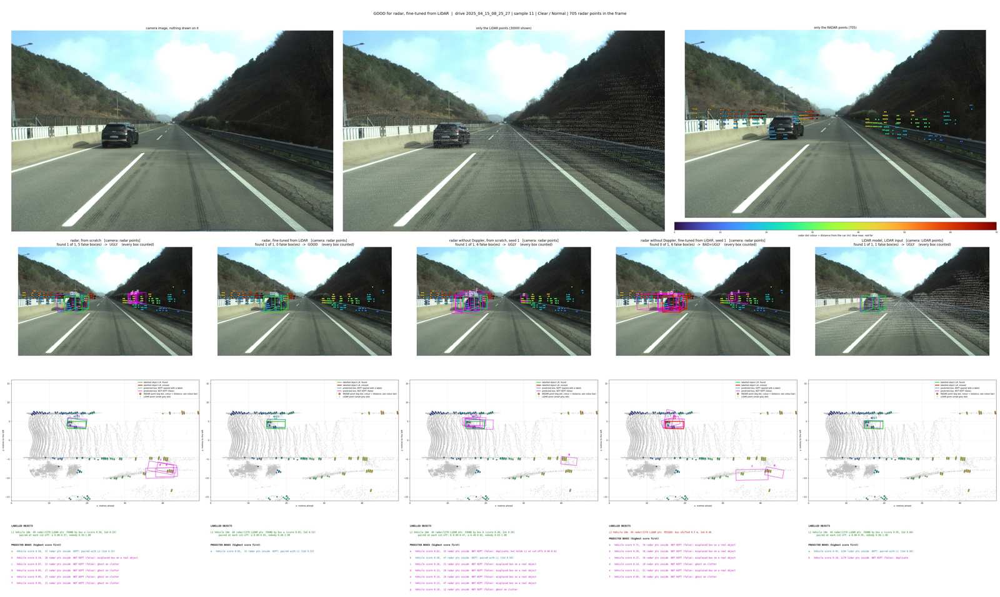

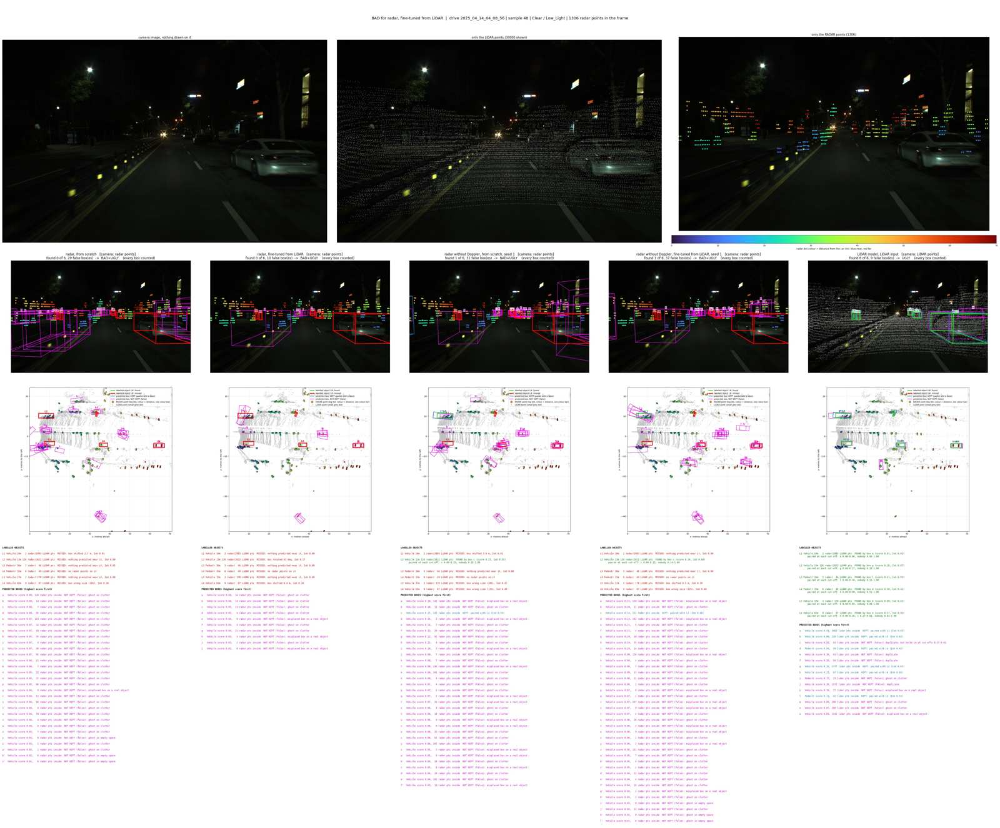

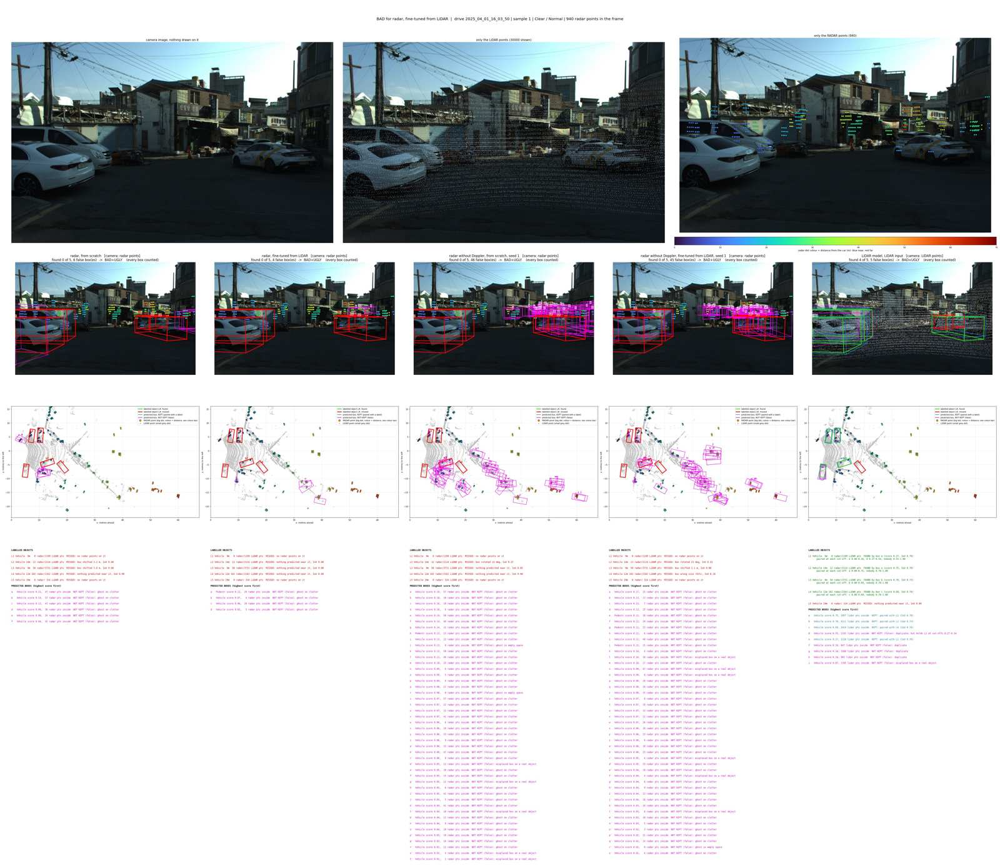

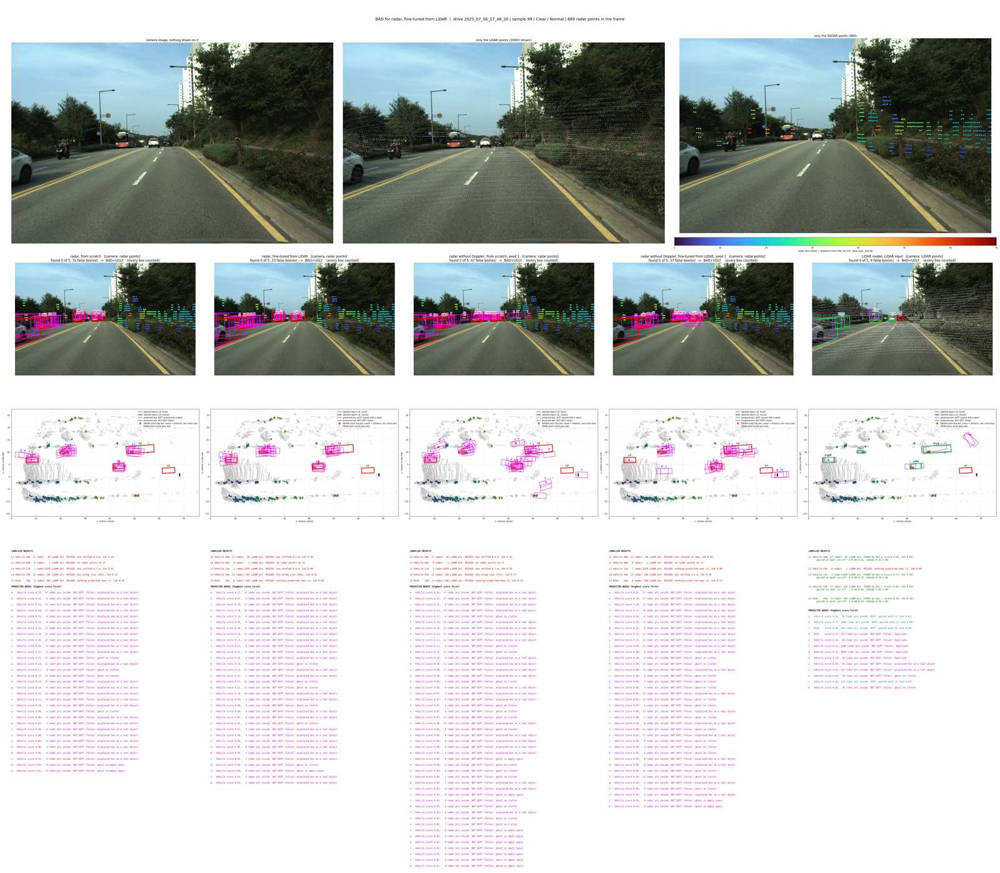

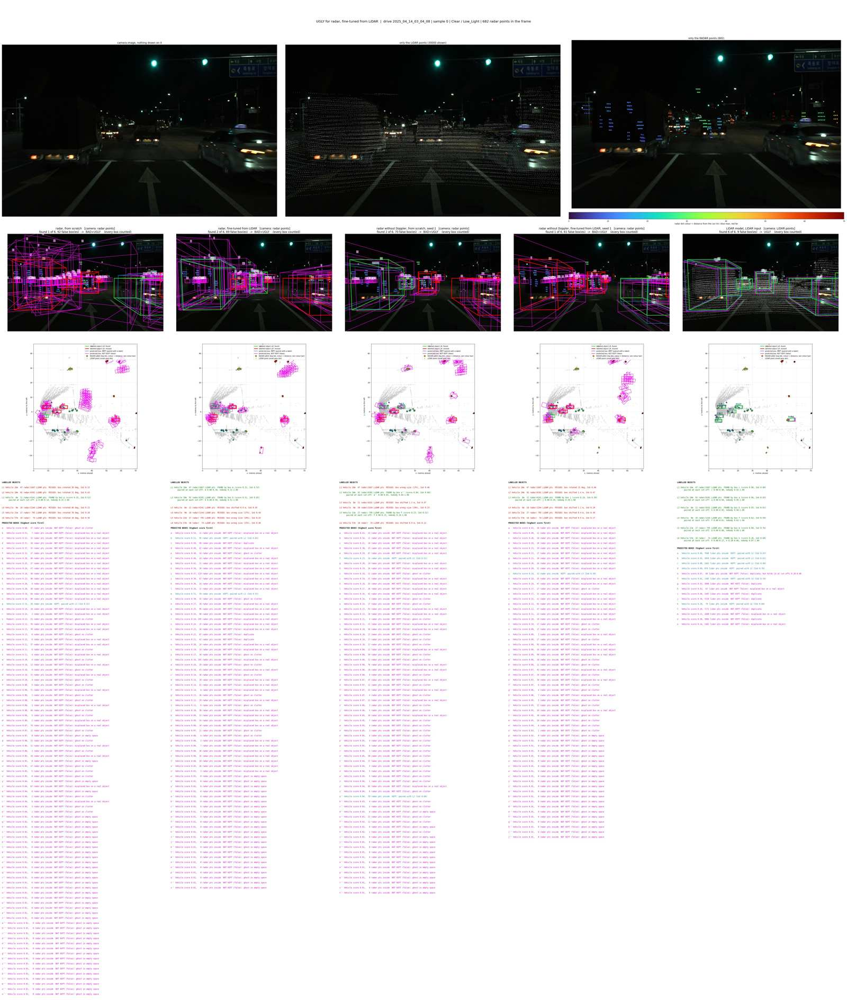

...

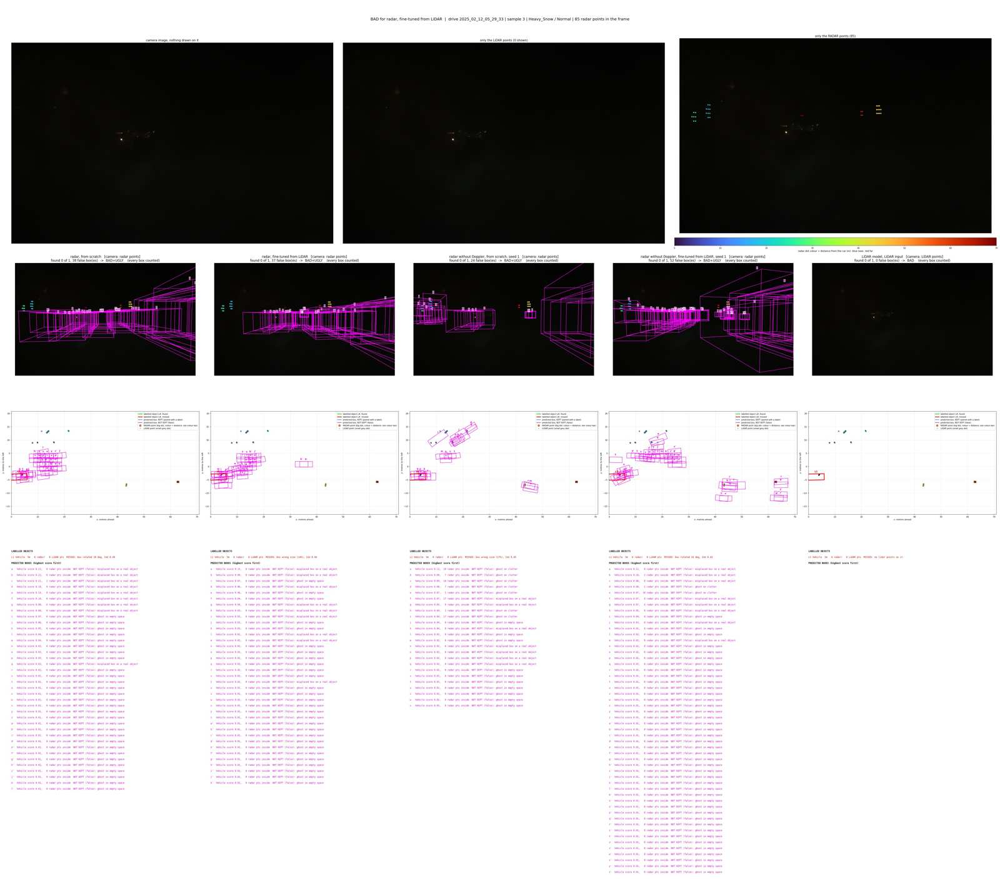

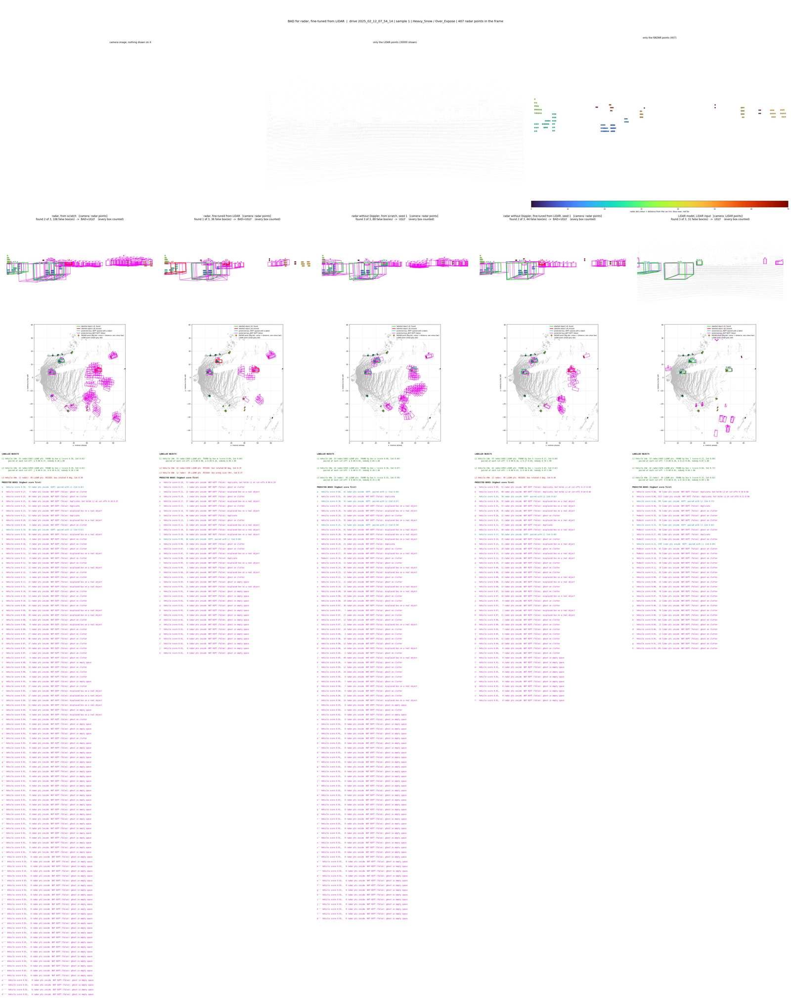

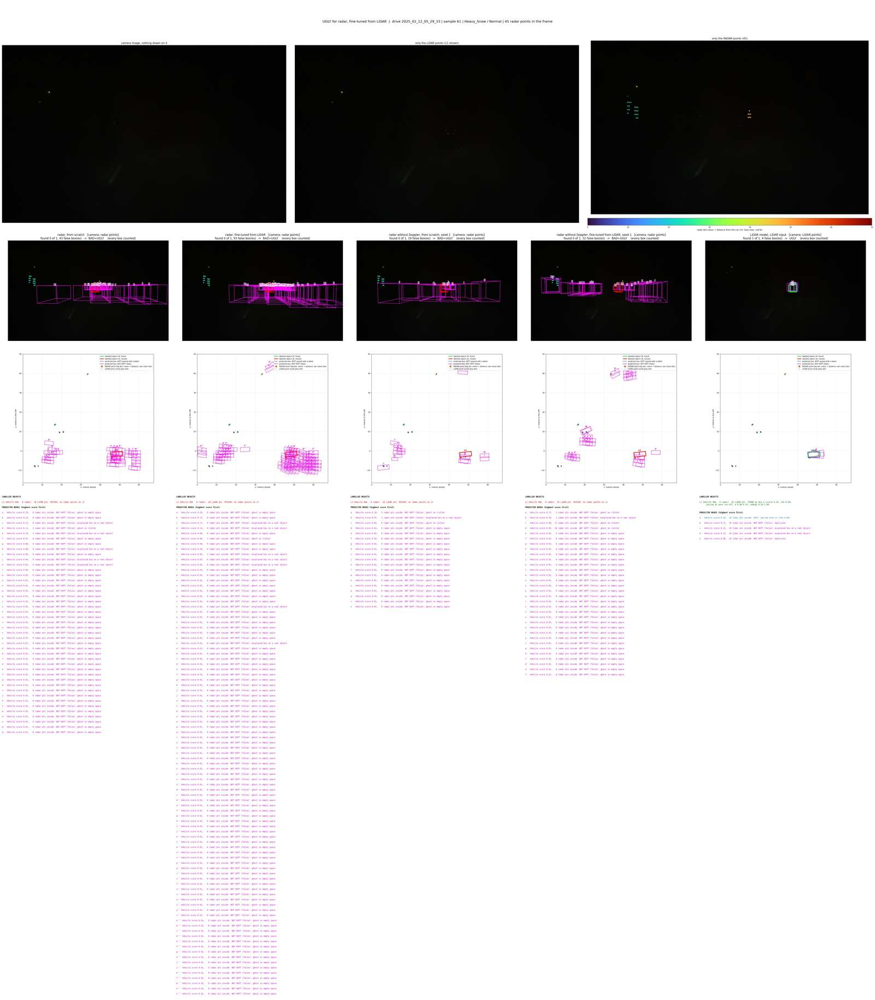

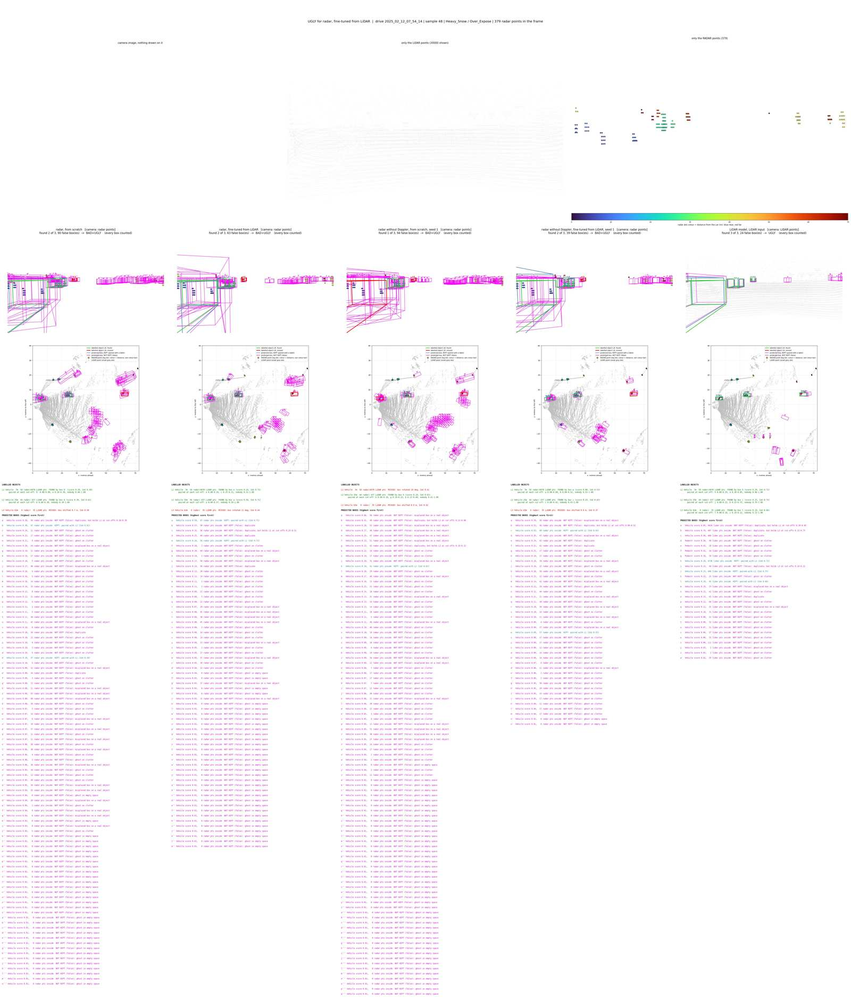

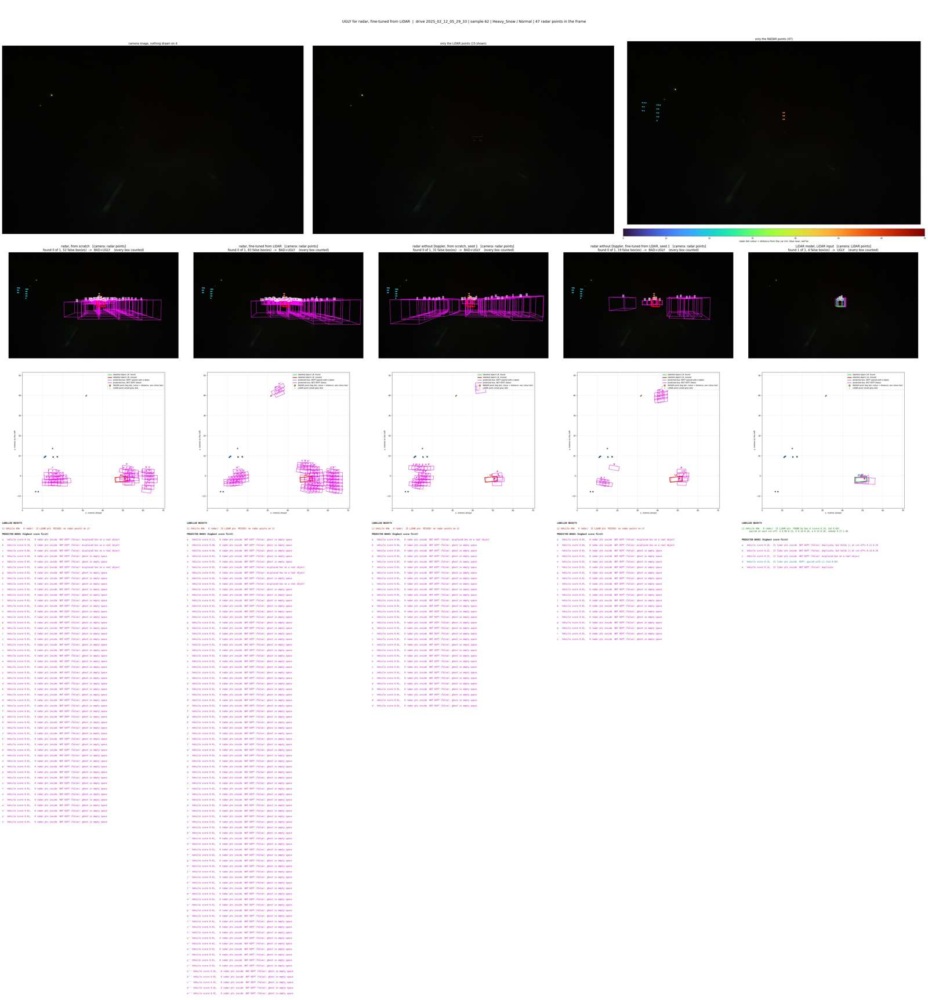

In [11]:
MODEL = "radar_ft_from_livox"          # whose verdict picks the frames
COMPARE = [RUNS[s][0] for s in ["radar_scratch", "radar_ft_from_livox", "radar_scratch_xyz", "radar_ft_from_livox_xyz",
                                "livox_pretrain"] if s in RUNS]      # one run of each setup, drawn side by side
N_EACH = 3                              # frames per verdict and weather
SHOW_WEATHERS = WEATHERS                # or e.g. ["Fog", "Heavy_Rain"]

def pick(model, verdict, weather, n):
    d = S[(S.model == model) & (S.weather == weather) & (S.labelled > 0) & FR.has_image.reindex(S.k).values]
    if verdict == "GOOD":
        d = d[d.verdict == "GOOD"].sort_values("labelled", ascending=False)
    elif verdict == "BAD":
        d = d[d.missed > 0].sort_values(["missed", "found"], ascending=[False, True])
    else:
        d = d[d.false > 0].sort_values("false", ascending=False)
    first = d.drop_duplicates("drive")                     # one per drive first, then the rest
    return list(pd.concat([first, d.drop(first.index)]).k.head(n))

# Frames per verdict, for every setup (mean over its runs), all weathers and per weather
VERDICTS = ["GOOD", "BAD", "UGLY", "BAD+UGLY"]
counts = S.groupby(["model", "weather", "verdict"]).size()
def n_frames(m, verdict, weather=None):
    return float(sum(counts.get((m, w, verdict), 0) for w in ([weather] if weather else WEATHERS)))
print("Number of frames per verdict (mean ± standard deviation over the runs of each setup), all weathers")
display(pd.DataFrame.from_dict({SETUP_NAME[s]: {v: pm([n_frames(m, v) for m in RUNS[s]], 1) for v in VERDICTS}
                                for s in RUNS}, orient="index"))
for v in ["GOOD", "BAD+UGLY"]:
    print("\n%s frames per weather (mean over the runs)" % v)
    display(pd.DataFrame.from_dict({SETUP_NAME[s]: {w: round(np.mean([n_frames(m, v, w) for m in RUNS[s]]), 1) for w in WEATHERS}
                                    for s in RUNS}, orient="index"))

for w in SHOW_WEATHERS:
    for verdict in ["GOOD", "BAD", "UGLY"]:
        for k in pick(MODEL, verdict, w, N_EACH):
            show(k, models=COMPARE, title="%s for %s" % (verdict, NAME[MODEL]),
                 folder="5_good_bad_ugly")

## 6. Where the LiDAR pre-training made the difference

Frames where the fine-tuned radar model finds the most labelled objects that radar-from-scratch misses (and the
other way round), per weather. The object list under each picture says exactly what each model did.

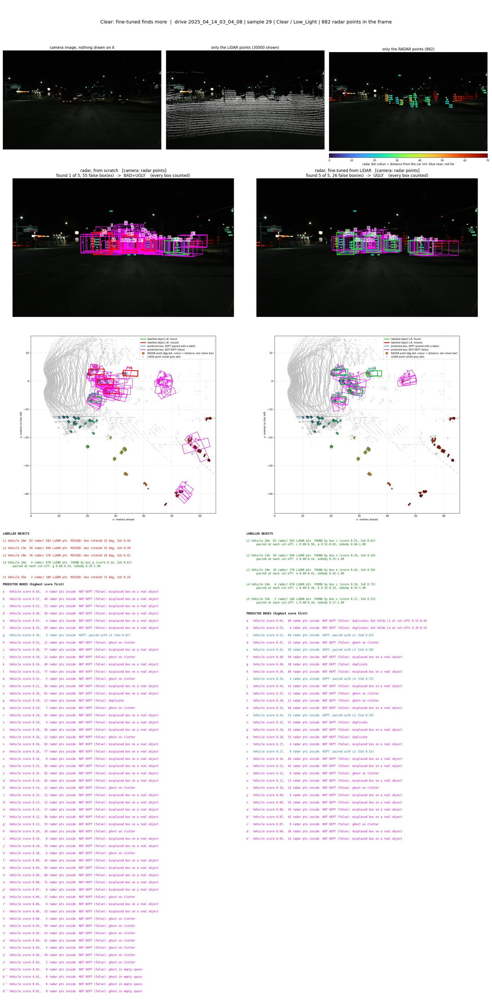

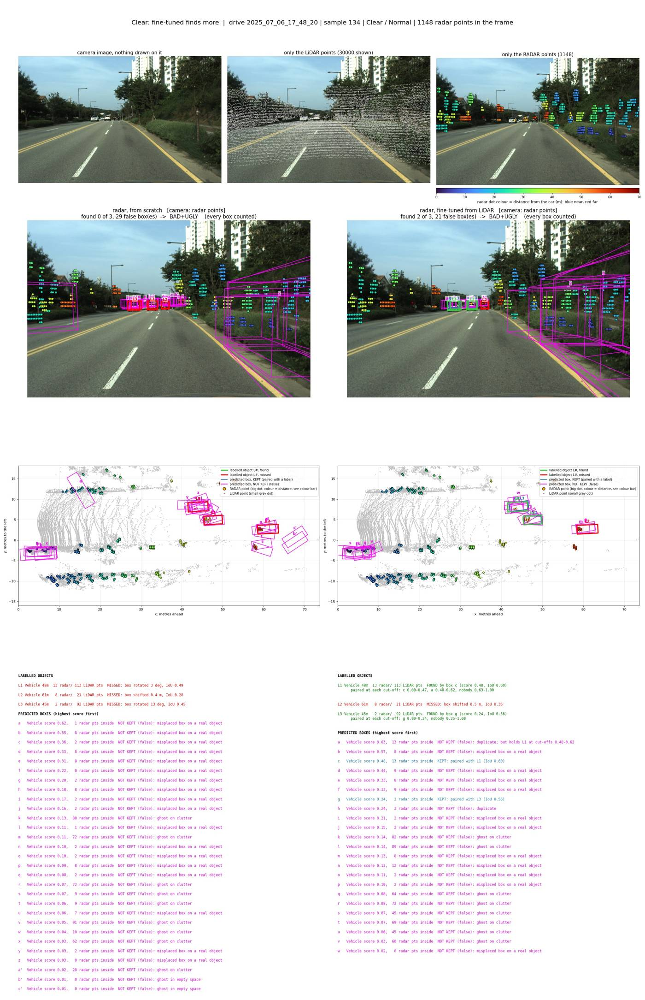

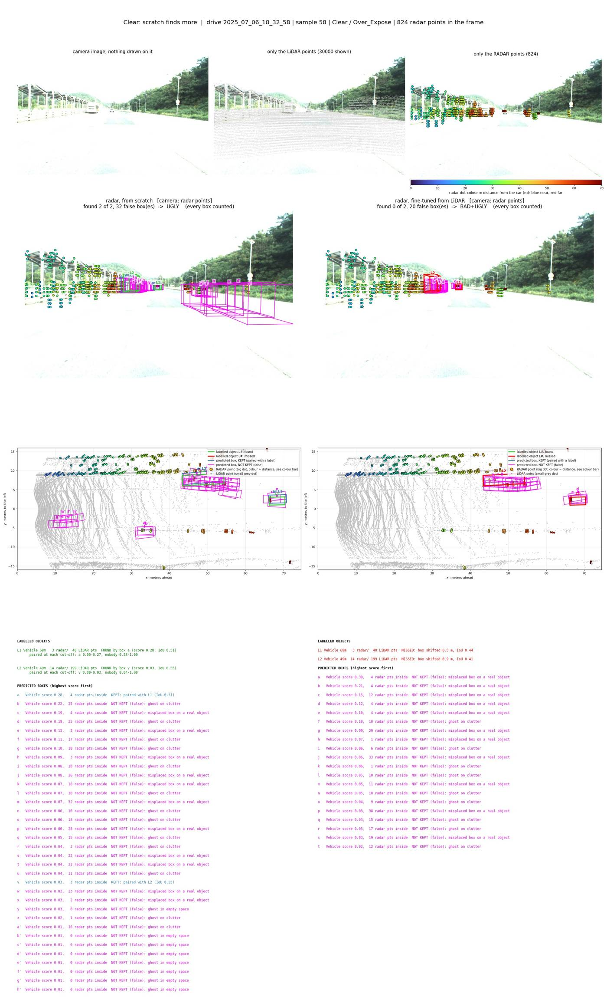

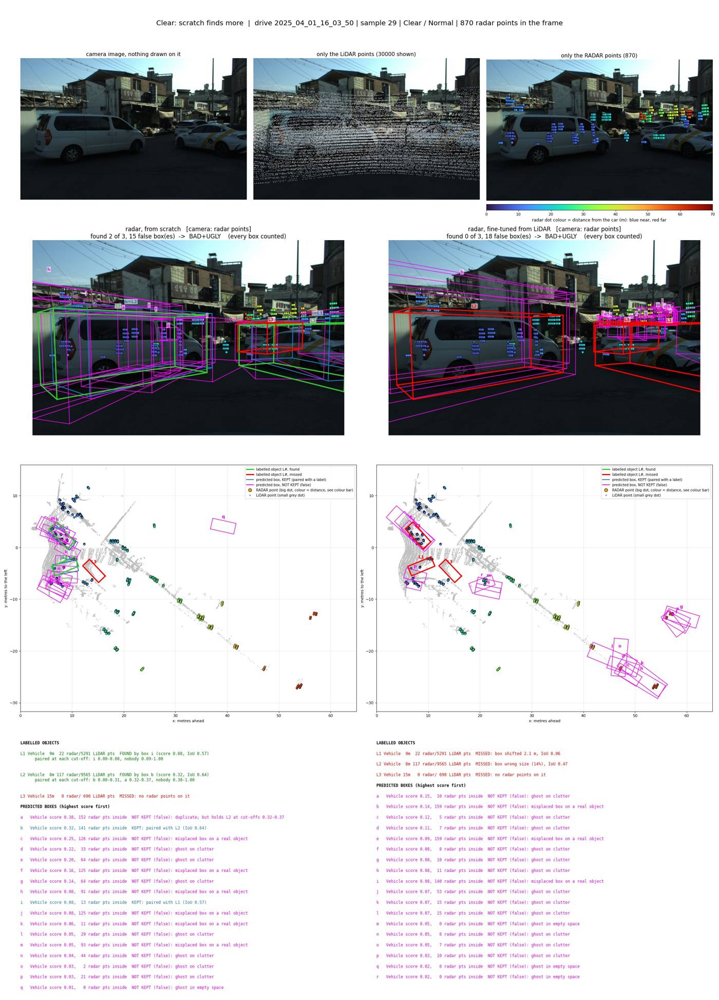

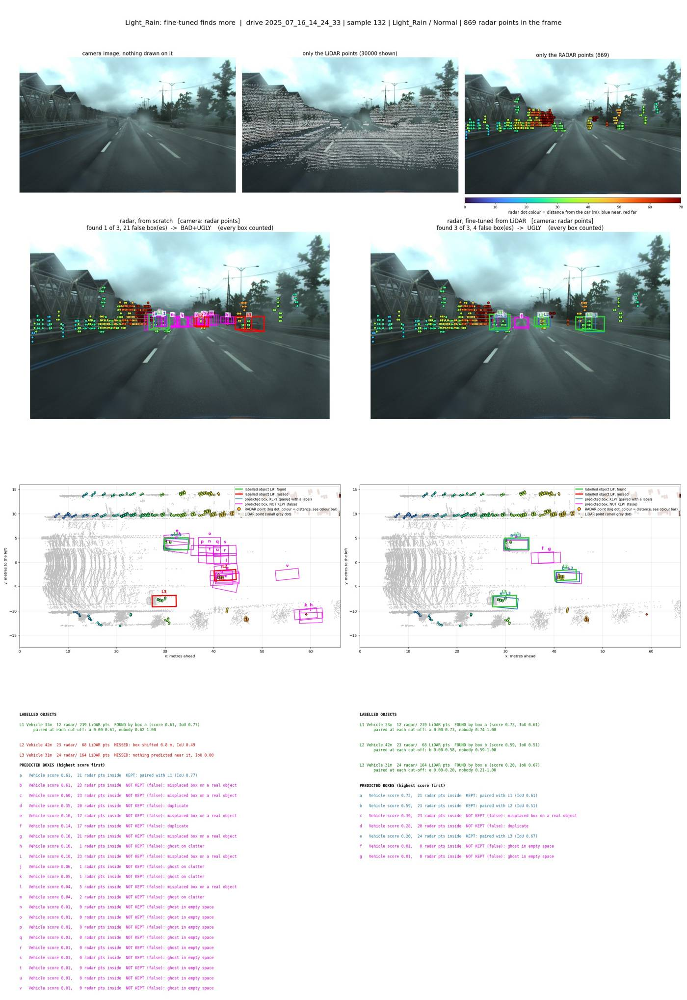

...

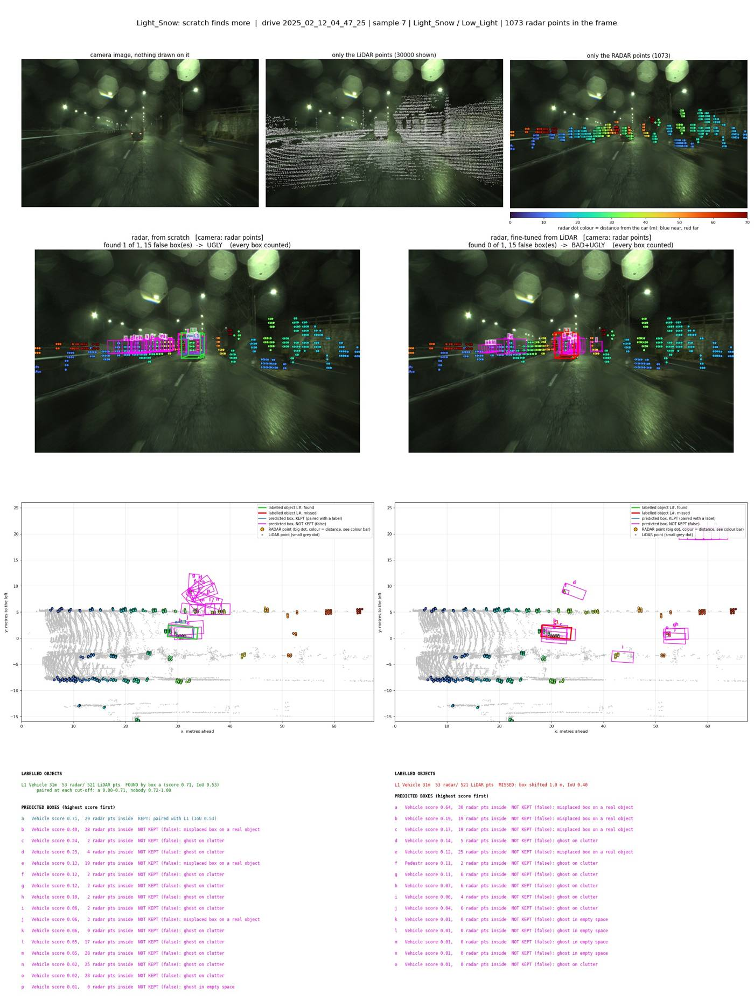

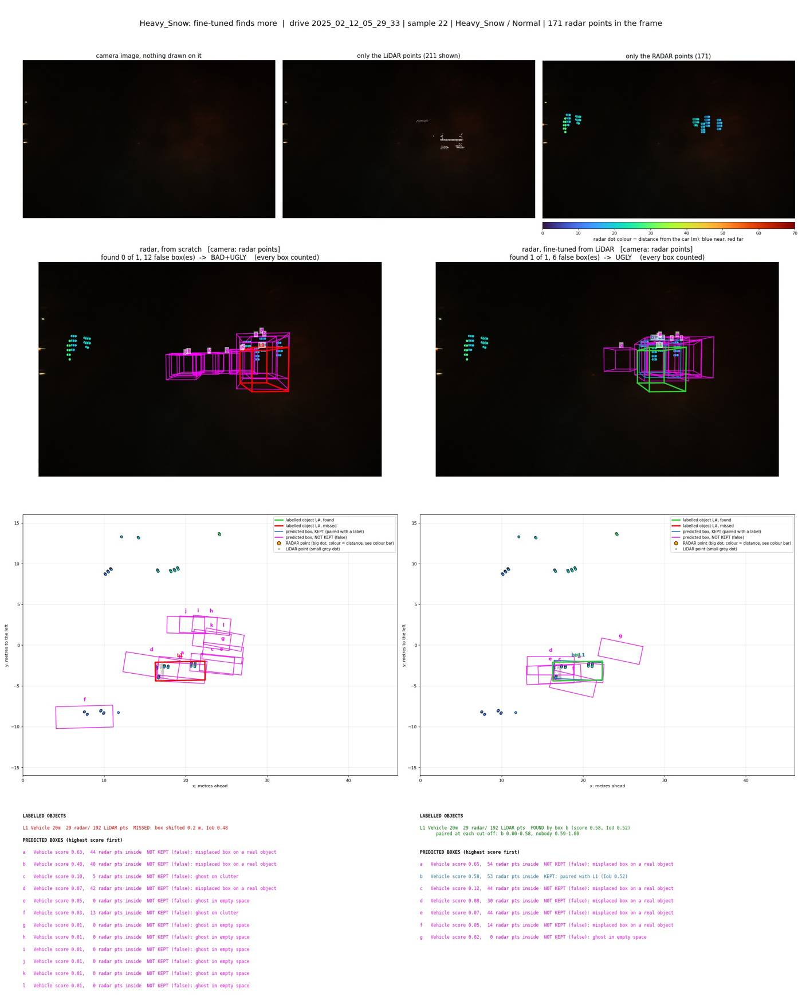

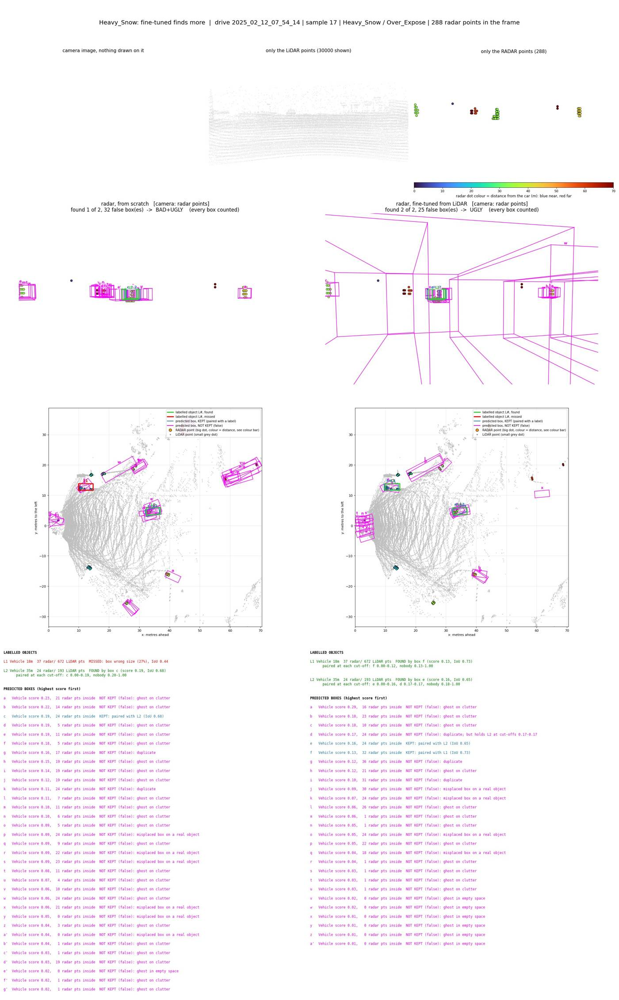

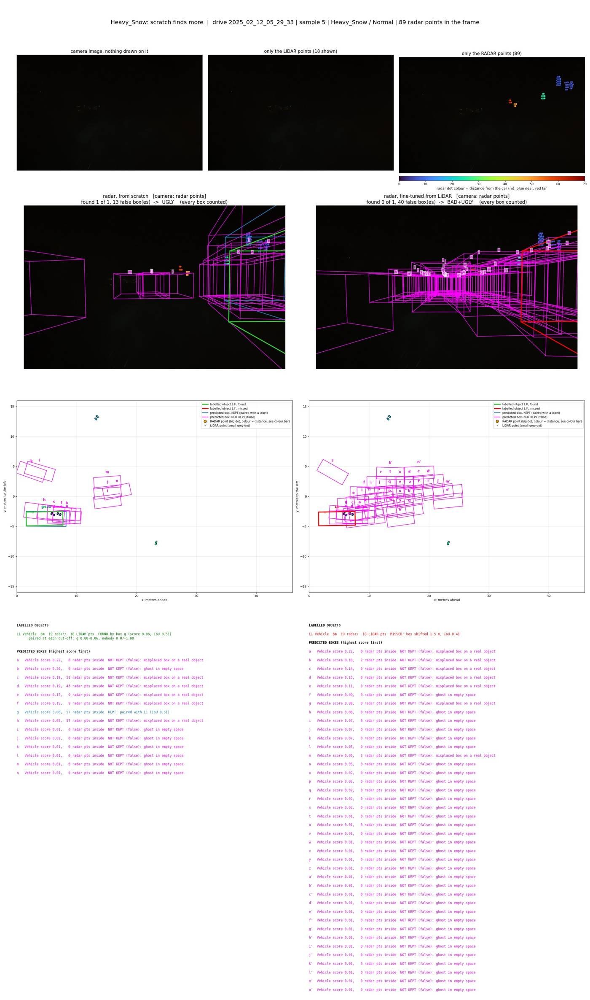

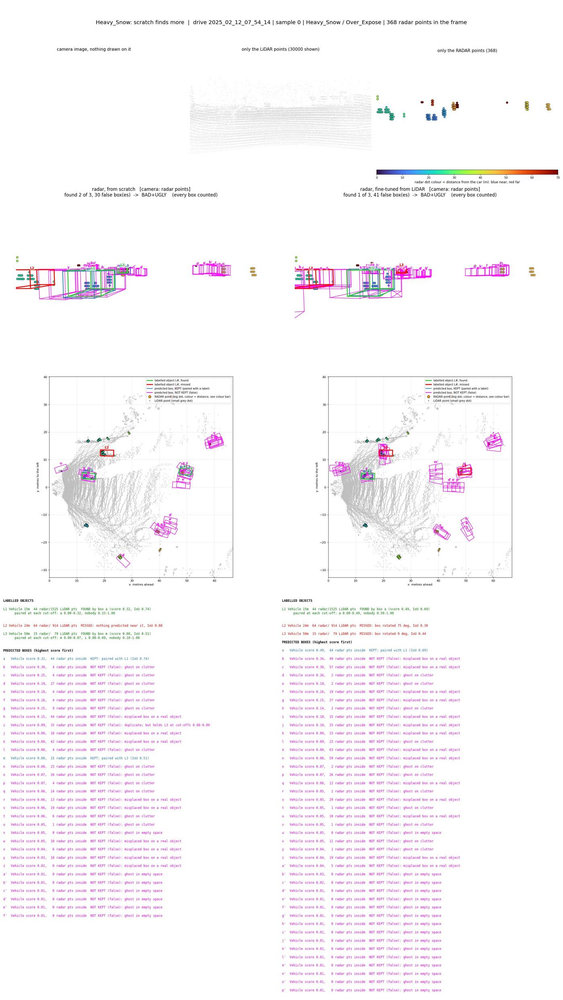

In [12]:
A, B = "radar_scratch", "radar_ft_from_livox"
N_EACH = 2
d = S[S.model == A][["k", "found", "false"]].merge(S[S.model == B][["k", "found", "false"]], on="k", suffixes=("_A", "_B"))
d["gain"] = d.found_B - d.found_A
d = d.merge(FR, left_on="k", right_index=True)
for w in WEATHERS:
    x = d[(d.weather == w) & d.has_image]
    for label, sel in [("fine-tuned finds more", x[x.gain > 0].sort_values("gain", ascending=False)),
                       ("scratch finds more", x[x.gain < 0].sort_values("gain"))]:
        first = sel.drop_duplicates("drive")
        for k in pd.concat([first, sel.drop(first.index)]).k.head(N_EACH):
            show(k, models=(A, B), title="%s: %s" % (w, label), folder="6_pretraining_difference")

## 6b. Standing vs moving vehicles

The labels carry no speed, so each labelled vehicle's speed is measured from the radar's own Doppler value: the first
cell fits our own car's speed per frame from the radar points (most of the scene stands still), and what is left on a
vehicle's points is that vehicle's speed. "Standing" covers parked cars and cars waiting in traffic. The speed is the
part along the line of sight, so a car crossing exactly sideways also counts as standing. Vehicles without a radar
point get no speed.

Section 6b uses every run of five setups: radar with Doppler (from scratch, fine-tuned), radar **without Doppler**
(from scratch, fine-tuned) and the LiDAR model. Tables show the mean ± standard deviation over a setup's runs, and
below each table what Doppler and the LiDAR pre-training add (`*` = the runs of the two setups do not overlap). The
models without Doppler never see the speed value, so if Doppler is what finds the moving cars, they should lose AP on
moving vehicles and keep it on standing ones. Sections 6c-6g look at one run of the three basic setups.

Every number in 6b-6g is **Vehicle AP**, computed with the matching and AP of section 2 (the official way). The
first cell also holds the tools the later cells use, so run it before any of 6b-6g. Splitting AP by speed is not in
the DSERT-RoLL paper: it is a diagnosis next to the paper's numbers.

In [13]:
# ---- tools used by sections 6b-6g -----------------------------------------------------------------------------
def vehicle_boxes(m, k):
    """Model m's vehicle boxes in frame k inside the evaluated range (indices into the frame's boxes, boxes, scores),
    and the frame's labelled vehicles (indices, boxes, difficulty levels)."""
    s = part("pred_" + m, k)
    pb, ps, pc = F["pred_%s_box" % m][s], F["pred_%s_score" % m][s], F["pred_%s_cls" % m][s]
    pi = np.flatnonzero((pc == 1) & (np.hypot(pb[:, 0], pb[:, 1]) < MAX_DIST))
    gb, gc, gl = F["gt_box"][part("gt", k)], F["gt_cls"][part("gt", k)], F["gt_level"][part("gt", k)]
    gj = np.flatnonzero(gc == 1)
    return pi, pb[pi].astype(float), ps[pi].astype(np.float32), gj, gb[gj].astype(float), gl[gj]

def tp_fp_custom(get, thr=IOU_THR["Vehicle"]):
    """Section 2's matching and counting (Hungarian, redone at every score cut-off), for boxes given by get(k) ->
    (scores of the predicted boxes, their 3D IoU with the labelled boxes [predicted x labelled], levels of the
    labelled boxes). Returns TP, FP (frames x cut-offs) and the number of level-1 labelled boxes per frame."""
    TP = np.zeros((N, len(CUTOFFS)), np.int32); FP = np.zeros_like(TP); NG = np.zeros(N, np.int64)
    for k in range(N):
        ps, sub, gl = get(k)
        NG[k] = int((gl == 1).sum())
        if not len(ps):
            continue
        above = ps[None, :] >= CUTOFFS[:, None]
        tp = np.zeros(len(CUTOFFS), np.int32); ign = np.zeros_like(tp)
        if sub.shape[1]:
            ok = sub >= thr
            cand = np.flatnonzero(ok.any(1))
            if len(cand):
                cand = cand[np.argsort(-ps[cand], kind="stable")]
                n_cand = above[:, cand].sum(1)
                for n in np.unique(n_cand):
                    r_, q_ = linear_sum_assignment(np.where(ok[cand[:n]], sub[cand[:n]], 0.0), maximize=True)
                    hit = [q for r, q in zip(r_, q_) if ok[cand[r], q]]
                    tp[n_cand == n] = sum(gl[q] == 1 for q in hit)
                    ign[n_cand == n] = sum(gl[q] != 1 for q in hit)
        TP[k], FP[k] = tp, above.sum(1) - tp - ign
    return TP, FP, NG

def vehicle_ap(TP, FP, NG, mask=None):
    "Vehicle AP (as section 2) over the frames in mask (all frames if None); NaN if those frames hold no labelled vehicle."
    mask = np.ones(N, bool) if mask is None else mask
    return ap_of(TP[mask], FP[mask], NG[mask].sum())[0] if NG[mask].sum() else np.nan

def top_view_overlap(a, b):
    "Top-view overlap area (m2) of every box in a with every box in b."
    A = np.zeros((len(a), len(b)))
    for i in range(len(a)):
        for j in range(len(b)):
            if np.hypot(a[i, 0] - b[j, 0], a[i, 1] - b[j, 1]) <= (np.hypot(a[i, 3], a[i, 4]) + np.hypot(b[j, 3], b[j, 4])) / 2:
                A[i, j] = area(clip_polygon(bev_corners(a[i]), bev_corners(b[j])))
    return A

def iou3d_from_overlap(A, a, b):
    "3D IoU of every box in a with every box in b, from their top-view overlap A and their heights (as iou3d)."
    dz = np.clip(np.minimum(a[:, 2:3] + a[:, 5:6] / 2, (b[:, 2] + b[:, 5] / 2)[None])
                 - np.maximum(a[:, 2:3] - a[:, 5:6] / 2, (b[:, 2] - b[:, 5] / 2)[None]), 0, None)
    v = A * dz
    return v / np.maximum((a[:, 3] * a[:, 4] * a[:, 5])[:, None] + (b[:, 3] * b[:, 4] * b[:, 5])[None] - v, 1e-9)

# 6b compares setups over all their runs; the heavier sections 6c-6g look at one run of the three basic setups.
SPEED_SETUPS = [s for s in ["radar_scratch", "radar_ft_from_livox", "radar_scratch_xyz", "radar_ft_from_livox_xyz",
                            "livox_pretrain"] if s in RUNS]
SPEED_RUNS = [m for s in SPEED_SETUPS for m in RUNS[s]]             # every run of those setups
PICTURE_MODELS = [RUNS[s][0] for s in SPEED_SETUPS]                # one run per setup, for pictures
SPEED_MODELS = [RUNS[s][0] for s in ["radar_scratch", "radar_ft_from_livox", "livox_pretrain"] if s in RUNS]
AS_IS = {}
for m in SPEED_RUNS:
    def get(k, m=m):
        pi, pb, ps, gj, gb, gl = vehicle_boxes(m, k)
        return ps, IOU[m, k][np.ix_(pi, gj)], gl
    AS_IS[m] = tp_fp_custom(get)
    assert abs(vehicle_ap(*AS_IS[m]) - AP[m, "Vehicle", "all"]) < 1e-6      # same as section 2
n_veh = AS_IS[SPEED_RUNS[0]][2]                                              # labelled vehicles (level 1) per frame
WEATHER_MASKS = {"all": np.ones(N, bool)} | {w: (FR.weather == w).values for w in WEATHERS}

# ---- how fast every labelled vehicle moves, measured by the radar itself -----------------------------------------
# The 4th value of a radar point is its raw Doppler speed along the line of sight. For anything that stands still it
# equals (speed of our own car) x cos(angle to the point). So per frame: fit our own speed from all points (most of
# the scene stands still), subtract it, and what is left is the point's own speed over the ground along the line of
# sight. A vehicle's speed = the median of that over the radar points inside its labelled box.
MIN_POINTS_FOR_EGO_FIT = 20           # frames with fewer radar points: speed unknown
own_speed = np.full(N, np.nan)        # our own car, m/s
gt_speed = np.full(len(F["gt_box"]), np.nan)
left_over = []
for k in range(N):
    p = F["radar_pts"][part("radar", k)].astype(float)
    if len(p) < MIN_POINTS_FOR_EGO_FIT:
        continue
    cos = p[:, 0] / np.maximum(np.hypot(p[:, 0], p[:, 1]), 1e-6)
    own_speed[k] = np.median(p[cos > 0.5, 3] / cos[cos > 0.5])
    rest = p[:, 3] - own_speed[k] * cos
    left_over.append(rest)
    for j, b in enumerate(F["gt_box"][part("gt", k)].astype(float)):
        d = p[:, :3] - b[:3]
        c, s = np.cos(-b[6]), np.sin(-b[6])
        inside = ((np.abs(d[:, 0] * c - d[:, 1] * s) <= b[3] / 2) & (np.abs(d[:, 0] * s + d[:, 1] * c) <= b[4] / 2)
                  & (np.abs(d[:, 2]) <= b[5] / 2))
        if inside.any():
            gt_speed[F["gt_off"][k] + j] = abs(np.median(rest[inside]))
left_over = np.abs(np.concatenate(left_over))
print("check of the method: %.1f%% of all radar points are within 0.2 m/s of 'standing still' after subtracting our own "
      "speed (%.1f%% within 0.5 m/s)" % (100 * (left_over < 0.2).mean(), 100 * (left_over < 0.5).mean()))
print("our own speed: median %.0f km/h; our car stands still (< 0.5 m/s) in %d of %d frames"
      % (3.6 * np.nanmedian(np.abs(own_speed)), (np.abs(own_speed) < 0.5).sum(), N))
GT["speed"] = gt_speed[F["gt_off"][GT.k.values] + GT.j.values]
V = GT[(GT.cls == "Vehicle") & (GT.level == 1)]

# AP for one group of labelled vehicles, the way Waymo scores a breakdown that only the labels have (its velocity
# breakdown, detection_metrics.cc): the matching is the normal one, between all predicted and all labelled boxes,
# redone at every score cut-off. For one group: a hit counts if the labelled box it is paired with is in the group;
# a labelled box of the group without a partner is a miss; an unpaired predicted box is a false box for the group
# unless the labelled box it overlaps most (IoU >= 0.01) is in another group (then it is left out of this group).
def tp_fp_by_group(m, cls, group, sets):
    """TP, FP: (frames, cut-offs) over all labelled boxes, as tp_fp_per_cutoff.
    TPs, FPs: (frames, cut-offs, sets), one per set of group numbers; group = one number per labelled box (cache order)."""
    c = CLASSES.index(cls) + 1
    member = np.zeros((len(sets), max(int(group.max()), max(max(g) for g in sets)) + 1), bool)
    for i, g in enumerate(sets):
        member[i, g] = True
    TP = np.zeros((N, len(CUTOFFS)), np.int32); FP = np.zeros_like(TP)
    TPs = np.zeros((N, len(CUTOFFS), len(sets)), np.int32); FPs = np.zeros_like(TPs)
    for k in range(N):
        s = part("pred_" + m, k)
        pb, ps, pc = F["pred_%s_box" % m][s], F["pred_%s_score" % m][s], F["pred_%s_cls" % m][s]
        pi = np.flatnonzero((pc == c) & (np.hypot(pb[:, 0], pb[:, 1]) < MAX_DIST))
        if not len(pi):
            continue
        gc, gl = F["gt_cls"][part("gt", k)], F["gt_level"][part("gt", k)]
        gj = np.flatnonzero(gc == c)
        gg = group[F["gt_off"][k] + gj]
        above = ps[pi][None, :] >= CUTOFFS[:, None]
        counts = np.ones((len(sets), len(pi)), bool)          # would this box be a false box for the set, if unpaired?
        tp = np.zeros(len(CUTOFFS), np.int32); ign = np.zeros_like(tp)
        tps = np.zeros((len(CUTOFFS), len(sets)), np.int32); paired = np.zeros_like(tps)
        if len(gj):
            sub = IOU[m, k][np.ix_(pi, gj)]
            near = gg[sub.argmax(1)]                           # group of the labelled box it overlaps most
            counts = np.where(sub.max(1) >= 0.01, member[:, near], True)
            ok = sub >= IOU_THR[cls]
            cand = np.flatnonzero(ok.any(1))
            if len(cand):
                cand = cand[np.argsort(-ps[pi][cand], kind="stable")]
                n_cand = above[:, cand].sum(1)
                for n in np.unique(n_cand):
                    r_, q_ = linear_sum_assignment(np.where(ok[cand[:n]], sub[cand[:n]], 0.0), maximize=True)
                    hit = [(cand[r], q) for r, q in zip(r_, q_) if ok[cand[r], q]]
                    at = n_cand == n
                    tp[at] = sum(gl[gj[q]] == 1 for _, q in hit)
                    ign[at] = sum(gl[gj[q]] != 1 for _, q in hit)
                    if hit:
                        tps[at] = sum(member[:, gg[q]] * (gl[gj[q]] == 1) for _, q in hit)
                        paired[at] = sum(counts[:, r] for r, _ in hit)
        TP[k], FP[k] = tp, above.sum(1) - tp - ign
        TPs[k], FPs[k] = tps, above.astype(np.int32) @ counts.T.astype(np.int32) - paired
    return TP, FP, TPs, FPs

def boxes_on_nothing(m):
    "(frames, cut-offs): model m's vehicle boxes above each cut-off that overlap no labelled vehicle at all (IoU < 0.01)."
    G = np.zeros((N, len(CUTOFFS)), np.int32)
    for k in range(N):
        pi, pb, ps, gj, gb, gl = vehicle_boxes(m, k)
        far = np.ones(len(pi), bool) if not len(gj) else IOU[m, k][np.ix_(pi, gj)].max(1) < 0.01
        G[k] = (ps[far][None, :] >= CUTOFFS[:, None]).sum(1)
    return G

def group_ap(m, group, sets, masks=None, without_boxes_on_nothing=False):
    """{(set name, mask name): Vehicle AP} for model m, sets = {name: list of group numbers}, masks = {name: frame mask}.
    without_boxes_on_nothing=True: a check outside Waymo's rule, boxes that overlap no labelled vehicle are not counted."""
    _, _, TPs, FPs = tp_fp_by_group(m, "Vehicle", group, list(sets.values()))
    if without_boxes_on_nothing:
        FPs = FPs - boxes_on_nothing(m)[:, :, None]
    out = {}
    for i, (name, g) in enumerate(sets.items()):
        n = V[np.isin(group[F["gt_off"][V.k.values] + V.j.values], g)].groupby("k").size().reindex(range(N), fill_value=0).values
        for mname, mask in (masks or {"all": np.ones(N, bool)}).items():
            out[name, mname] = ap_of(TPs[mask][:, :, i], FPs[mask][:, :, i], n[mask].sum())[0] if n[mask].sum() else np.nan
    return out

check of the method: 93.2% of all radar points are within 0.2 m/s of 'standing still' after subtracting our own speed (94.1% within 0.5 m/s)
our own speed: median 35 km/h; our car stands still (< 0.5 m/s) in 171 of 5637 frames


### The headline: same radar visibility, different motion

Only vehicles with 6-50 radar points at 10-50 m, so both groups are seen equally well by the radar. Each group is
scored the way Waymo scores its velocity breakdown: all boxes are matched as usual; a hit counts for a group if its
vehicle is in the group; an unpaired box counts against a group unless it overlaps a vehicle of another group.
Boxes that overlap no vehicle at all count against both groups, which weighs more on the small standing group, so a
second pair of tables repeats the numbers without those boxes.

In [14]:
# Standing vs moving vehicles, compared fairly: only vehicles with a similar number of radar points and at a similar
# distance, so the difference is the motion and not how well the radar sees them. Every setup is shown as the mean ±
# standard deviation over its runs; the setups without Doppler never see the speed value the split is made from.
STANDING_BELOW = 0.5        # m/s: standing
MOVING_ABOVE = 4.0          # m/s: clearly moving (vehicles in between are left out of both groups)
RADAR_POINTS = (6, 50)      # radar points inside the labelled box, both ends included
DISTANCE = (10, 50)         # m, both ends included

gb = F["gt_box"].astype(float)
pts_ok = (F["gt_radar_pts"] >= RADAR_POINTS[0]) & (F["gt_radar_pts"] <= RADAR_POINTS[1])
dist_ok = (np.hypot(gb[:, 0], gb[:, 1]) >= DISTANCE[0]) & (np.hypot(gb[:, 0], gb[:, 1]) <= DISTANCE[1])
fair = np.full(len(gt_speed), 2)                                   # 2 = in neither group
fair[pts_ok & dist_ok & (gt_speed < STANDING_BELOW)] = 0
fair[pts_ok & dist_ok & (gt_speed > MOVING_ABOVE)] = 1
FAIR_SETS = {"standing (< %.1f m/s)" % STANDING_BELOW: [0], "moving (> %.0f m/s)" % MOVING_ABOVE: [1]}
count = {name: int(np.isin(fair[F["gt_off"][V.k.values] + V.j.values], g).sum()) for name, g in FAIR_SETS.items()}
cols = {name: "%s, %d vehicles" % (name, count[name]) for name in FAIR_SETS}

FAIR_AP = {check: {m: group_ap(m, fair, FAIR_SETS, without_boxes_on_nothing=check) for m in SPEED_RUNS} for check in [False, True]}
for check in [False, True]:
    value = lambda m, name: FAIR_AP[check][m][name, "all"]
    if not check:
        print("Vehicle AP, standing vs moving vehicles with %d-%d radar points at %d-%d m (all weathers)" % (RADAR_POINTS + DISTANCE))
    else:
        print("\nCheck: the same, without the boxes that overlap no labelled vehicle at all. Waymo's rule counts those against\n"
              "every group, which weighs more on a small group.")
    display(setup_table(value, list(FAIR_SETS), SPEED_SETUPS).rename(columns=cols))
    display(gain_table(value, list(FAIR_SETS)).rename(columns=cols))

Vehicle AP, standing vs moving vehicles with 6-50 radar points at 10-50 m (all weathers)


,"standing (< 0.5 m/s), 737 vehicles","moving (> 4 m/s), 3677 vehicles"
"radar, from scratch",0.0133 ± 0.0070,0.5547 ± 0.0228
"radar, fine-tuned from LiDAR",0.0262 ± 0.0072,0.5918 ± 0.0071
"radar without Doppler, from scratch",0.0991 ± 0.0041,0.3987 ± 0.0104
"radar without Doppler, fine-tuned from LiDAR",0.1024 ± 0.0215,0.4230 ± 0.0075
"LiDAR model, LiDAR input",0.9193,0.9622


,"standing (< 0.5 m/s), 737 vehicles","moving (> 4 m/s), 3677 vehicles"
LiDAR pre-training adds (with Doppler),+0.0130,+0.0370 *
LiDAR pre-training adds (without Doppler),+0.0033,+0.0243 *
Doppler adds (from scratch),-0.0858 *,+0.1560 *
Doppler adds (fine-tuned),-0.0762 *,+0.1688 *



Check: the same, without the boxes that overlap no labelled vehicle at all. Waymo's rule counts those against
every group, which weighs more on a small group.


,"standing (< 0.5 m/s), 737 vehicles","moving (> 4 m/s), 3677 vehicles"
"radar, from scratch",0.0832 ± 0.0237,0.5683 ± 0.0228
"radar, fine-tuned from LiDAR",0.1194 ± 0.0063,0.6047 ± 0.0068
"radar without Doppler, from scratch",0.2100 ± 0.0093,0.4418 ± 0.0104
"radar without Doppler, fine-tuned from LiDAR",0.2232 ± 0.0262,0.4681 ± 0.0081
"LiDAR model, LiDAR input",0.9395,0.9648


,"standing (< 0.5 m/s), 737 vehicles","moving (> 4 m/s), 3677 vehicles"
LiDAR pre-training adds (with Doppler),+0.0362 *,+0.0364 *
LiDAR pre-training adds (without Doppler),+0.0132,+0.0263 *
Doppler adds (from scratch),-0.1268 *,+0.1266 *
Doppler adds (fine-tuned),-0.1037 *,+0.1366 *


### All vehicles, by speed (Waymo's speed limits 0.2 / 1 / 3 / 10 m/s), and per weather

In [15]:
# All vehicles, by speed. The speed limits are those of Waymo's velocity breakdown.
SPEED_EDGES = [0.2, 1.0, 3.0, 10.0]   # m/s: STATIONARY / SLOW / MEDIUM / FAST / VERY_FAST
SPEED_NAMES = ["standing (< 0.2 m/s)", "0.2 - 1 m/s", "1 - 3 m/s", "3 - 10 m/s", "> 10 m/s", "speed unknown (no radar point)"]
gt_group = np.where(np.isnan(gt_speed), 5, np.digitize(gt_speed, SPEED_EDGES))   # 0..4 = the speed bins, 5 = unknown
GT["speed_group"] = gt_group[F["gt_off"][GT.k.values] + GT.j.values]
V = GT[(GT.cls == "Vehicle") & (GT.level == 1)]
SETS = {n: [i] for i, n in enumerate(SPEED_NAMES)}
MOVING = "moving (0.2 m/s or faster)"
SETS[MOVING] = [1, 2, 3, 4]
ORDER = [SPEED_NAMES[0], MOVING] + SPEED_NAMES[1:]
SPEED_AP = {m: group_ap(m, gt_group, SETS, WEATHER_MASKS) for m in SPEED_RUNS}

T = setup_table(lambda m, n: SPEED_AP[m][n, "all"], ORDER, SPEED_SETUPS).T
T.insert(0, "labelled vehicles", [int(V.speed_group.isin(SETS[n]).sum()) for n in ORDER])
print("Vehicle AP by how fast the vehicle moves (all weathers); mean ± standard deviation over the runs of each setup")
display(T)
print("\nWhat Doppler and the LiDAR pre-training add, by speed ('*' = every run of the first setup beats every run of the second)")
display(gain_table(lambda m, n: SPEED_AP[m][n, "all"], ORDER).T)

for n in [SPEED_NAMES[0], MOVING]:
    T = setup_table(lambda m, w: SPEED_AP[m][n, w], WEATHERS, SPEED_SETUPS).T
    T.insert(0, "labelled vehicles", [int((V.speed_group.isin(SETS[n]) & (V.weather == w)).sum()) for w in WEATHERS])
    print("\nVehicle AP of the %s vehicles, per weather" % n.split(" (")[0])
    display(T)
    display(gain_table(lambda m, w: SPEED_AP[m][n, w], WEATHERS).T)

Vehicle AP by how fast the vehicle moves (all weathers); mean ± standard deviation over the runs of each setup


,labelled vehicles,"radar, from scratch","radar, fine-tuned from LiDAR","radar without Doppler, from scratch","radar without Doppler, fine-tuned from LiDAR","LiDAR model, LiDAR input"
standing (< 0.2 m/s),1477,0.0192 ± 0.0057,0.0377 ± 0.0042,0.1125 ± 0.0106,0.1115 ± 0.0137,0.8782
moving (0.2 m/s or faster),6792,0.4200 ± 0.0157,0.4588 ± 0.0055,0.3000 ± 0.0102,0.3253 ± 0.0054,0.9052
0.2 - 1 m/s,97,0.0066 ± 0.0006,0.0140 ± 0.0017,0.0334 ± 0.0107,0.0230 ± 0.0041,0.6915
1 - 3 m/s,316,0.0424 ± 0.0014,0.0896 ± 0.0153,0.0721 ± 0.0038,0.0934 ± 0.0093,0.8188
3 - 10 m/s,2013,0.2319 ± 0.0191,0.2670 ± 0.0044,0.1497 ± 0.0099,0.1641 ± 0.0018,0.8621
> 10 m/s,4366,0.5150 ± 0.0161,0.5552 ± 0.0075,0.3525 ± 0.0108,0.3810 ± 0.0082,0.9239
speed unknown (no radar point),1034,0.0041 ± 0.0003,0.0047 ± 0.0006,0.0003 ± 0.0001,0.0004 ± 0.0000,0.5707



What Doppler and the LiDAR pre-training add, by speed ('*' = every run of the first setup beats every run of the second)


,LiDAR pre-training adds (with Doppler),LiDAR pre-training adds (without Doppler),Doppler adds (from scratch),Doppler adds (fine-tuned)
standing (< 0.2 m/s),+0.0185 *,-0.0010,-0.0933 *,-0.0738 *
moving (0.2 m/s or faster),+0.0388 *,+0.0252 *,+0.1200 *,+0.1335 *
0.2 - 1 m/s,+0.0075 *,-0.0104,-0.0269 *,-0.0090 *
1 - 3 m/s,+0.0473 *,+0.0214 *,-0.0297 *,-0.0038
3 - 10 m/s,+0.0351 *,+0.0144 *,+0.0822 *,+0.1030 *
> 10 m/s,+0.0402 *,+0.0285 *,+0.1625 *,+0.1742 *
speed unknown (no radar point),+0.0006,+0.0000,+0.0038 *,+0.0043 *



Vehicle AP of the standing vehicles, per weather


,labelled vehicles,"radar, from scratch","radar, fine-tuned from LiDAR","radar without Doppler, from scratch","radar without Doppler, fine-tuned from LiDAR","LiDAR model, LiDAR input"
Clear,1122,0.0174 ± 0.0080,0.0253 ± 0.0036,0.1034 ± 0.0115,0.1018 ± 0.0149,0.9330
Light_Rain,82,0.0480 ± 0.0219,0.0716 ± 0.0150,0.1832 ± 0.0603,0.1474 ± 0.0068,0.9457
Heavy_Rain,170,0.0943 ± 0.0227,0.1685 ± 0.0124,0.2389 ± 0.0120,0.2635 ± 0.0164,0.6062
Fog,7,0.1826 ± 0.1422,0.5460 ± 0.1123,0.4940 ± 0.1730,0.1825 ± 0.1941,0.8845
Light_Snow,91,0.0136 ± 0.0056,0.0707 ± 0.0162,0.0355 ± 0.0042,0.0586 ± 0.0138,0.7977
Heavy_Snow,5,0.1447 ± 0.0637,0.3254 ± 0.1214,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0103


,LiDAR pre-training adds (with Doppler),LiDAR pre-training adds (without Doppler),Doppler adds (from scratch),Doppler adds (fine-tuned)
Clear,+0.0079,-0.0016,-0.0860 *,-0.0765 *
Light_Rain,+0.0236,-0.0358,-0.1352 *,-0.0758 *
Heavy_Rain,+0.0743 *,+0.0246 *,-0.1446 *,-0.0950 *
Fog,+0.3634 *,-0.3115,-0.3114 *,+0.3634 *
Light_Snow,+0.0571 *,+0.0231 *,-0.0220 *,+0.0121
Heavy_Snow,+0.1806,+0.0000,+0.1447 *,+0.3253 *



Vehicle AP of the moving vehicles, per weather


,labelled vehicles,"radar, from scratch","radar, fine-tuned from LiDAR","radar without Doppler, from scratch","radar without Doppler, fine-tuned from LiDAR","LiDAR model, LiDAR input"
Clear,4202,0.3946 ± 0.0152,0.4268 ± 0.0045,0.2575 ± 0.0069,0.2777 ± 0.0063,0.9250
Light_Rain,620,0.5711 ± 0.0122,0.6005 ± 0.0167,0.4283 ± 0.0197,0.4729 ± 0.0259,0.9639
Heavy_Rain,701,0.4305 ± 0.0027,0.5022 ± 0.0227,0.3977 ± 0.0149,0.4180 ± 0.0177,0.9117
Fog,574,0.4701 ± 0.0291,0.5358 ± 0.0018,0.3023 ± 0.0091,0.3540 ± 0.0141,0.7261
Light_Snow,415,0.4985 ± 0.0465,0.5027 ± 0.0245,0.3933 ± 0.0203,0.4279 ± 0.0056,0.9282
Heavy_Snow,280,0.2828 ± 0.0554,0.3783 ± 0.0047,0.3211 ± 0.0271,0.3302 ± 0.0101,0.7860


,LiDAR pre-training adds (with Doppler),LiDAR pre-training adds (without Doppler),Doppler adds (from scratch),Doppler adds (fine-tuned)
Clear,+0.0323 *,+0.0202 *,+0.1371 *,+0.1492 *
Light_Rain,+0.0295 *,+0.0446,+0.1428 *,+0.1277 *
Heavy_Rain,+0.0717 *,+0.0203,+0.0328 *,+0.0843 *
Fog,+0.0657 *,+0.0517 *,+0.1678 *,+0.1818 *
Light_Snow,+0.0042,+0.0346 *,+0.1052 *,+0.0748 *
Heavy_Snow,+0.0955 *,+0.0090,-0.0383,+0.0481 *


### Is radar better in fog, or does fog just have fewer standing cars?

Plain Vehicle AP over three sets of frames, per weather: all frames, frames with at least one standing vehicle, and
frames with only moving vehicles. Then pictures of `COMPARE_WEATHER` (Clear) frames with the most standing vehicles
next to Clear frames with the most moving vehicles: `pictures/6b_clear_standing_vs_moving/standing/` and `.../moving/`.


Vehicle AP per weather: all frames (mean ± standard deviation over the runs of each setup)


,frames,labelled vehicles,"radar, from scratch","radar, fine-tuned from LiDAR","radar without Doppler, from scratch","radar without Doppler, fine-tuned from LiDAR","LiDAR model, LiDAR input"
all,5637,9303,0.3202 ± 0.0110,0.3530 ± 0.0052,0.2500 ± 0.0088,0.2692 ± 0.0032,0.8719
Clear,3248,6025,0.2898 ± 0.0096,0.3148 ± 0.0046,0.2133 ± 0.0055,0.2281 ± 0.0049,0.9034
Light_Rain,576,760,0.4867 ± 0.0126,0.5162 ± 0.0166,0.3842 ± 0.0227,0.4164 ± 0.0199,0.9584
Heavy_Rain,496,1024,0.3124 ± 0.0015,0.3713 ± 0.0146,0.3203 ± 0.0081,0.3365 ± 0.0078,0.7576
Fog,608,598,0.4567 ± 0.0287,0.5225 ± 0.0020,0.2985 ± 0.0076,0.3463 ± 0.0123,0.7188
Light_Snow,469,561,0.3782 ± 0.0366,0.3900 ± 0.0173,0.3030 ± 0.0161,0.3335 ± 0.0046,0.8766
Heavy_Snow,240,335,0.2245 ± 0.0416,0.3209 ± 0.0059,0.2684 ± 0.0228,0.2763 ± 0.0087,0.7131


,LiDAR pre-training adds (with Doppler),LiDAR pre-training adds (without Doppler),Doppler adds (from scratch),Doppler adds (fine-tuned)
all,+0.0328 *,+0.0193 *,+0.0702 *,+0.0837 *
Clear,+0.0250 *,+0.0148 *,+0.0765 *,+0.0867 *
Light_Rain,+0.0296 *,+0.0322,+0.1025 *,+0.0998 *
Heavy_Rain,+0.0590 *,+0.0162 *,-0.0079,+0.0348 *
Fog,+0.0657 *,+0.0478 *,+0.1583 *,+0.1762 *
Light_Snow,+0.0119,+0.0305 *,+0.0752 *,+0.0565 *
Heavy_Snow,+0.0965 *,+0.0079,-0.0440,+0.0446 *



Vehicle AP per weather: frames with standing vehicles (mean ± standard deviation over the runs of each setup)


,frames,labelled vehicles,"radar, from scratch","radar, fine-tuned from LiDAR","radar without Doppler, from scratch","radar without Doppler, fine-tuned from LiDAR","LiDAR model, LiDAR input"
all,1002,2366,0.1419 ± 0.0067,0.1710 ± 0.0052,0.1802 ± 0.0124,0.1919 ± 0.0084,0.8404
Clear,710,1618,0.0795 ± 0.0107,0.1052 ± 0.0040,0.1346 ± 0.0144,0.1473 ± 0.0117,0.9020
Light_Rain,82,181,0.5134 ± 0.0162,0.5367 ± 0.0207,0.5072 ± 0.0425,0.5052 ± 0.0107,0.9820
Heavy_Rain,121,405,0.2452 ± 0.0083,0.2711 ± 0.0110,0.2846 ± 0.0009,0.2951 ± 0.0094,0.6077
Fog,7,8,0.5304 ± 0.1179,0.6849 ± 0.0604,0.6499 ± 0.1627,0.4328 ± 0.2102,0.9208
Light_Snow,77,149,0.0583 ± 0.0160,0.1173 ± 0.0276,0.0365 ± 0.0022,0.0531 ± 0.0127,0.6839
Heavy_Snow,5,5,0.1655 ± 0.0729,0.3604 ± 0.1161,0.0000 ± 0.0000,0.0012 ± 0.0021,0.4500


,LiDAR pre-training adds (with Doppler),LiDAR pre-training adds (without Doppler),Doppler adds (from scratch),Doppler adds (fine-tuned)
all,+0.0291 *,+0.0117,-0.0383 *,-0.0210 *
Clear,+0.0256 *,+0.0127,-0.0551 *,-0.0422 *
Light_Rain,+0.0233,-0.0021,+0.0062,+0.0315 *
Heavy_Rain,+0.0258 *,+0.0105,-0.0394 *,-0.0240 *
Fog,+0.1545,-0.2171,-0.1195,+0.2521
Light_Snow,+0.0590 *,+0.0166,+0.0218 *,+0.0642 *
Heavy_Snow,+0.1949 *,+0.0012,+0.1655 *,+0.3592 *



Vehicle AP per weather: frames with only moving vehicles (mean ± standard deviation over the runs of each setup)


,frames,labelled vehicles,"radar, from scratch","radar, fine-tuned from LiDAR","radar without Doppler, from scratch","radar without Doppler, fine-tuned from LiDAR","LiDAR model, LiDAR input"
all,3765,6714,0.3931 ± 0.0162,0.4293 ± 0.0052,0.2866 ± 0.0099,0.3094 ± 0.0046,0.8866
Clear,2171,4273,0.3741 ± 0.0143,0.4017 ± 0.0048,0.2524 ± 0.0072,0.2683 ± 0.0065,0.9038
Light_Rain,276,554,0.5071 ± 0.0202,0.5419 ± 0.0167,0.3848 ± 0.0186,0.4298 ± 0.0283,0.9599
Heavy_Rain,365,607,0.3744 ± 0.0020,0.4512 ± 0.0248,0.3543 ± 0.0129,0.3724 ± 0.0108,0.8570
Fog,466,582,0.4628 ± 0.0289,0.5276 ± 0.0018,0.3035 ± 0.0105,0.3563 ± 0.0157,0.7233
Light_Snow,308,407,0.4980 ± 0.0445,0.4984 ± 0.0243,0.4037 ± 0.0217,0.4393 ± 0.0070,0.9443
Heavy_Snow,179,291,0.2743 ± 0.0533,0.3661 ± 0.0052,0.3108 ± 0.0259,0.3225 ± 0.0076,0.8055


,LiDAR pre-training adds (with Doppler),LiDAR pre-training adds (without Doppler),Doppler adds (from scratch),Doppler adds (fine-tuned)
all,+0.0362 *,+0.0228 *,+0.1065 *,+0.1199 *
Clear,+0.0276 *,+0.0159 *,+0.1217 *,+0.1334 *
Light_Rain,+0.0347,+0.0451,+0.1224 *,+0.1120 *
Heavy_Rain,+0.0769 *,+0.0181,+0.0201 *,+0.0788 *
Fog,+0.0648 *,+0.0528 *,+0.1593 *,+0.1713 *
Light_Snow,+0.0004,+0.0355 *,+0.0942 *,+0.0591 *
Heavy_Snow,+0.0918 *,+0.0117,-0.0365,+0.0436 *


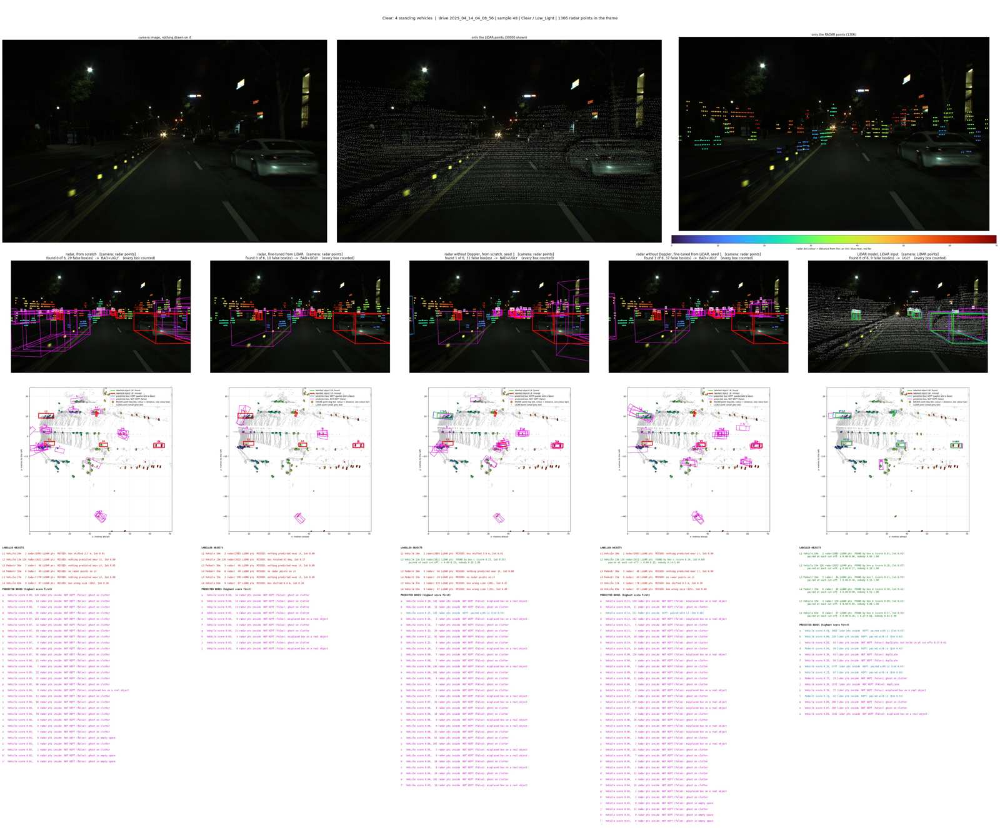

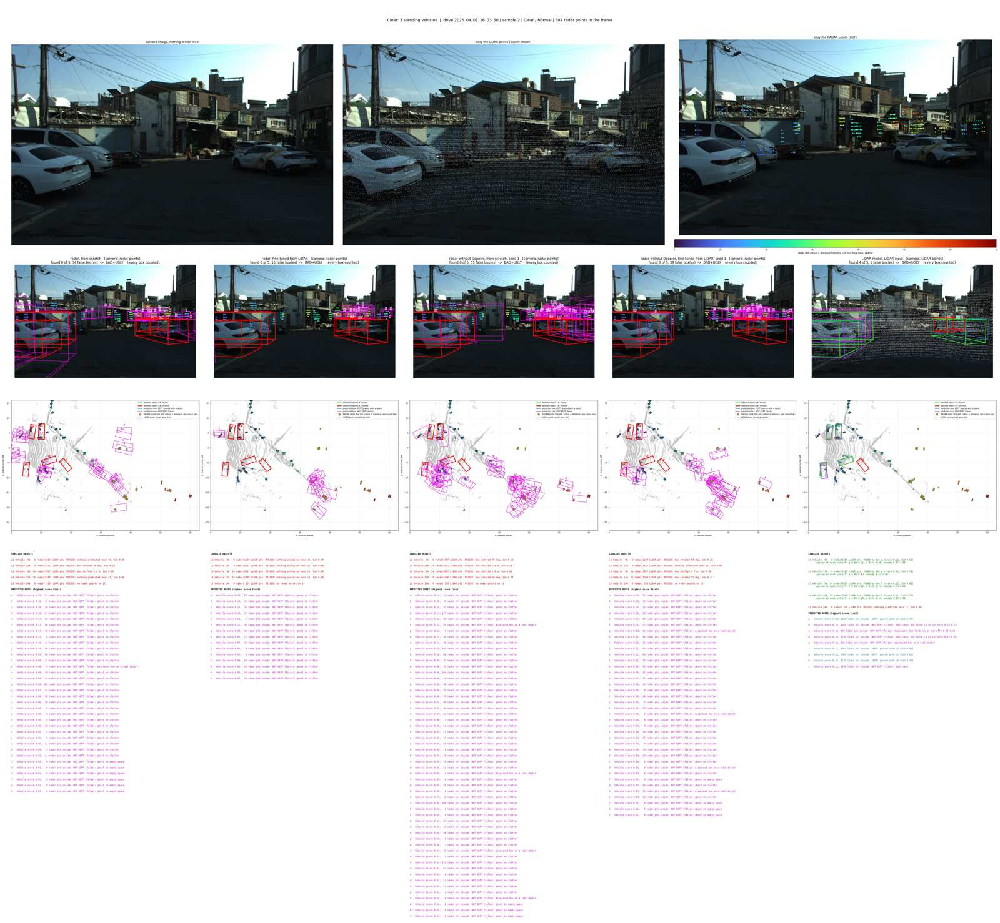

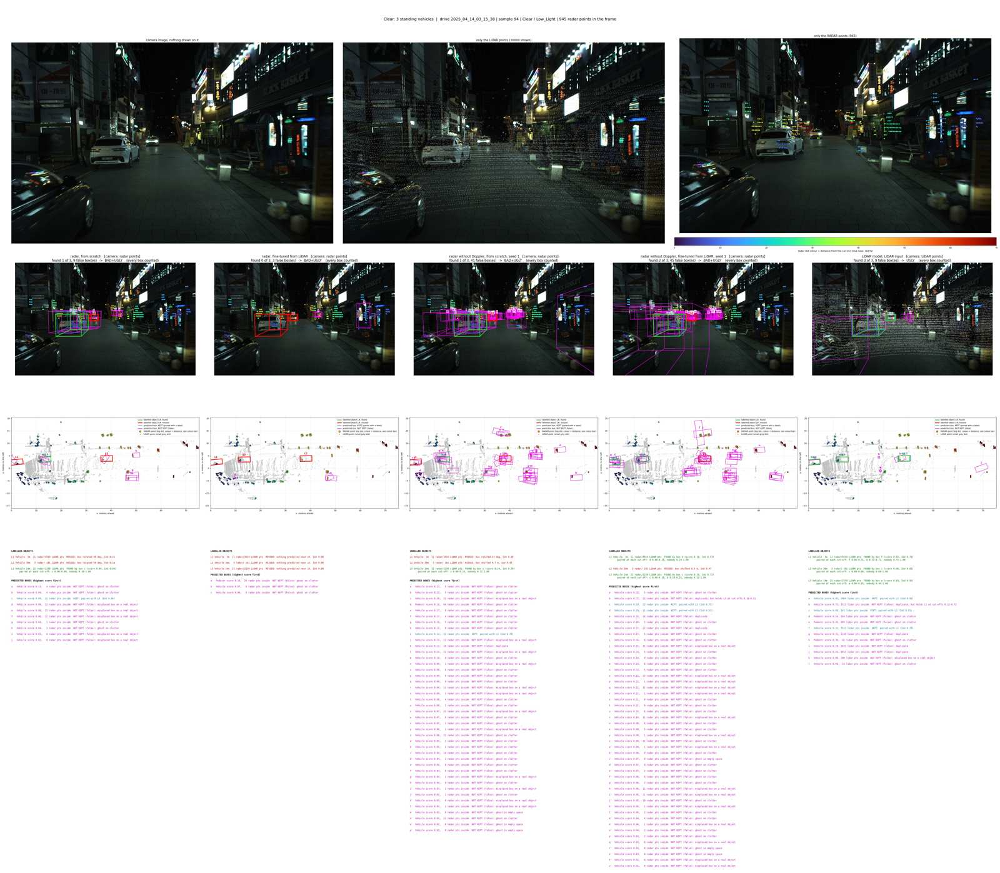

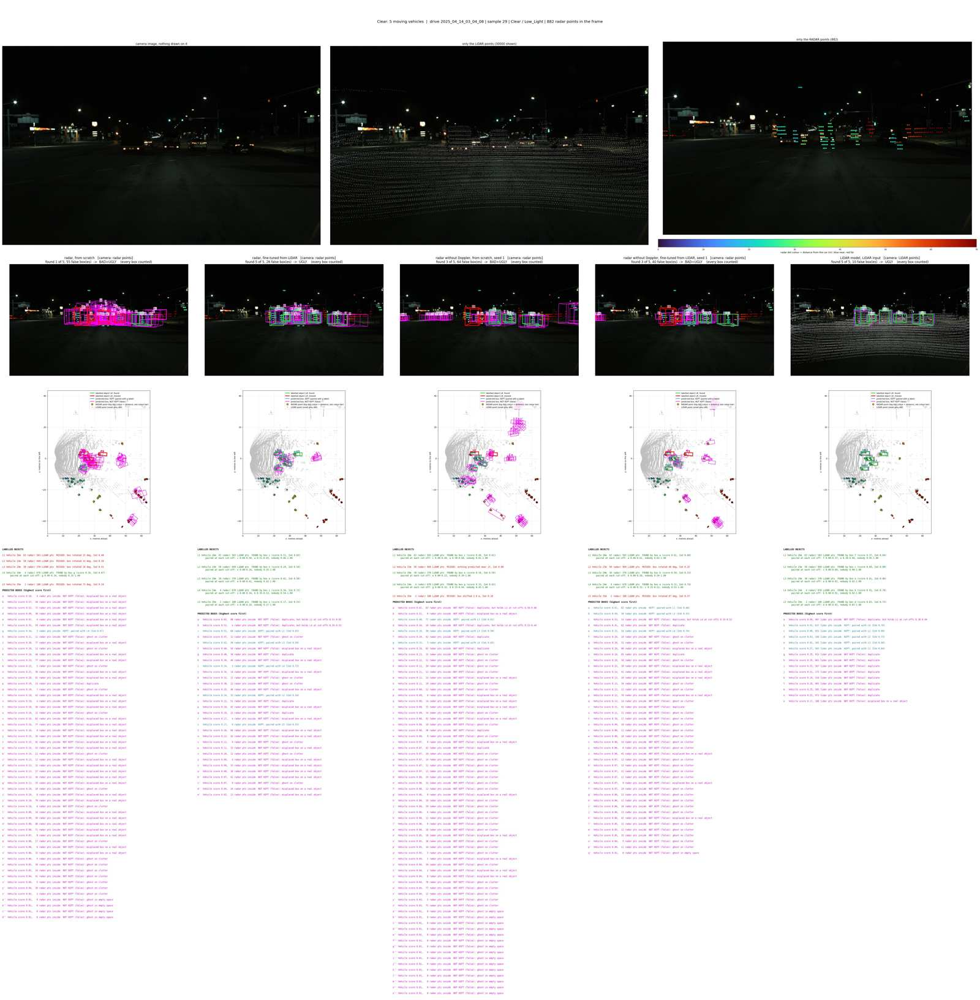

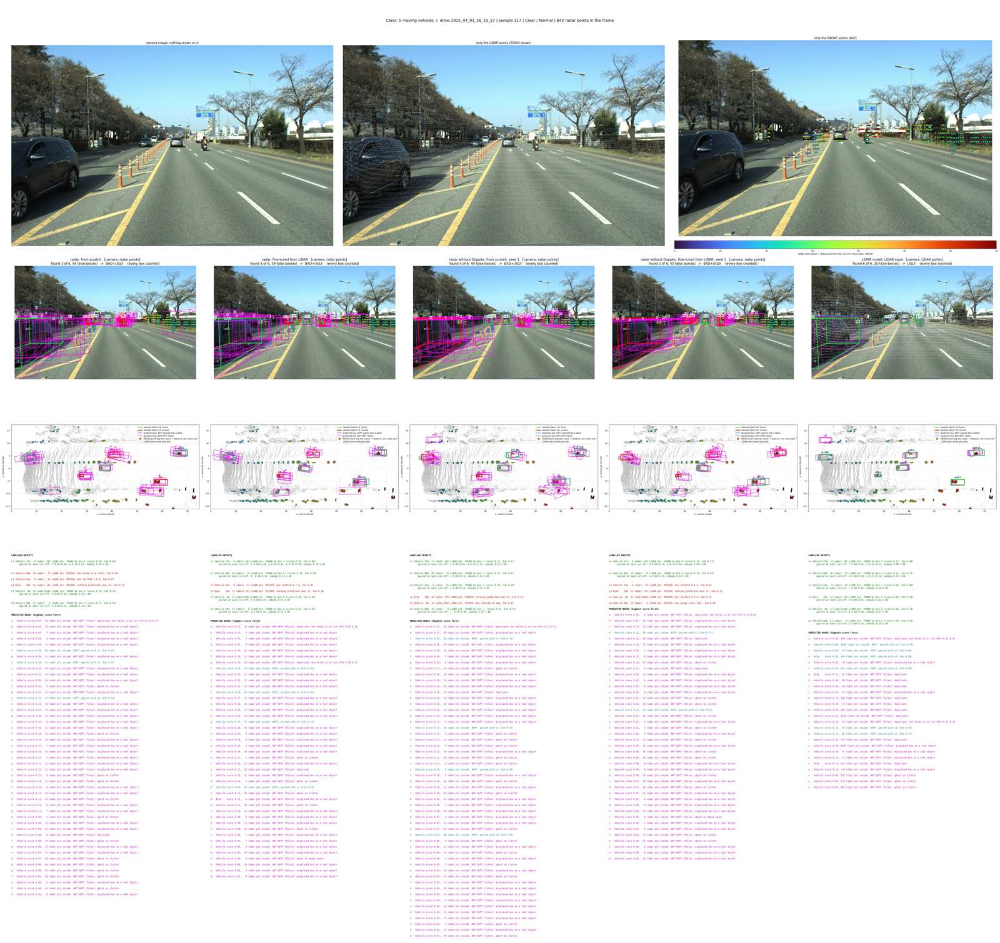

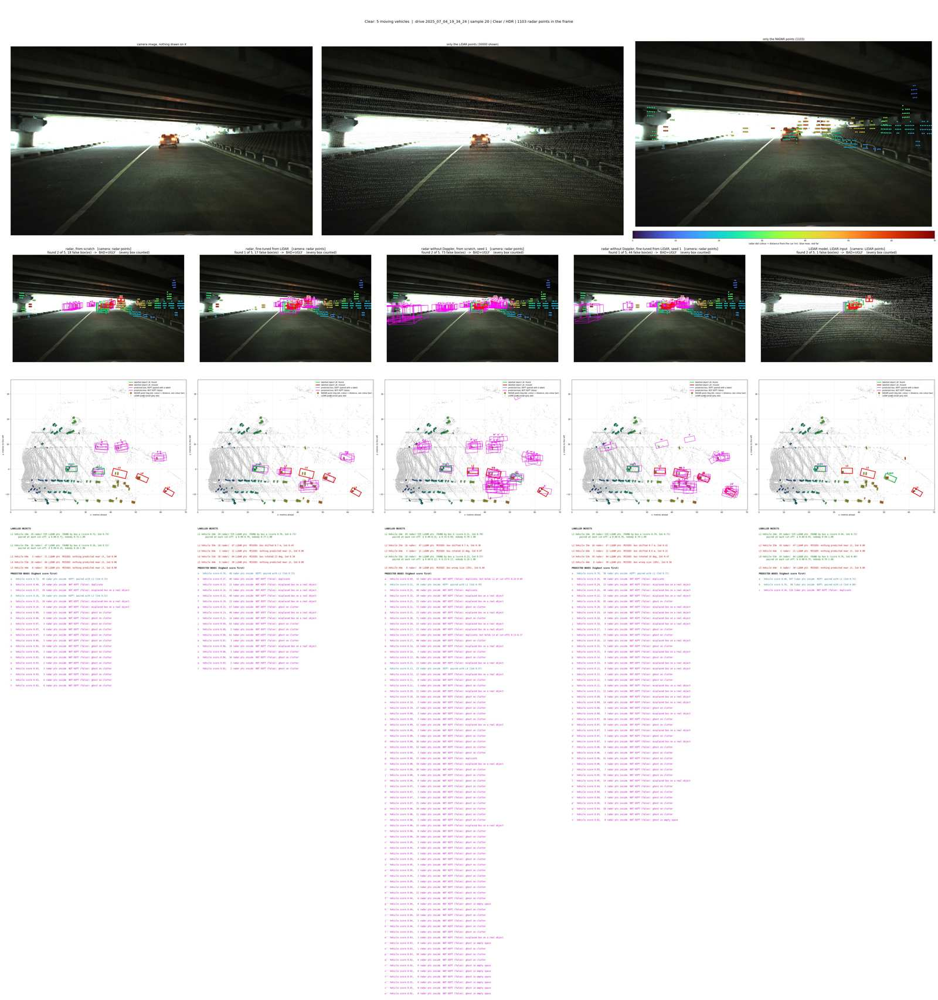

In [16]:
# Frames split by what they hold (standing = below 0.2 m/s; vehicles without a radar point have no speed and do not
# decide the split). AP over a set of frames is plain section-2 AP: every labelled vehicle of those frames counts.
known = V[V.speed_group < 5]
n_stand = known[known.speed_group == 0].groupby("k").size().reindex(range(N), fill_value=0).values
n_move = known[known.speed_group > 0].groupby("k").size().reindex(range(N), fill_value=0).values
FRAME_SETS = {"all frames": np.ones(N, bool),
              "frames with standing vehicles": n_stand > 0,
              "frames with only moving vehicles": (n_stand == 0) & (n_move > 0)}
for set_name, fmask in FRAME_SETS.items():
    masks = {w: fmask & WEATHER_MASKS[w] for w in WEATHER_MASKS}
    value = lambda m, w: vehicle_ap(*AS_IS[m], masks[w])
    T = setup_table(value, list(masks), SPEED_SETUPS).T
    T.insert(0, "labelled vehicles", [int(n_veh[masks[w]].sum()) for w in masks])
    T.insert(0, "frames", [int(masks[w].sum()) for w in masks])
    print("\nVehicle AP per weather: %s (mean ± standard deviation over the runs of each setup)" % set_name)
    display(T)
    display(gain_table(value, list(masks)).T)

# Pictures: Clear frames with the most standing vehicles next to Clear frames with the most moving vehicles
# (one frame per drive first), into pictures/6b_clear_standing_vs_moving/standing/ and .../moving/.
COMPARE_WEATHER = "Clear"
N_EACH = 3
w_mask = (FR.weather == COMPARE_WEATHER).values & FR.has_image.values
for label, mask, count in [("standing", w_mask & (n_stand > 0), n_stand), ("moving", w_mask & (n_stand == 0) & (n_move > 0), n_move)]:
    d = FR[mask].assign(n=count[mask]).sort_values("n", ascending=False)
    first = d.drop_duplicates("drive")
    for k in pd.concat([first, d.drop(first.index)]).index[:N_EACH]:
        show(int(k), models=PICTURE_MODELS, title="%s: %d %s vehicles" % (COMPARE_WEATHER, count[k], label),
             folder="6b_%s_standing_vs_moving/%s" % (COMPARE_WEATHER.lower(), label))

### The frames to look at: standing vehicles the model missed

Per weather, the frames with the most standing vehicles that `MISSED_BY_MODEL` has no box paired with. The last column
is the start of the picture's file name. Pictures: `pictures/6b_standing_missed/`.


Clear: 539 frames with a standing vehicle that 'radar, fine-tuned from LiDAR' missed (first column = frame number k)


,standing vehicles,"missed by radar, from scratch","missed by radar, fine-tuned from LiDAR","missed by radar without Doppler, from scratch, seed 1","missed by radar without Doppler, fine-tuned from LiDAR, seed 1","missed by LiDAR model, LiDAR input",drive,sample,light,picture name starts with
k,,,,,,,,,,
1841,4,4,4,3,3,0,2025_04_14_04_08_56,48,Low_Light,Clear_2025_04_14_04_08_56_s0048
812,3,3,3,3,3,0,2025_04_01_16_03_50,2,Normal,Clear_2025_04_01_16_03_50_s0002
1532,3,3,3,2,3,0,2025_04_14_03_15_38,5,Low_Light,Clear_2025_04_14_03_15_38_s0005
2001,2,2,2,0,1,1,2025_04_15_08_11_34,60,Normal,Clear_2025_04_15_08_11_34_s0060
2960,2,1,2,0,0,0,2025_06_27_02_20_51,133,Low_Light,Clear_2025_06_27_02_20_51_s0133
1256,1,1,1,1,1,0,2025_04_01_16_20_38,62,Normal,Clear_2025_04_01_16_20_38_s0062
1391,1,1,1,0,0,0,2025_04_14_03_02_53,93,Low_Light,Clear_2025_04_14_03_02_53_s0093
2749,1,1,1,1,1,0,2025_06_22_01_05_57,0,Low_Light,Clear_2025_06_22_01_05_57_s0000


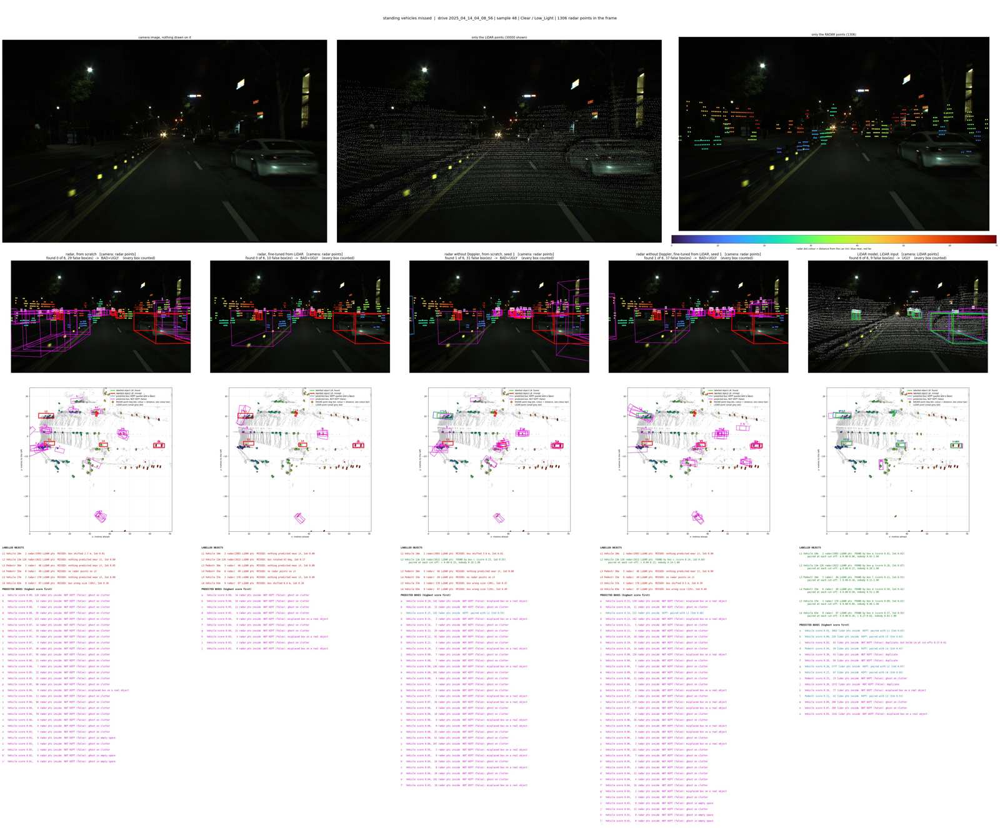

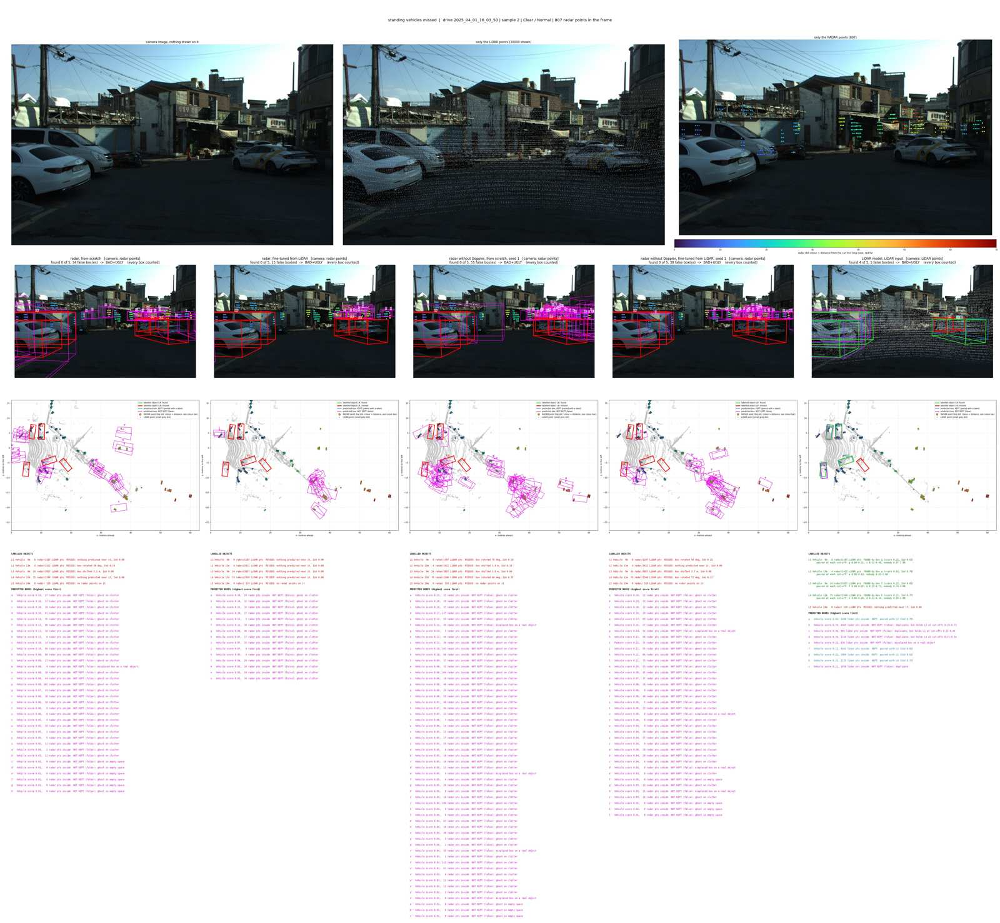


Light_Rain: 35 frames with a standing vehicle that 'radar, fine-tuned from LiDAR' missed (first column = frame number k)


,standing vehicles,"missed by radar, from scratch","missed by radar, fine-tuned from LiDAR","missed by radar without Doppler, from scratch, seed 1","missed by radar without Doppler, fine-tuned from LiDAR, seed 1","missed by LiDAR model, LiDAR input",drive,sample,light,picture name starts with
k,,,,,,,,,,
4566,1,1,1,0,1,0,2025_07_16_12_50_43,1,Normal,Light_Rain_2025_07_16_12_50_43_s0001
4693,1,0,1,0,1,0,2025_07_16_13_18_37,10,Normal,Light_Rain_2025_07_16_13_18_37_s0010
4892,1,1,1,1,1,0,2025_07_16_14_24_33,111,Normal,Light_Rain_2025_07_16_14_24_33_s0111
4576,1,0,1,1,0,0,2025_07_16_12_50_43,11,Normal,Light_Rain_2025_07_16_12_50_43_s0011
4581,1,0,1,0,0,0,2025_07_16_12_50_43,16,Normal,Light_Rain_2025_07_16_12_50_43_s0016
4694,1,0,1,0,0,0,2025_07_16_13_18_37,11,Normal,Light_Rain_2025_07_16_13_18_37_s0011
4695,1,0,1,0,0,0,2025_07_16_13_18_37,12,Normal,Light_Rain_2025_07_16_13_18_37_s0012
4696,1,0,1,1,0,0,2025_07_16_13_18_37,13,Normal,Light_Rain_2025_07_16_13_18_37_s0013


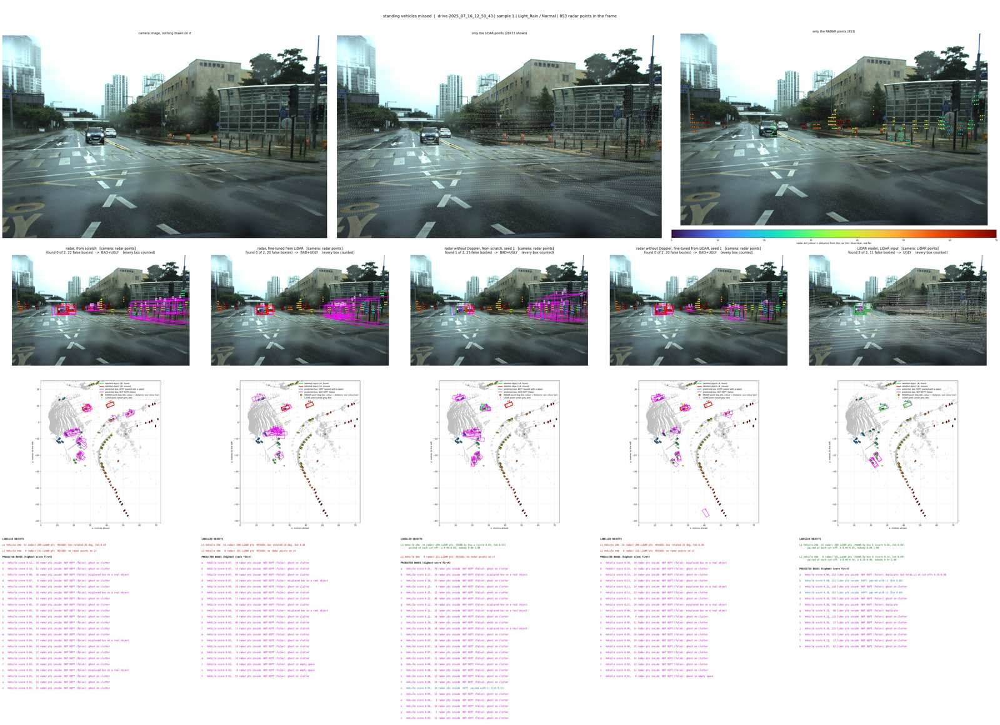

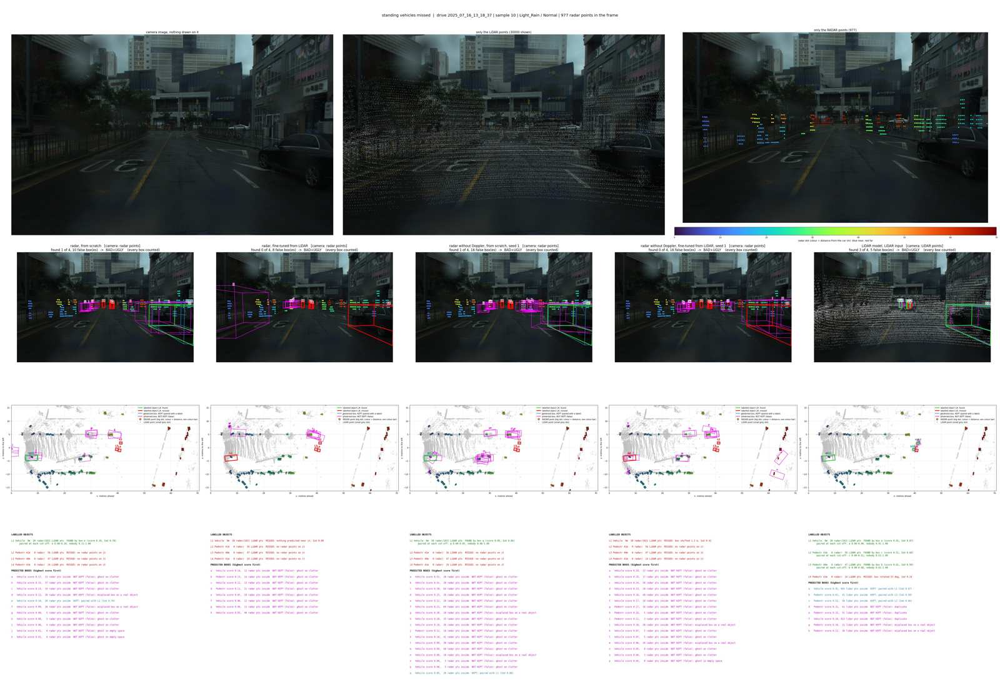


Heavy_Rain: 81 frames with a standing vehicle that 'radar, fine-tuned from LiDAR' missed (first column = frame number k)


,standing vehicles,"missed by radar, from scratch","missed by radar, fine-tuned from LiDAR","missed by radar without Doppler, from scratch, seed 1","missed by radar without Doppler, fine-tuned from LiDAR, seed 1","missed by LiDAR model, LiDAR input",drive,sample,light,picture name starts with
k,,,,,,,,,,
5119,3,2,3,2,1,1,2025_07_16_15_40_24,82,Low_Light,Heavy_Rain_2025_07_16_15_40_24_s0082
4987,2,2,2,2,2,1,2025_07_16_15_04_01,58,Normal,Heavy_Rain_2025_07_16_15_04_01_s0058
5425,1,1,1,0,1,0,2025_07_16_23_28_18,0,Low_Light,Heavy_Rain_2025_07_16_23_28_18_s0000
5127,3,3,3,1,3,1,2025_07_16_15_40_24,90,Low_Light,Heavy_Rain_2025_07_16_15_40_24_s0090
5111,3,2,2,1,1,1,2025_07_16_15_40_24,74,Low_Light,Heavy_Rain_2025_07_16_15_40_24_s0074
5112,3,2,2,1,1,1,2025_07_16_15_40_24,75,Low_Light,Heavy_Rain_2025_07_16_15_40_24_s0075
5113,3,3,2,2,3,1,2025_07_16_15_40_24,76,Low_Light,Heavy_Rain_2025_07_16_15_40_24_s0076
5115,3,2,2,1,2,1,2025_07_16_15_40_24,78,Low_Light,Heavy_Rain_2025_07_16_15_40_24_s0078


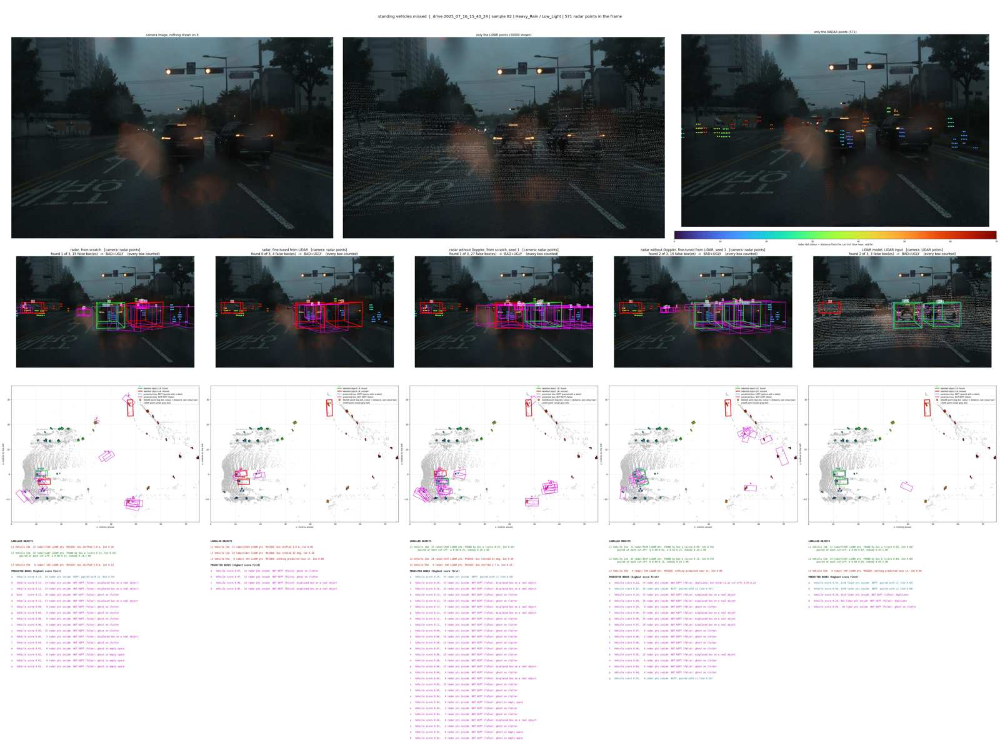

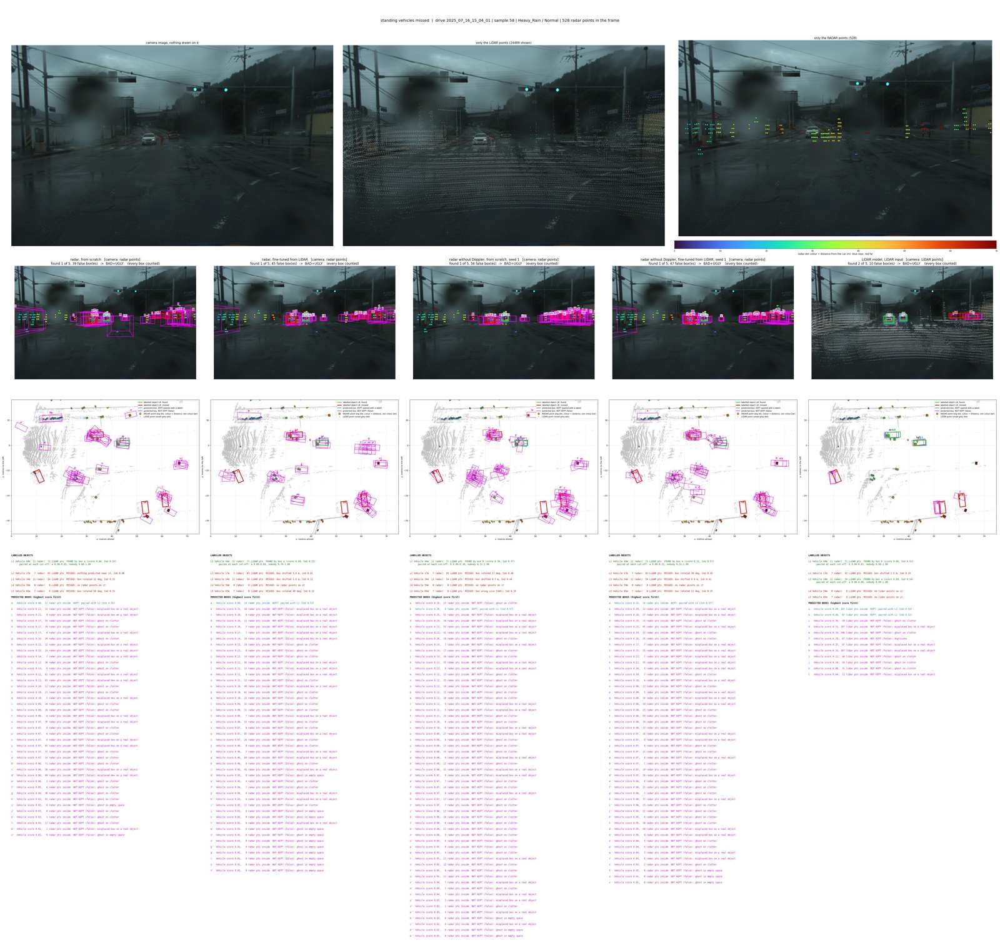


Fog: 1 frames with a standing vehicle that 'radar, fine-tuned from LiDAR' missed (first column = frame number k)


,standing vehicles,"missed by radar, from scratch","missed by radar, fine-tuned from LiDAR","missed by radar without Doppler, from scratch, seed 1","missed by radar without Doppler, fine-tuned from LiDAR, seed 1","missed by LiDAR model, LiDAR input",drive,sample,light,picture name starts with
k,,,,,,,,,,
2475,1,1,1,0,0,0,2025_04_16_07_00_04,5,Over_Expose,Fog_2025_04_16_07_00_04_s0005


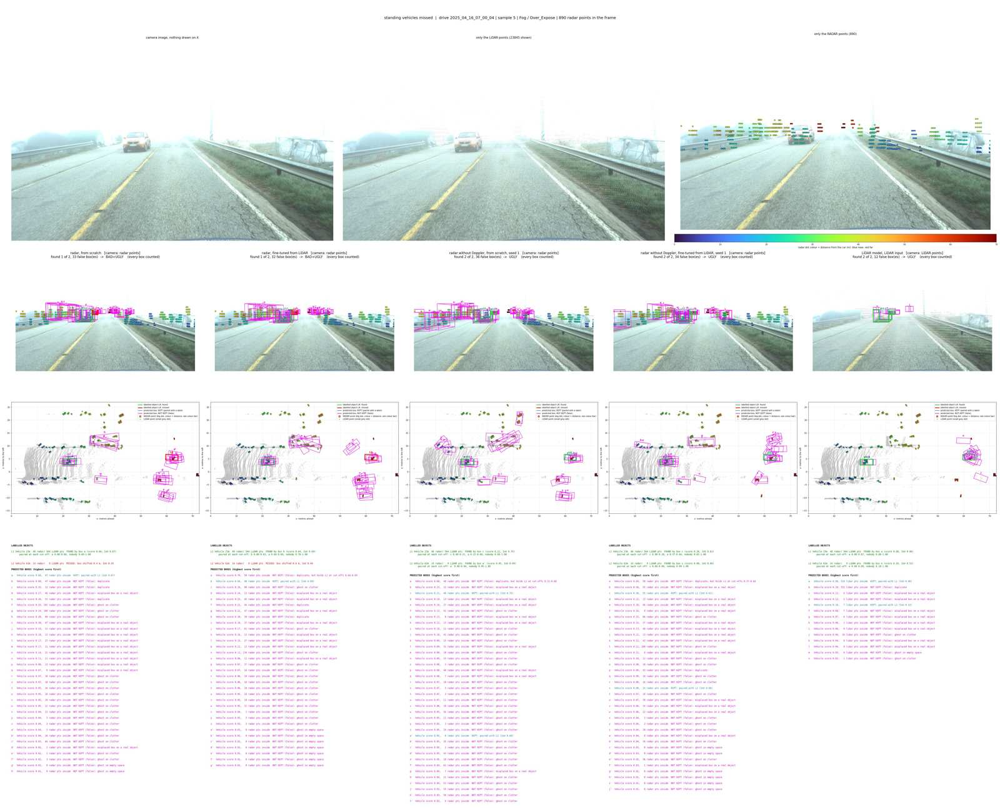


Light_Snow: 40 frames with a standing vehicle that 'radar, fine-tuned from LiDAR' missed (first column = frame number k)


,standing vehicles,"missed by radar, from scratch","missed by radar, fine-tuned from LiDAR","missed by radar without Doppler, from scratch, seed 1","missed by radar without Doppler, fine-tuned from LiDAR, seed 1","missed by LiDAR model, LiDAR input",drive,sample,light,picture name starts with
k,,,,,,,,,,
145,2,2,2,2,2,1,2025_02_12_04_42_55,0,Low_Light,Light_Snow_2025_02_12_04_42_55_s0000
339,2,2,1,2,1,0,2025_02_12_04_58_35,17,Low_Light,Light_Snow_2025_02_12_04_58_35_s0017
146,2,2,2,2,2,1,2025_02_12_04_42_55,1,Low_Light,Light_Snow_2025_02_12_04_42_55_s0001
149,2,2,2,2,2,1,2025_02_12_04_42_55,4,Low_Light,Light_Snow_2025_02_12_04_42_55_s0004
150,2,2,2,2,2,1,2025_02_12_04_42_55,5,Low_Light,Light_Snow_2025_02_12_04_42_55_s0005
151,2,2,2,2,2,1,2025_02_12_04_42_55,6,Low_Light,Light_Snow_2025_02_12_04_42_55_s0006
152,2,2,2,2,2,1,2025_02_12_04_42_55,7,Low_Light,Light_Snow_2025_02_12_04_42_55_s0007
153,2,2,2,2,2,0,2025_02_12_04_42_55,8,Low_Light,Light_Snow_2025_02_12_04_42_55_s0008


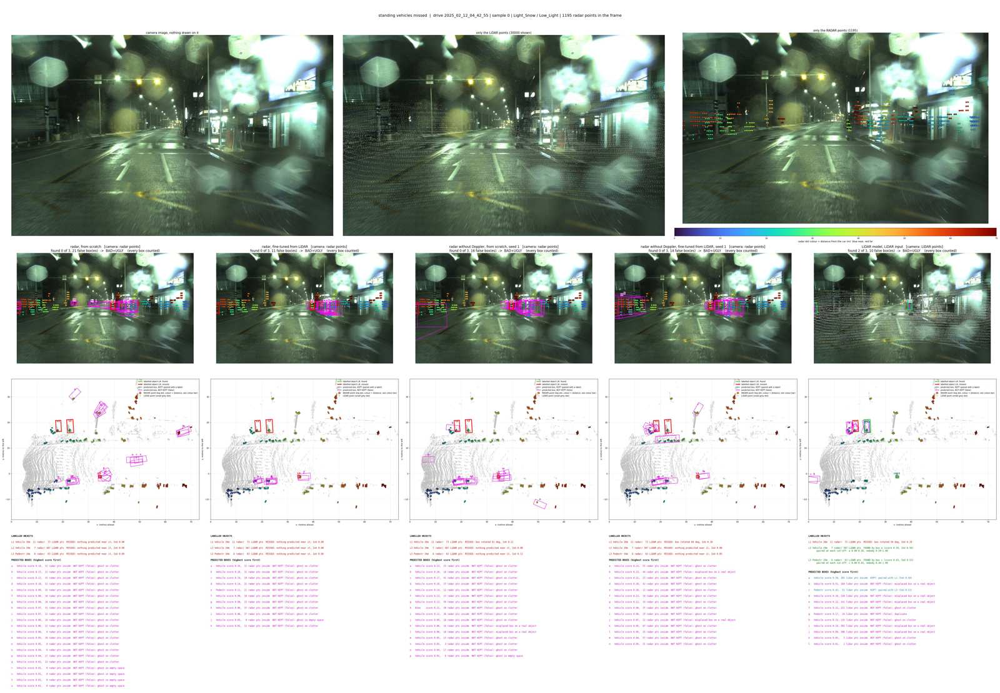

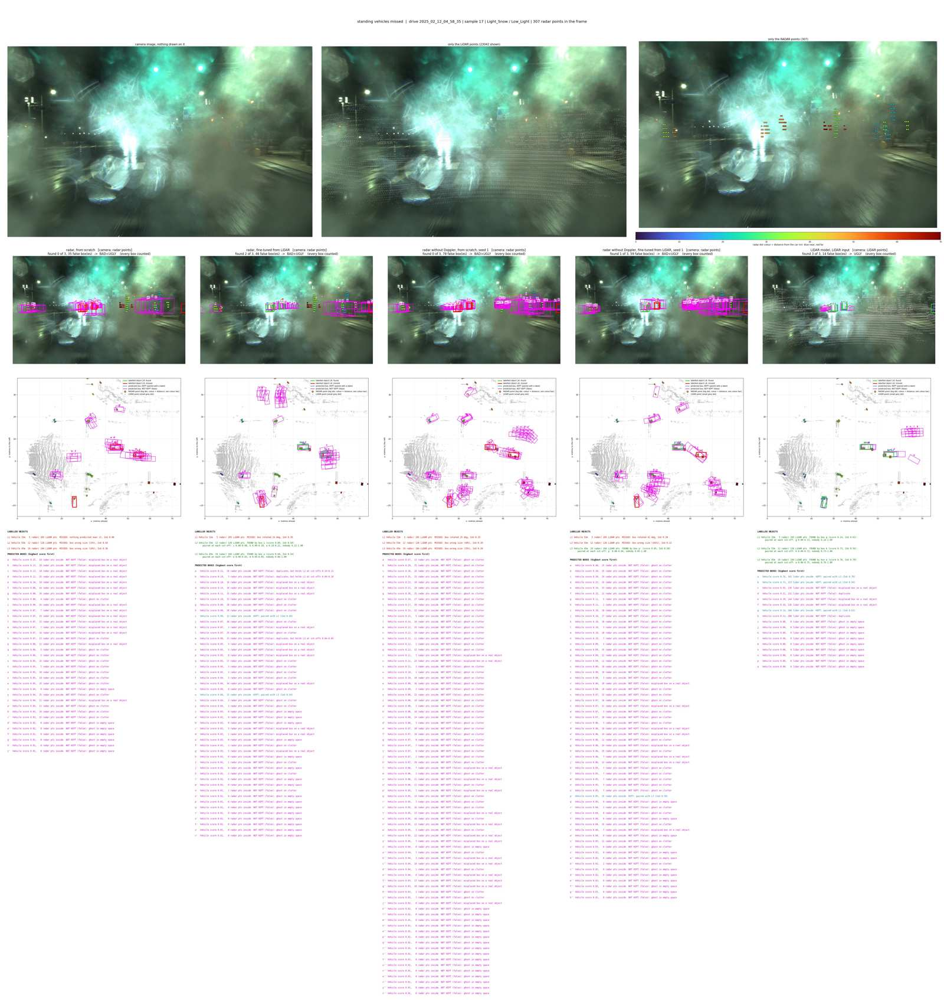


Heavy_Snow: 2 frames with a standing vehicle that 'radar, fine-tuned from LiDAR' missed (first column = frame number k)


,standing vehicles,"missed by radar, from scratch","missed by radar, fine-tuned from LiDAR","missed by radar without Doppler, from scratch, seed 1","missed by radar without Doppler, fine-tuned from LiDAR, seed 1","missed by LiDAR model, LiDAR input",drive,sample,light,picture name starts with
k,,,,,,,,,,
438,1,0,1,1,1,1,2025_02_12_05_29_33,5,Normal,Heavy_Snow_2025_02_12_05_29_33_s0005
459,1,1,1,1,1,1,2025_02_12_05_29_33,26,Normal,Heavy_Snow_2025_02_12_05_29_33_s0026


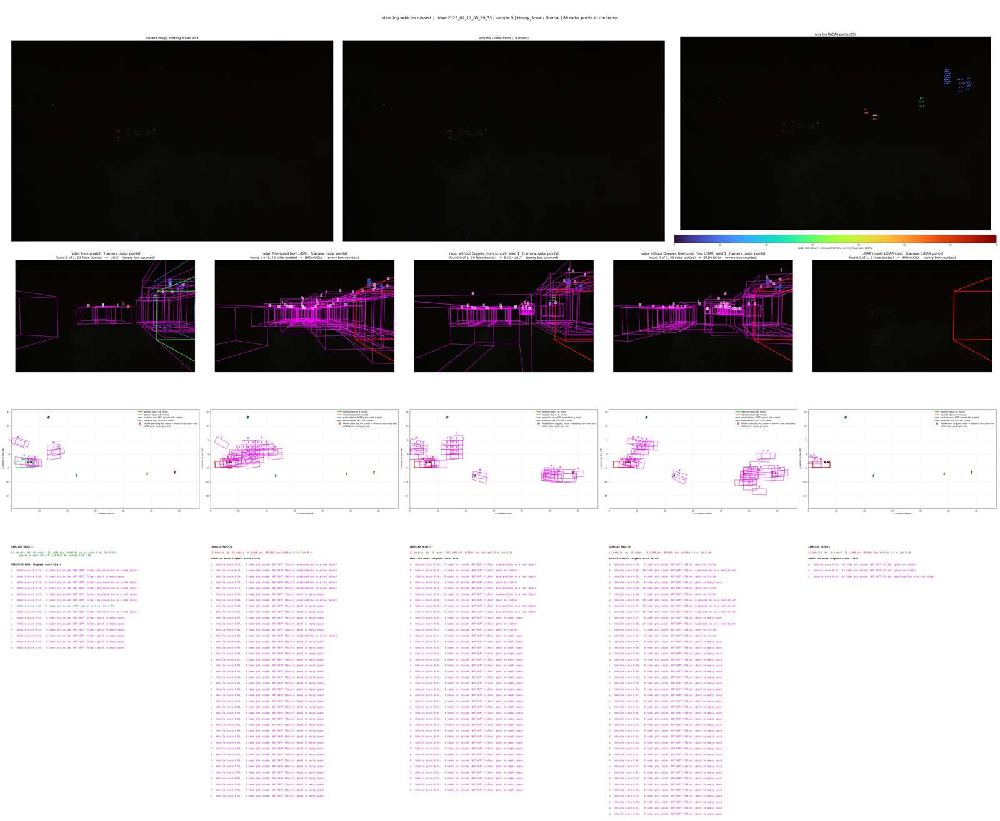

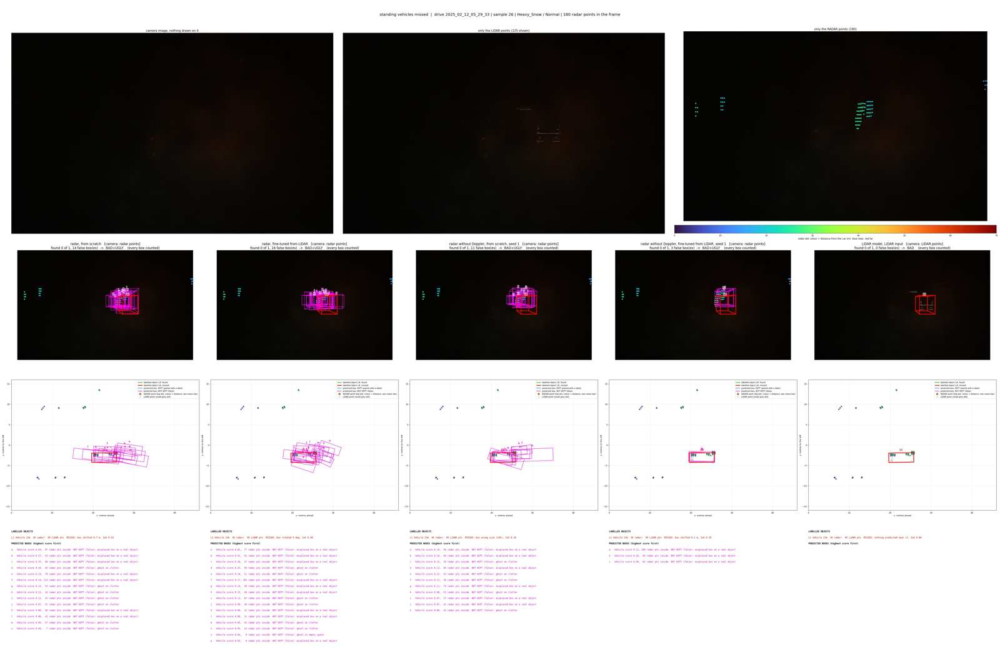

In [17]:
# The frames to look at: per weather, the frames with the most standing vehicles that MISSED_BY_MODEL missed
# (missed = no predicted box paired with it, every box counted).
MISSED_BY_MODEL = "radar_ft_from_livox"
N_EACH = 2                              # pictures per weather (0 = only the list)
N_LISTED = 8                            # frames listed per weather
for m in PICTURE_MODELS:
    p = PRED[(PRED.model == m) & PRED.status.isin(["TP", "IGNORED"])]
    V = V.assign(**{"found_" + m: pd.MultiIndex.from_arrays([V.k, V.j]).isin(pd.MultiIndex.from_arrays([p.k, p.matched_gt]))})
agg = {"standing vehicles": ("j", "size")}
agg.update({"missed by " + NAME.get(m, m): ("found_" + m, lambda v: int((~v).sum())) for m in PICTURE_MODELS})
PARKED = V[V.speed_group == 0].groupby("k").agg(**agg).join(FR[["weather", "drive", "sample", "light", "has_image"]])
PARKED["picture name starts with"] = PARKED.weather + "_" + PARKED.drive + "_s" + PARKED["sample"].map("{:04d}".format)
key = "missed by " + NAME.get(MISSED_BY_MODEL, MISSED_BY_MODEL)
for w in WEATHERS:
    d = PARKED[(PARKED.weather == w) & (PARKED[key] > 0)].sort_values([key, "standing vehicles"], ascending=False)
    first = d.drop_duplicates("drive")                     # one per drive first, then the rest
    d = pd.concat([first, d.drop(first.index)])
    print("\n%s: %d frames with a standing vehicle that '%s' missed (first column = frame number k)"
          % (w, len(d), NAME.get(MISSED_BY_MODEL, MISSED_BY_MODEL)))
    display(d.drop(columns=["weather", "has_image"]).head(N_LISTED))
    for k in d[d.has_image].index[:N_EACH]:
        show(int(k), models=PICTURE_MODELS, title="standing vehicles missed", folder="6b_standing_missed")

## 6c. Worst and best drives

Every validation drive with its Vehicle AP (the drive's frames only), sorted worst first for the model in `RANK_BY`.
Then `N_FRAMES` pictures of each of the `N_DRIVES` worst and best drives, one folder per drive:
`pictures/6c_worst_and_best_drives/worst_1_<weather>_<drive>/`, `.../best_1_<weather>_<drive>/`, and so on.

Every validation drive, worst Vehicle AP of 'radar, fine-tuned from LiDAR' first (AP over the drive's frames, computed as in section 2)


,weather,light,frames,labelled vehicles,standing,no radar point,median distance (m),"AP radar, from scratch","AP radar, fine-tuned from LiDAR","AP LiDAR model, LiDAR input"
2025_02_12_04_42_55,Light_Snow,Low_Light,56,47,100%,15%,24.0,0.000,0.000,0.538
2025_04_14_03_15_38,Clear,Low_Light,118,342,100%,30%,23.0,0.039,0.000,0.969
2025_02_12_04_47_25,Light_Snow,Low_Light,68,57,0%,0%,46.0,0.019,0.020,0.950
2025_07_16_13_18_37,Light_Rain,Normal,98,58,33%,17%,43.0,0.050,0.042,0.747
2025_07_06_18_32_58,Clear,Over_Expose,148,207,0%,4%,52.0,0.130,0.065,0.954
2025_04_14_04_08_56,Clear,Low_Light,148,438,87%,8%,39.0,0.071,0.066,0.910
2025_04_15_08_11_34,Clear,Normal,100,152,100%,6%,35.0,0.048,0.067,0.784
2025_04_01_16_03_50,Clear,Normal,76,242,53%,35%,9.0,0.031,0.067,0.829
2025_04_01_16_20_38,Clear,Normal,104,189,1%,5%,61.0,0.016,0.071,0.700
2025_02_12_05_29_33,Heavy_Snow,Normal,92,89,10%,43%,39.0,0.022,0.079,0.503



WORST 1: drive 2025_04_14_03_15_38 | Clear / Low_Light | 342 labelled vehicles, 100% standing | radar, from scratch AP 0.039, radar, fine-tuned from LiDAR AP 0.000, LiDAR model, LiDAR input AP 0.969


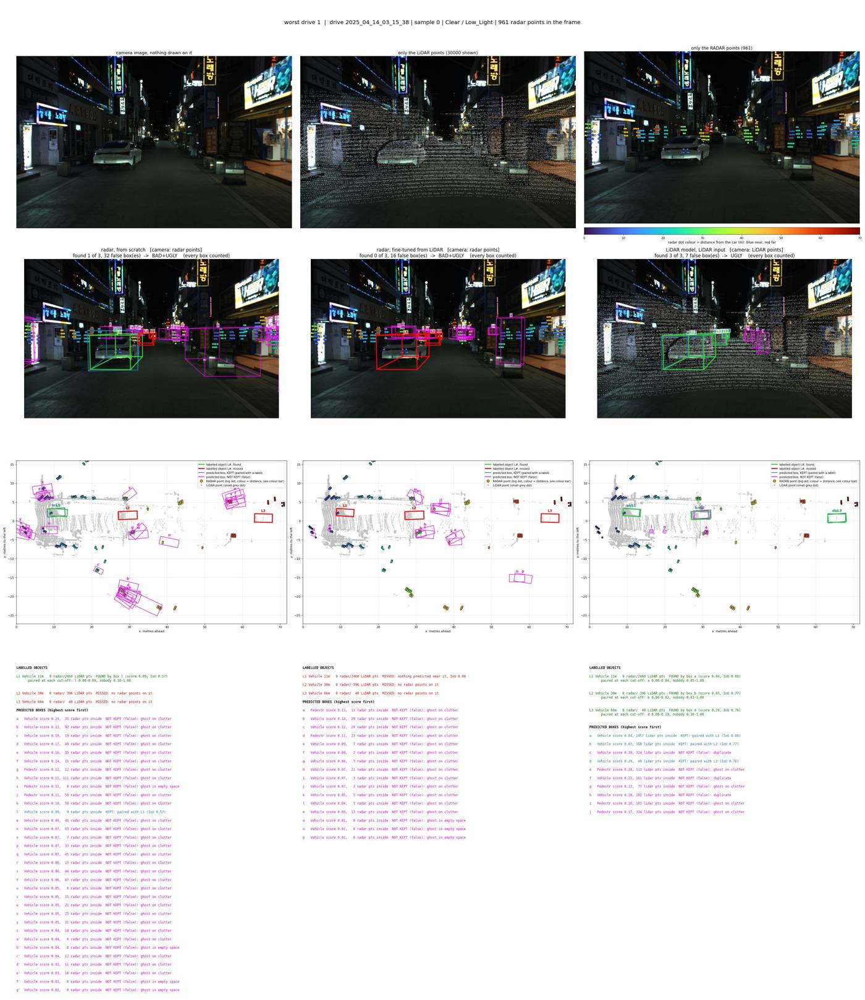

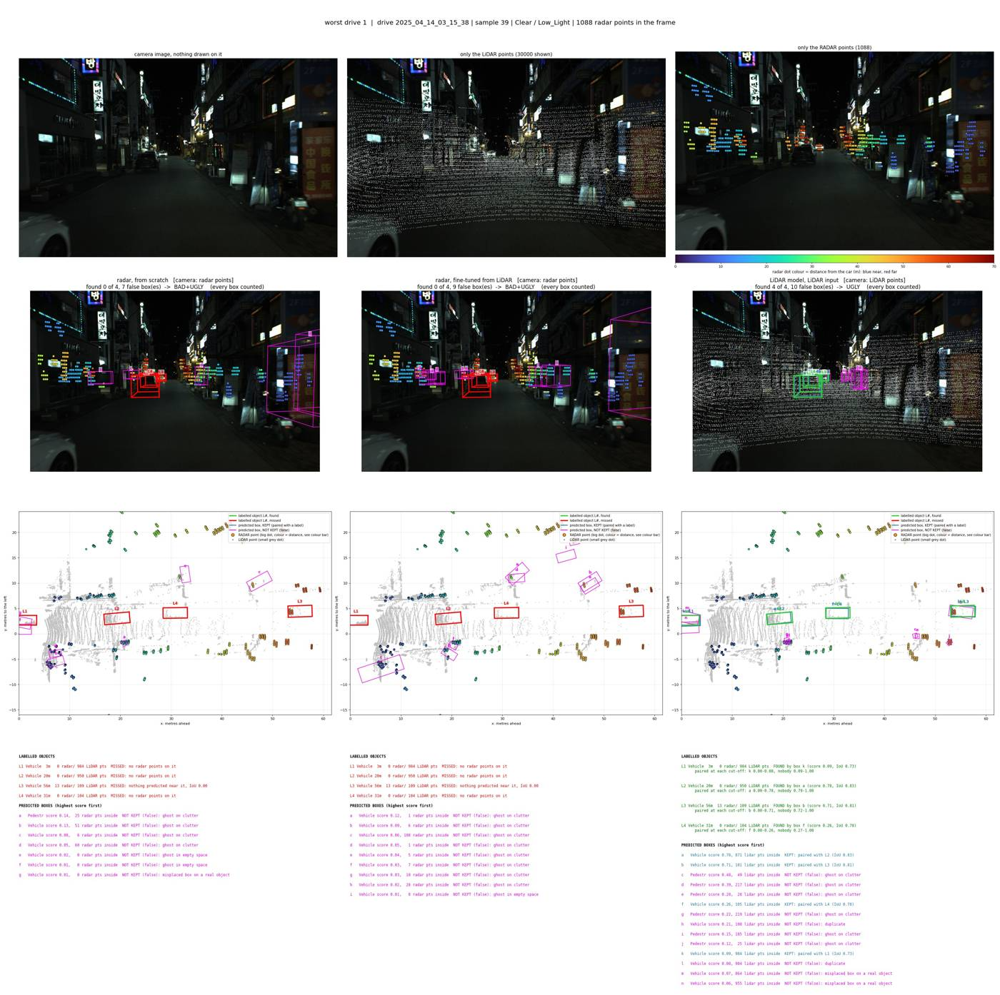

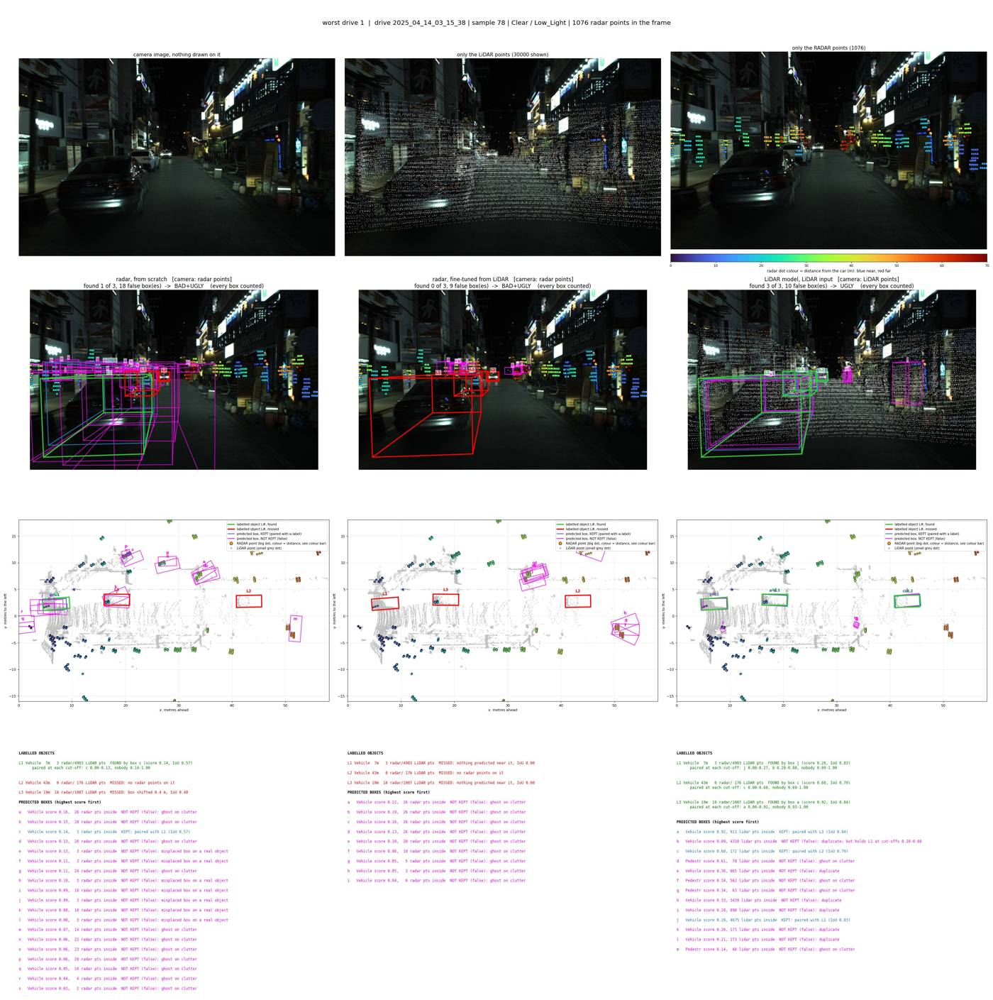

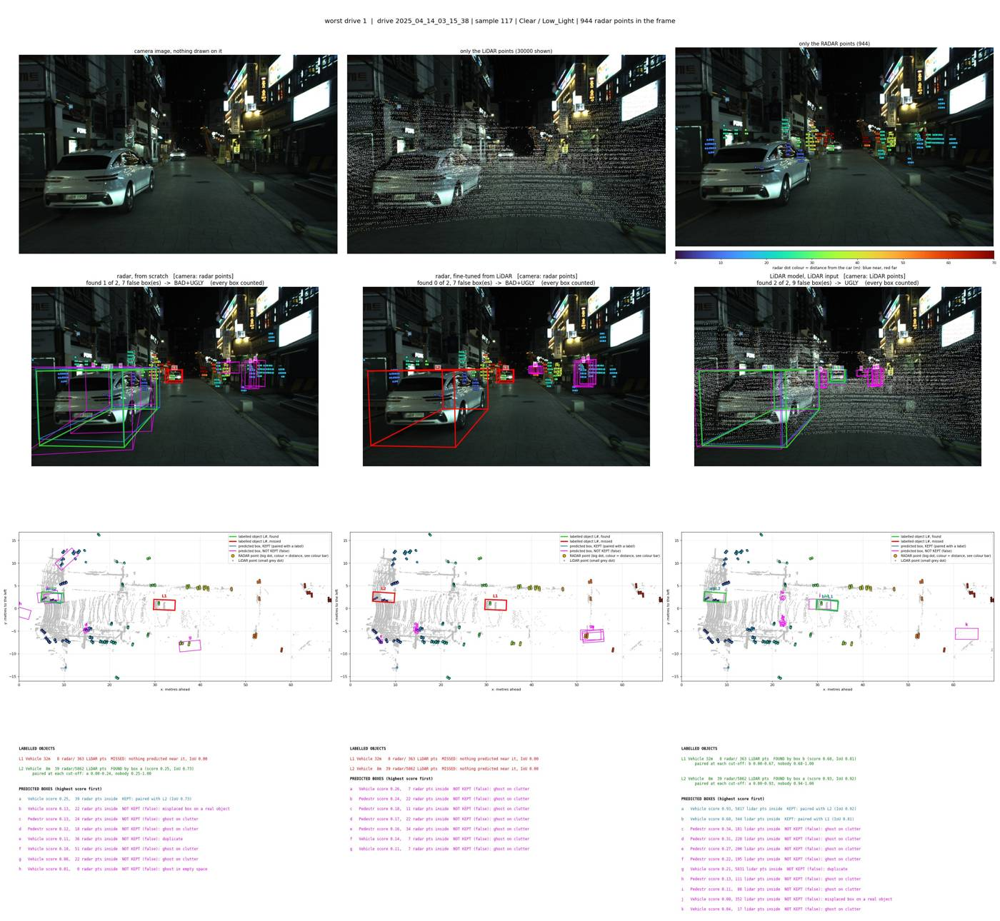


WORST 2: drive 2025_02_12_04_47_25 | Light_Snow / Low_Light | 57 labelled vehicles, 0% standing | radar, from scratch AP 0.019, radar, fine-tuned from LiDAR AP 0.020, LiDAR model, LiDAR input AP 0.950


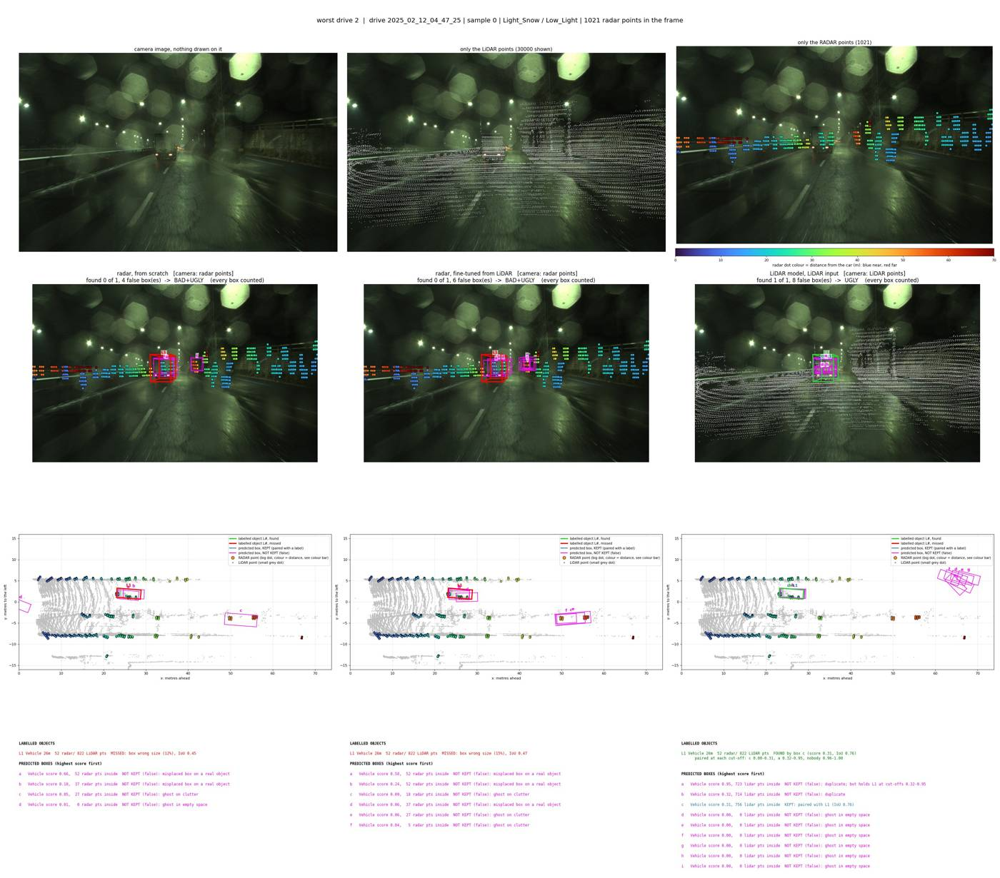

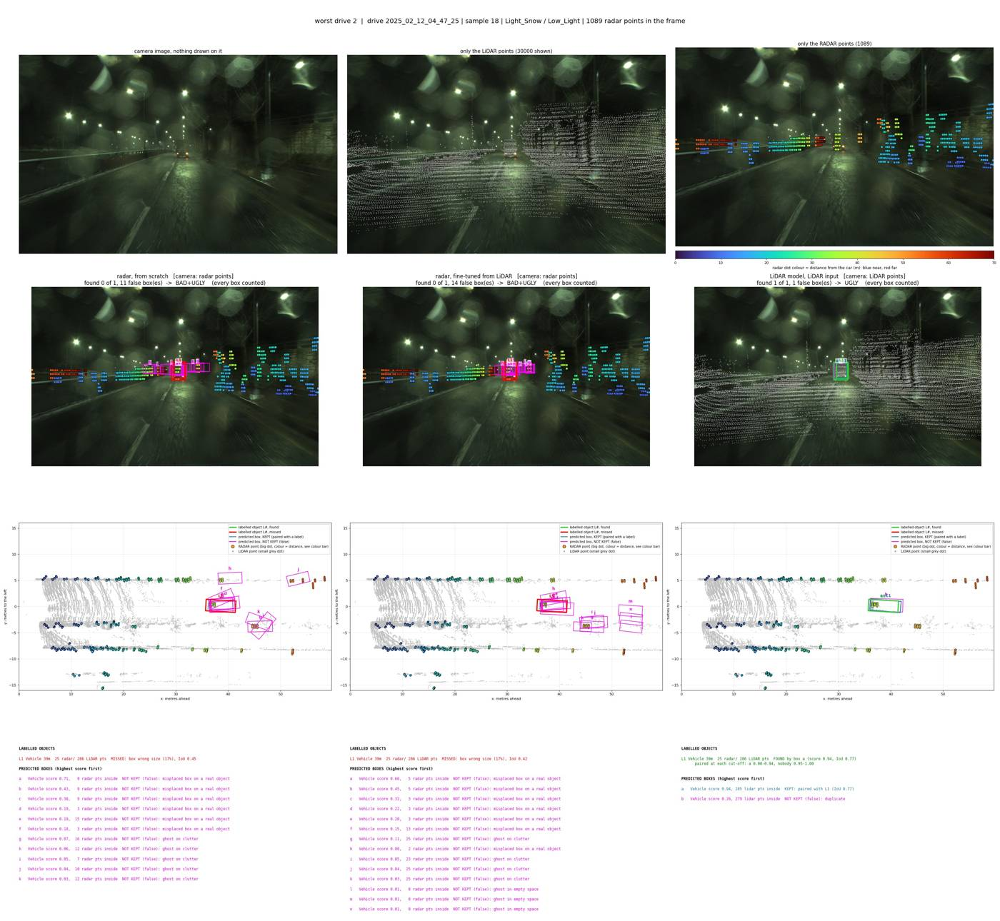

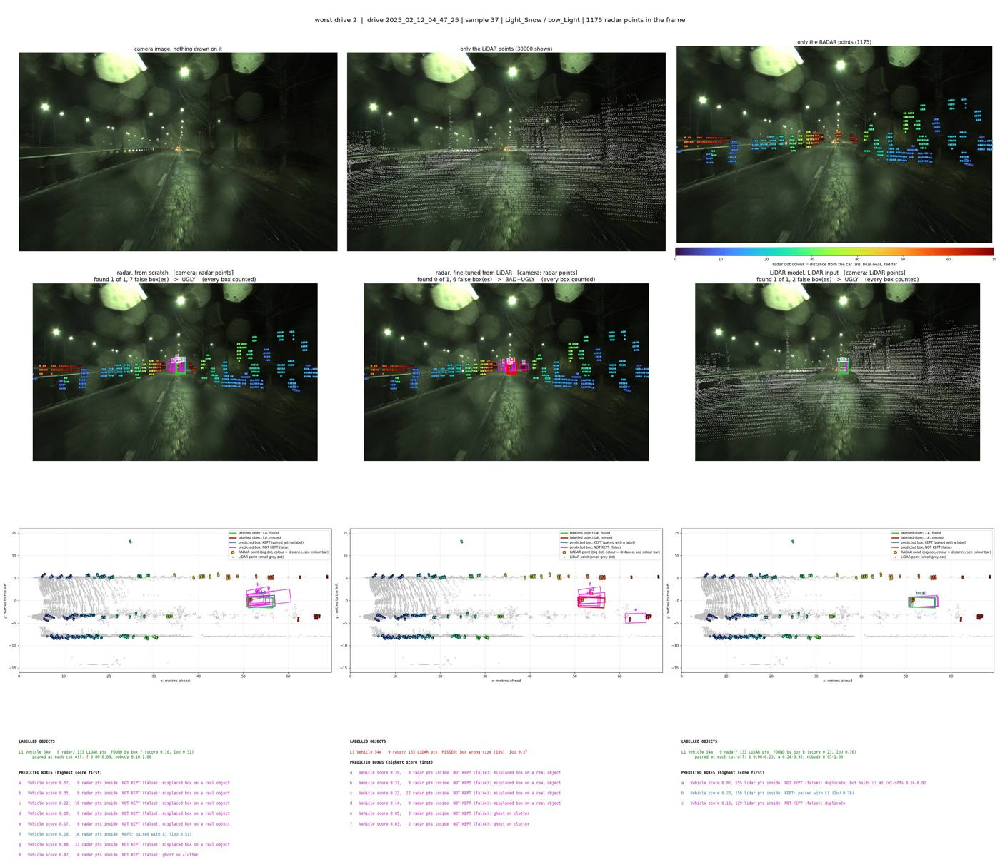

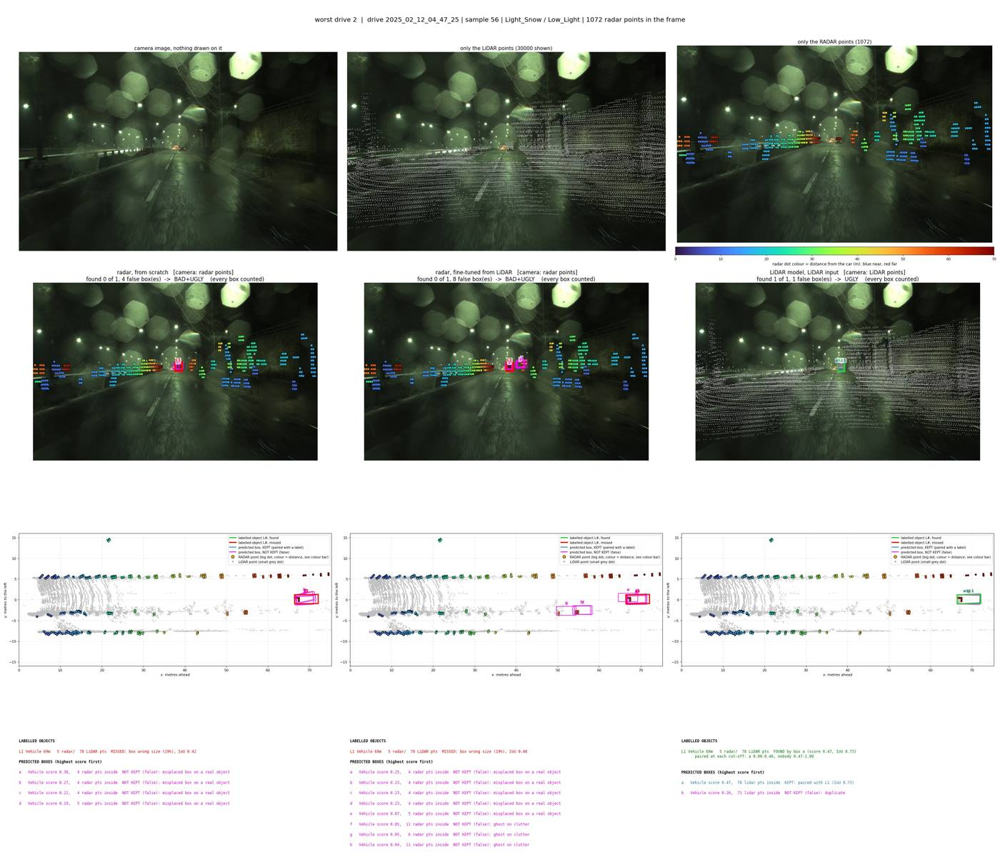


WORST 3: drive 2025_07_16_13_18_37 | Light_Rain / Normal | 58 labelled vehicles, 33% standing | radar, from scratch AP 0.050, radar, fine-tuned from LiDAR AP 0.042, LiDAR model, LiDAR input AP 0.747


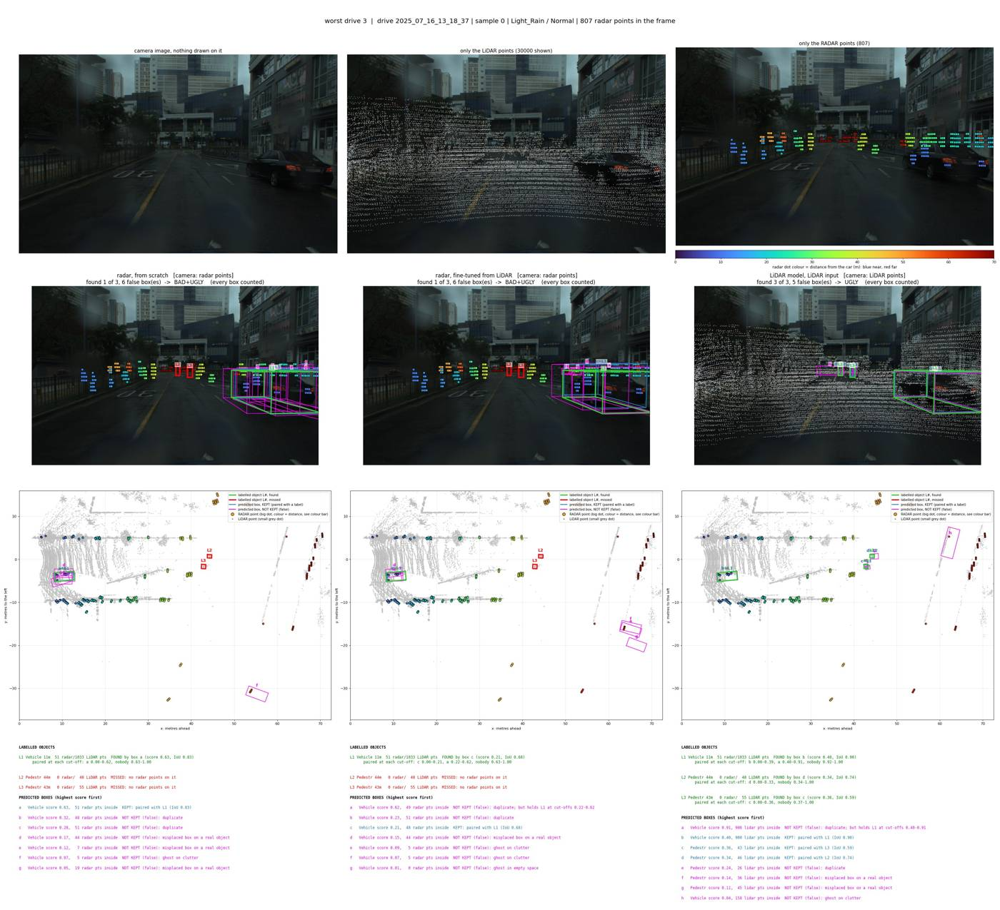

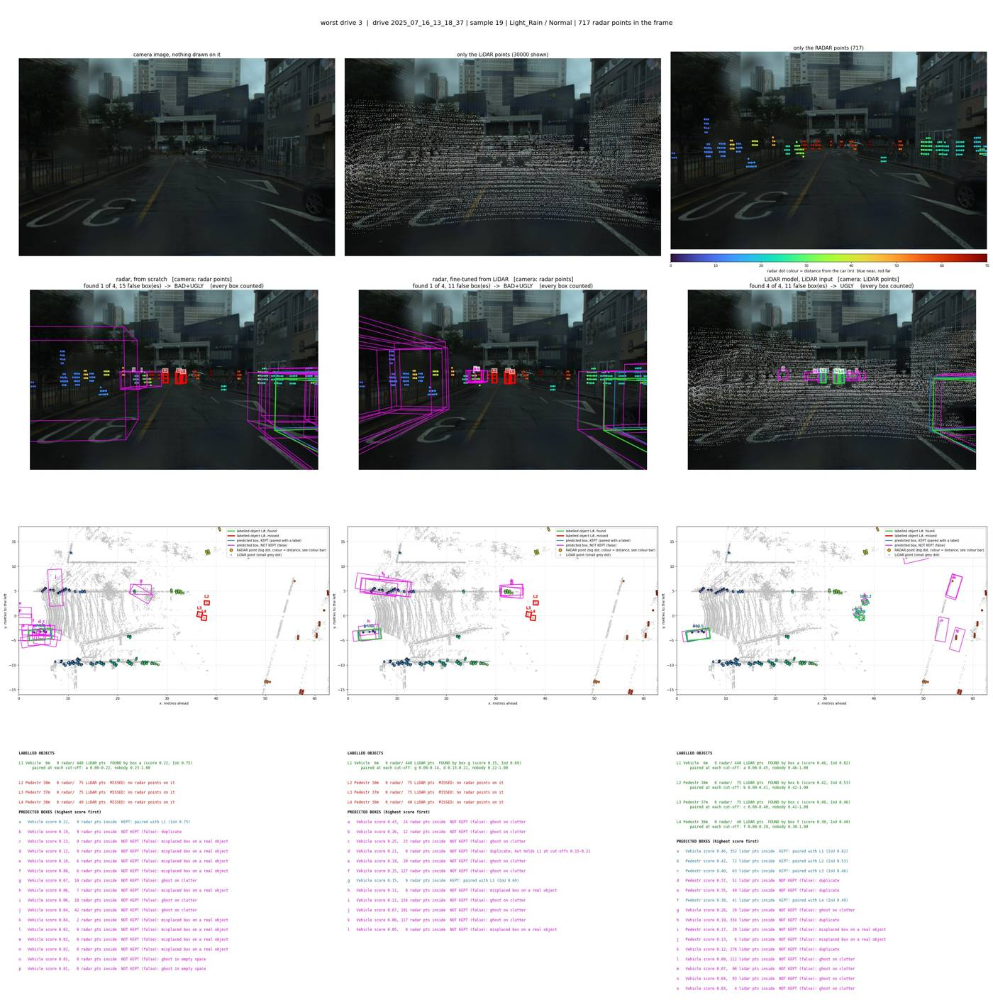

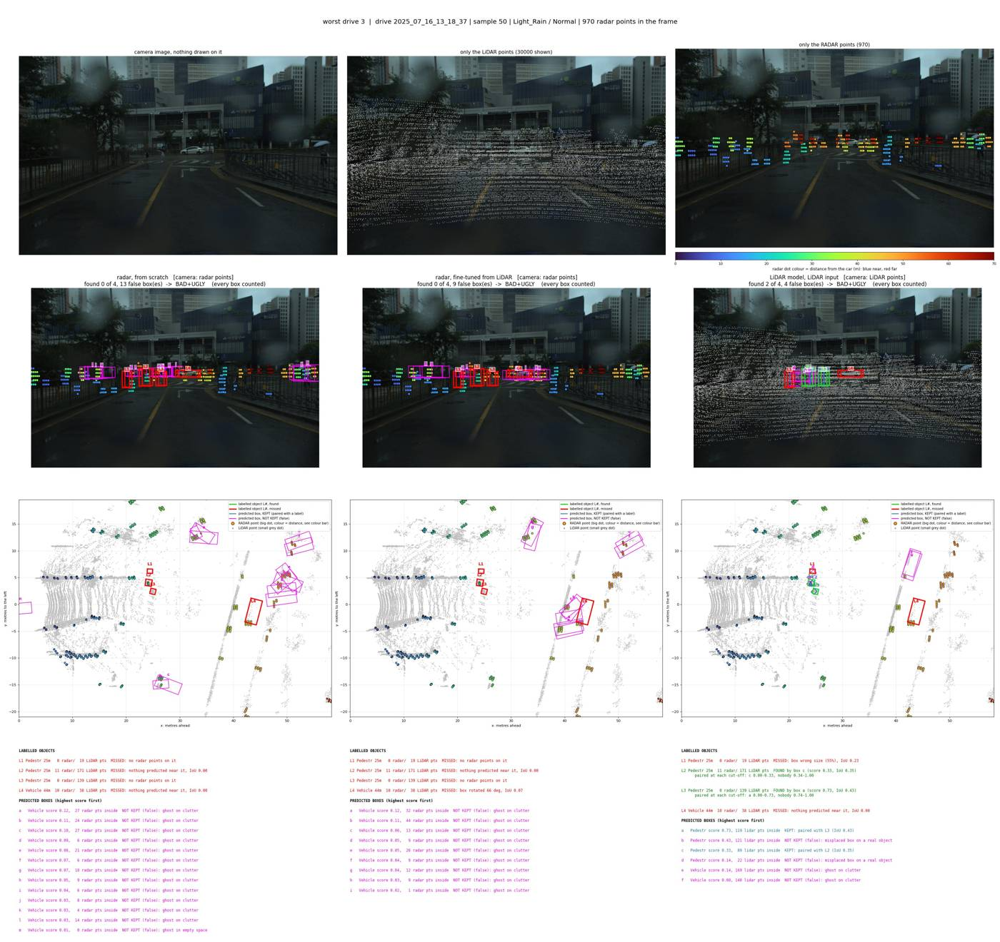

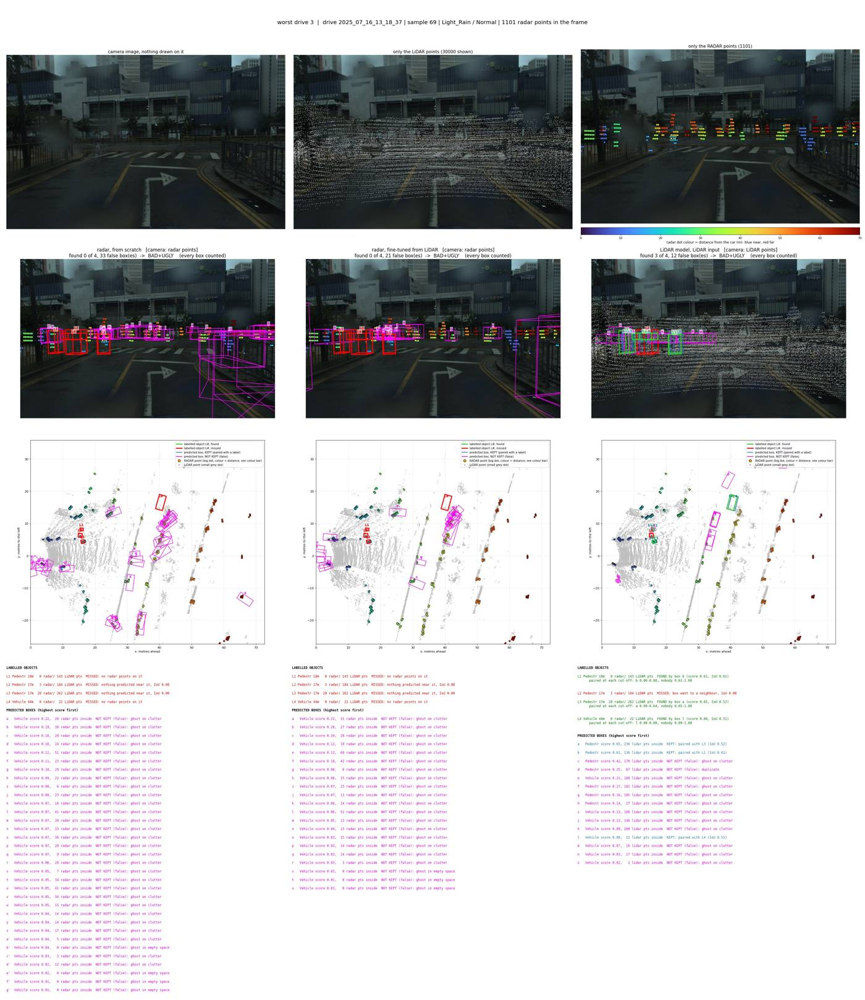


BEST 1: drive 2025_04_16_06_09_59 | Fog / Over_Expose | 75 labelled vehicles, 0% standing | radar, from scratch AP 0.916, radar, fine-tuned from LiDAR AP 0.954, LiDAR model, LiDAR input AP 0.967


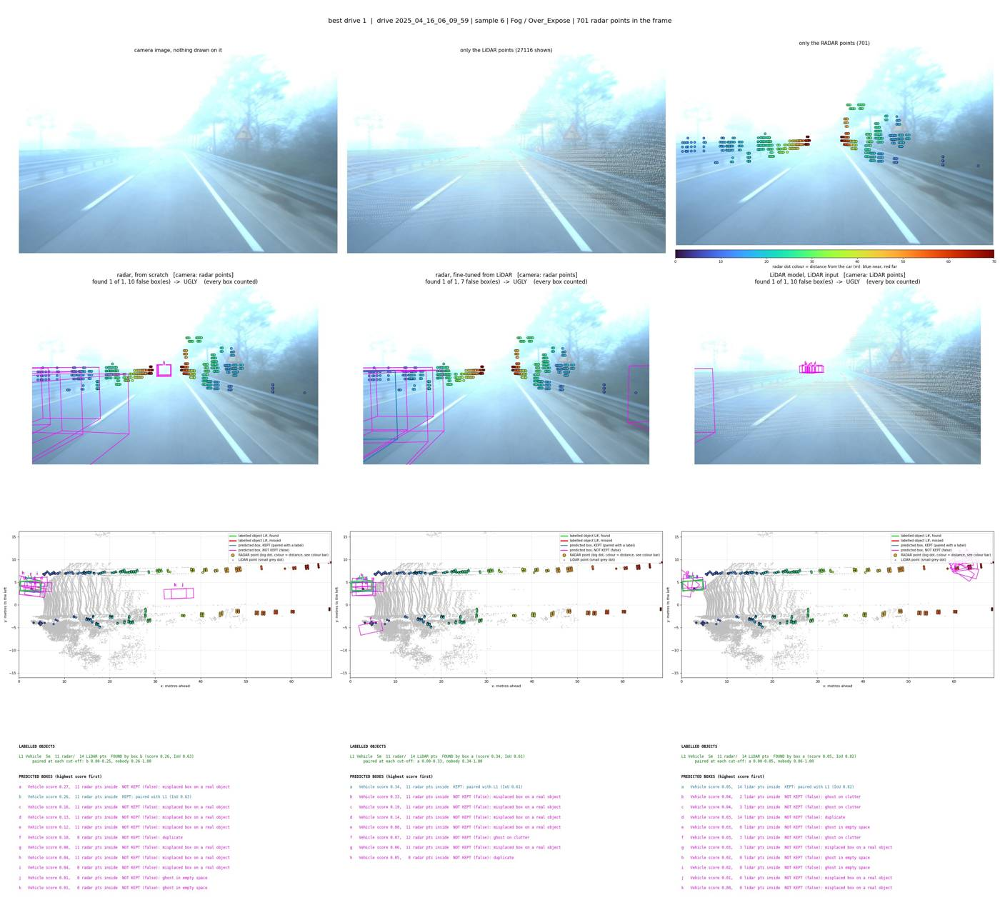

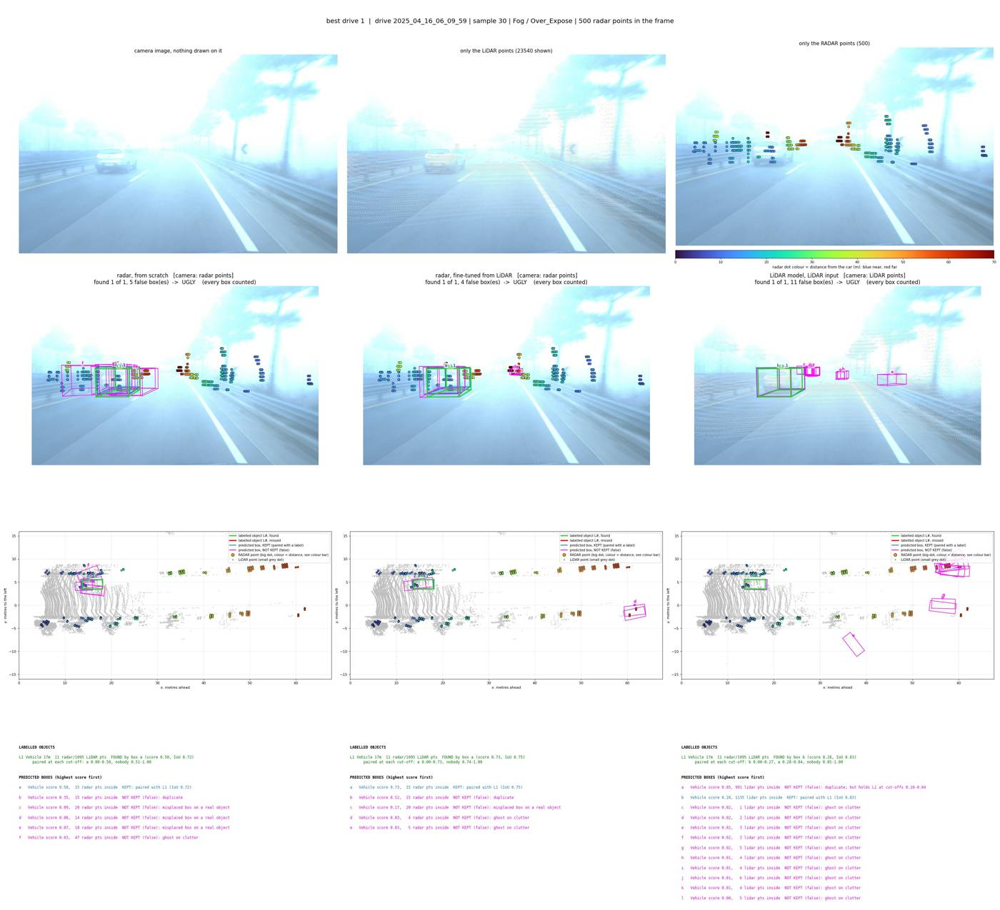

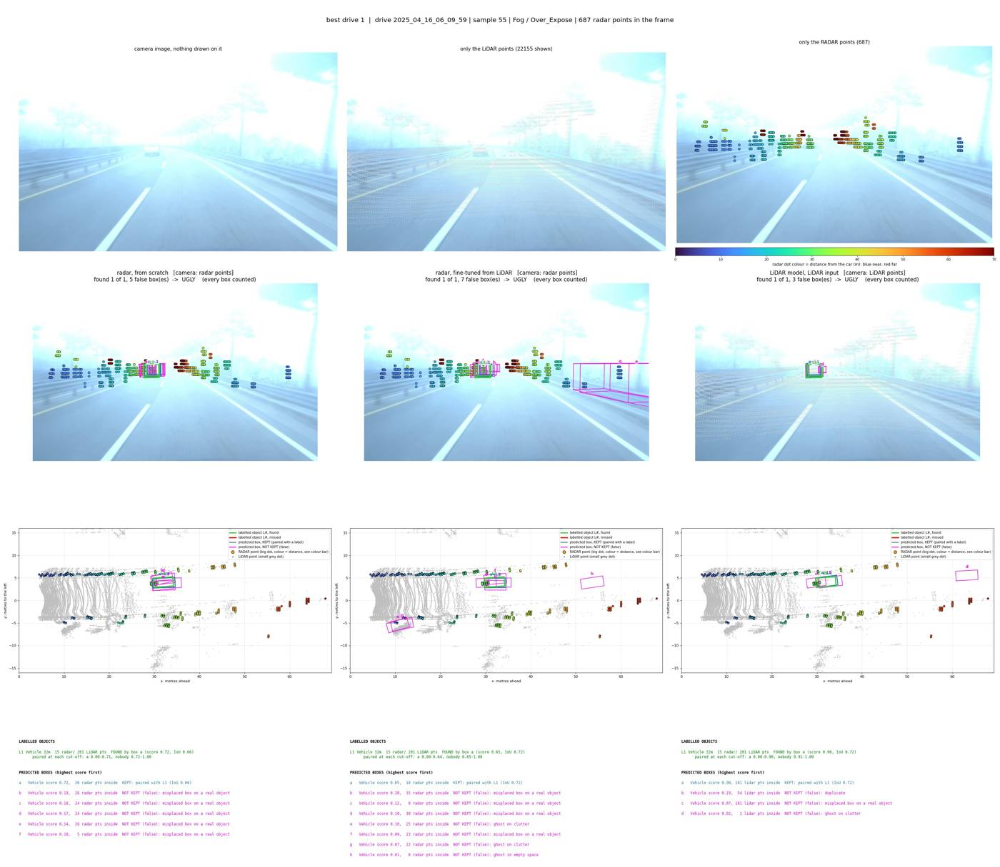

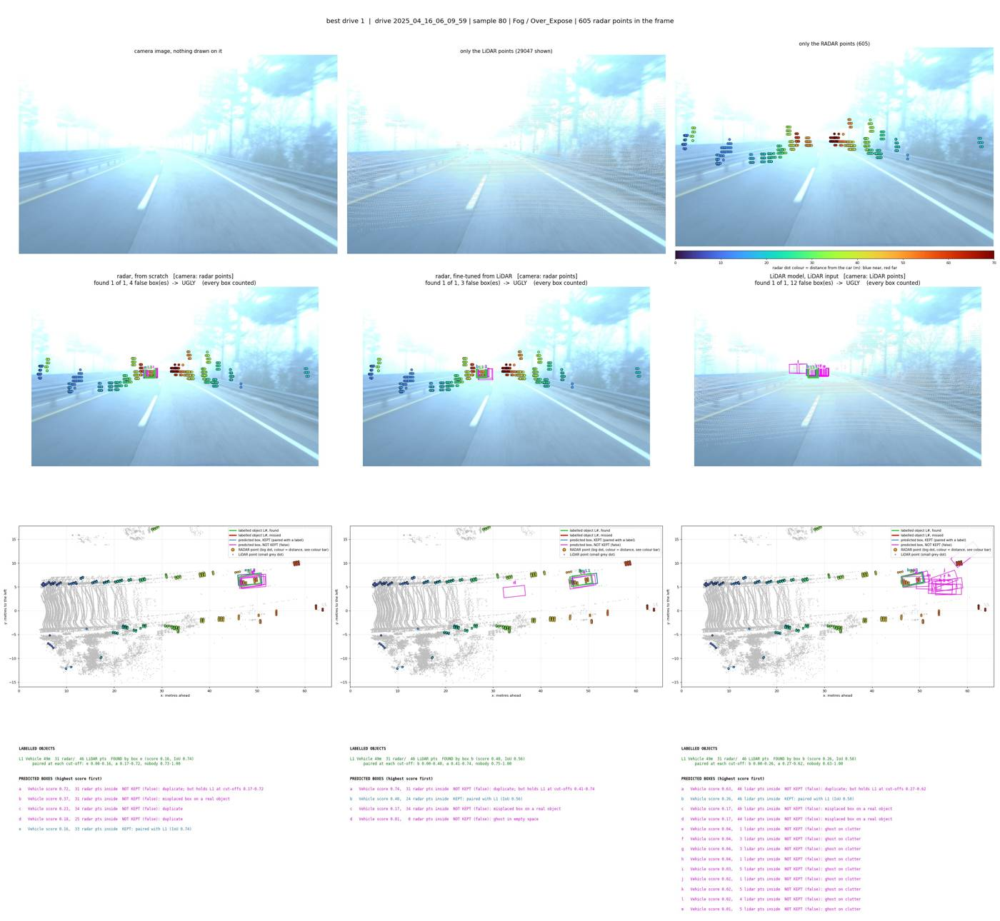


BEST 2: drive 2025_07_04_15_16_17 | Clear / HDR | 91 labelled vehicles, 0% standing | radar, from scratch AP 0.806, radar, fine-tuned from LiDAR AP 0.911, LiDAR model, LiDAR input AP 1.000


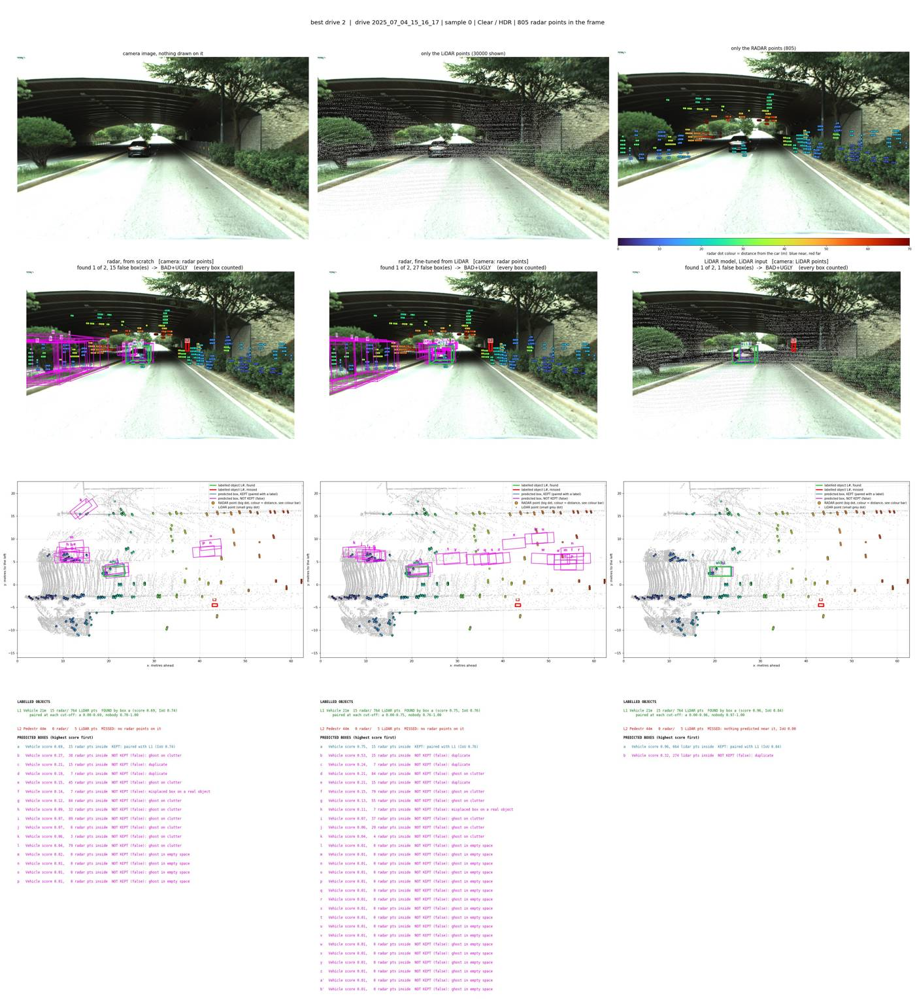

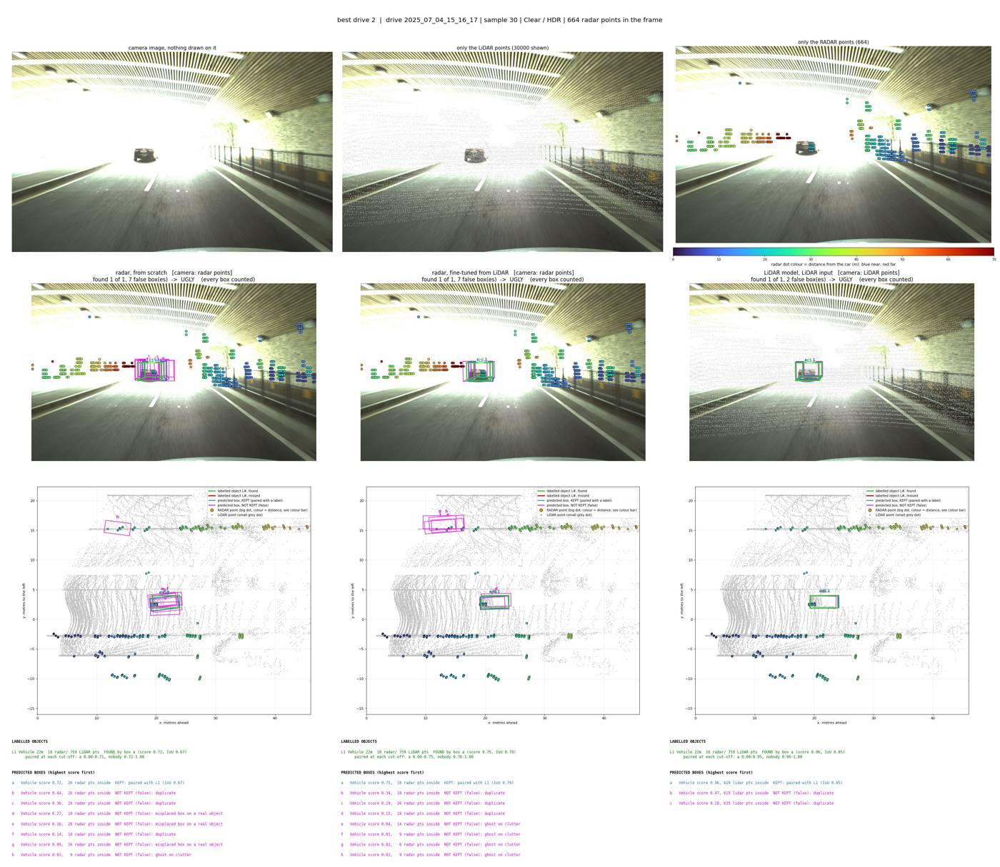

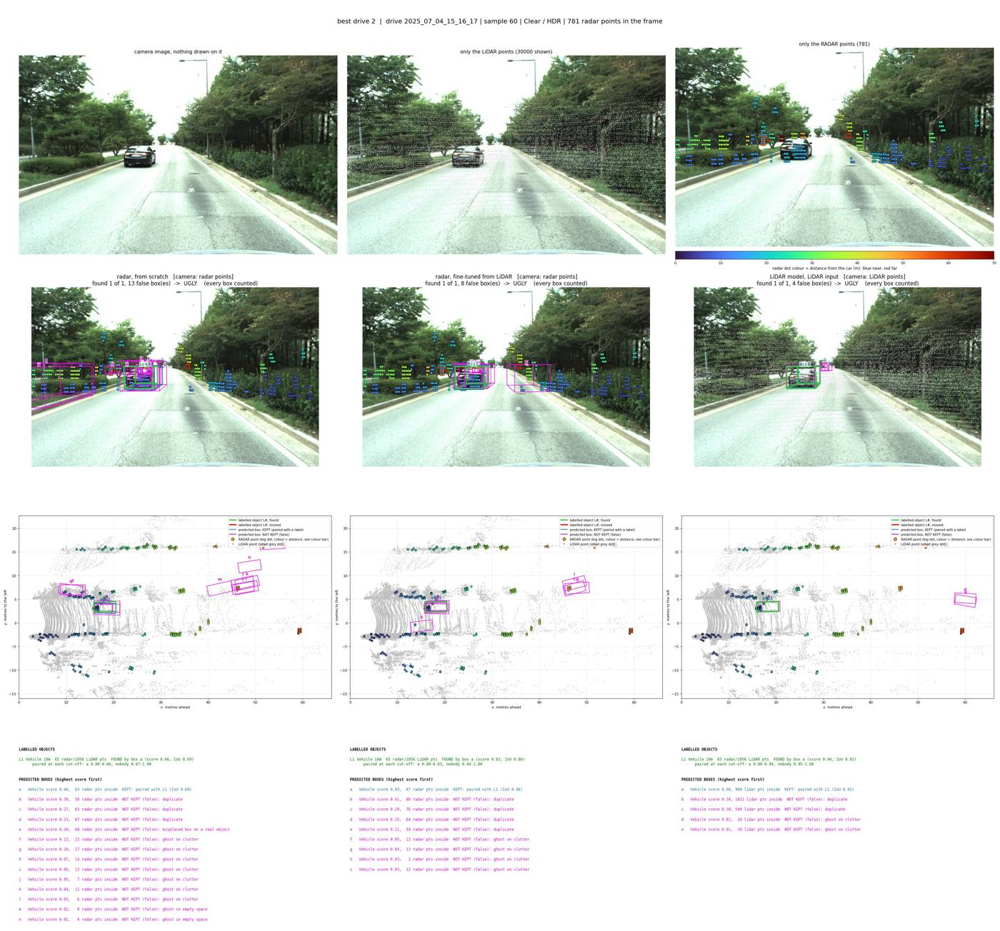

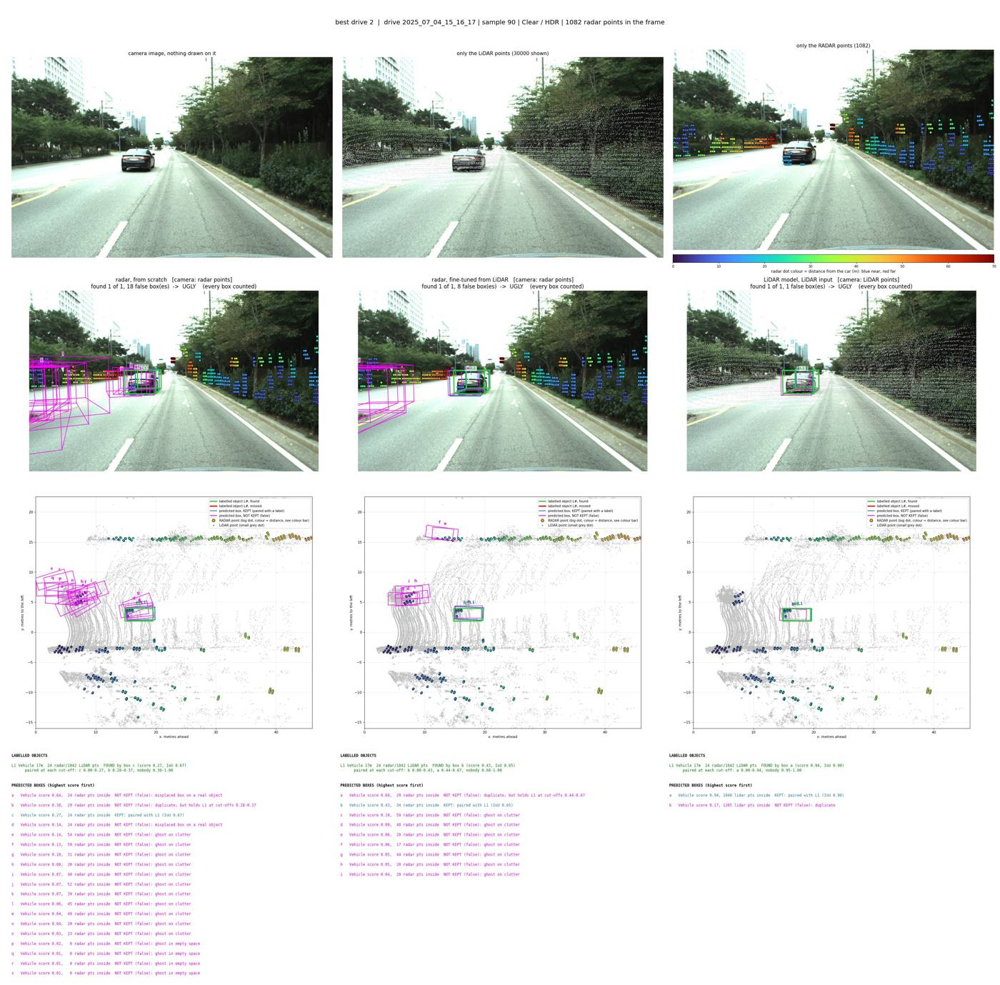


BEST 3: drive 2025_02_12_04_40_15 | Light_Snow / Low_Light | 167 labelled vehicles, 0% standing | radar, from scratch AP 0.727, radar, fine-tuned from LiDAR AP 0.837, LiDAR model, LiDAR input AP 0.968


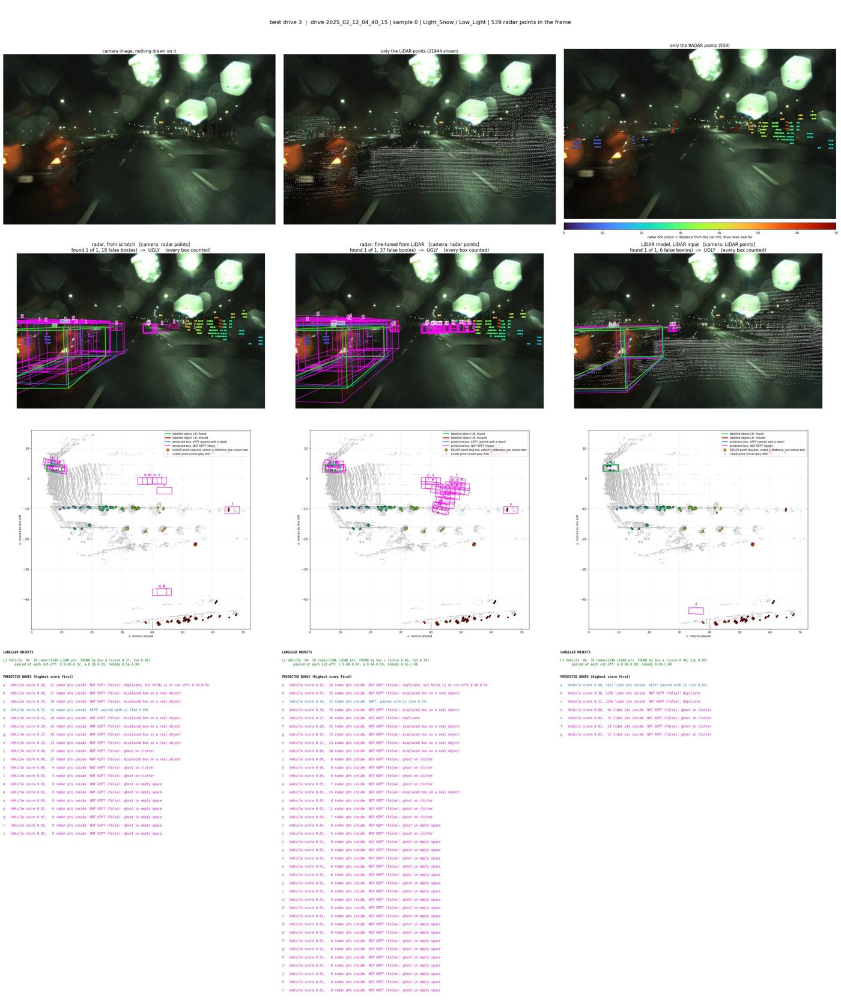

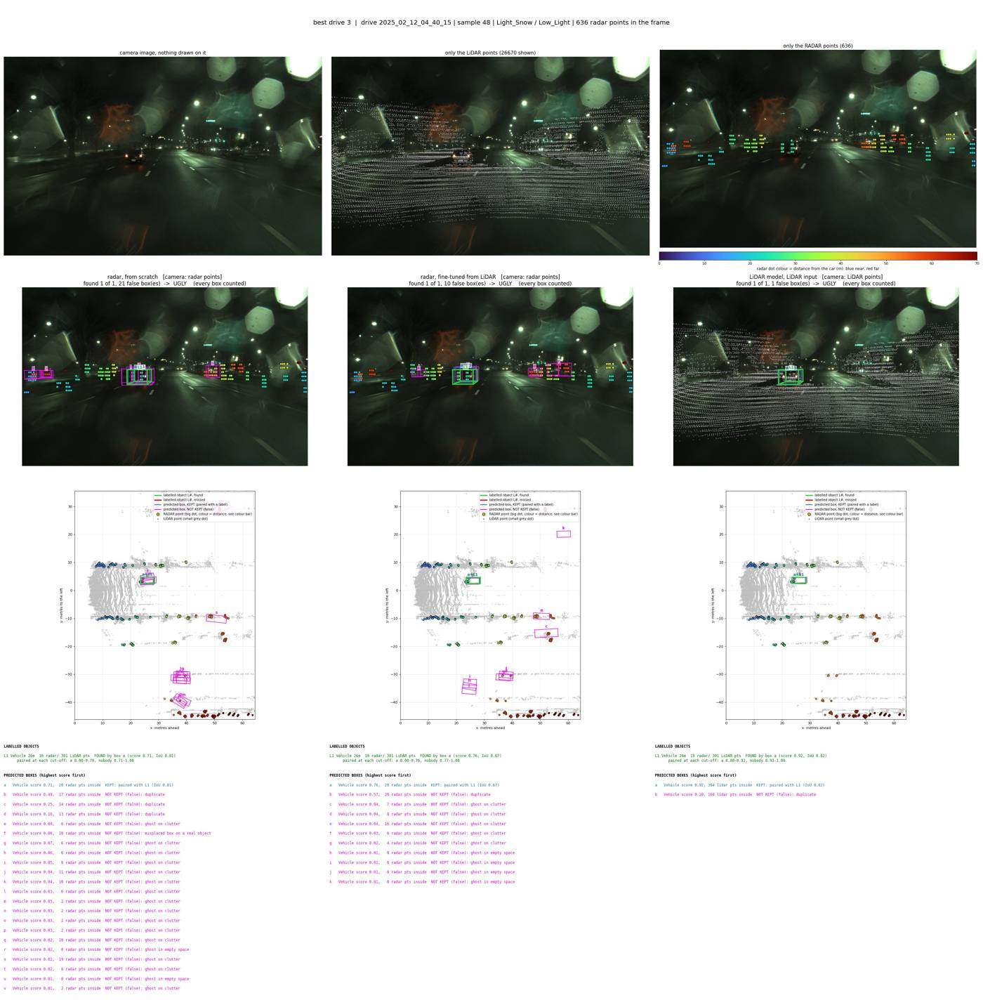

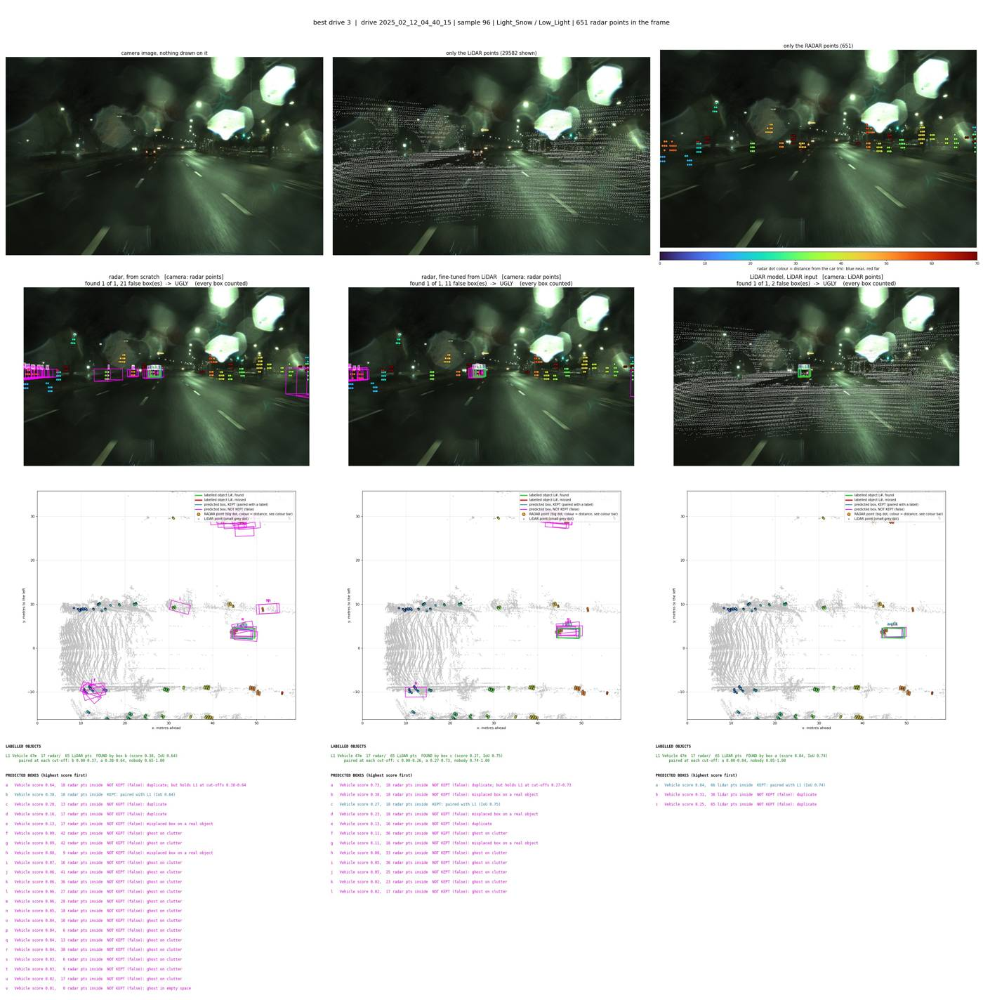

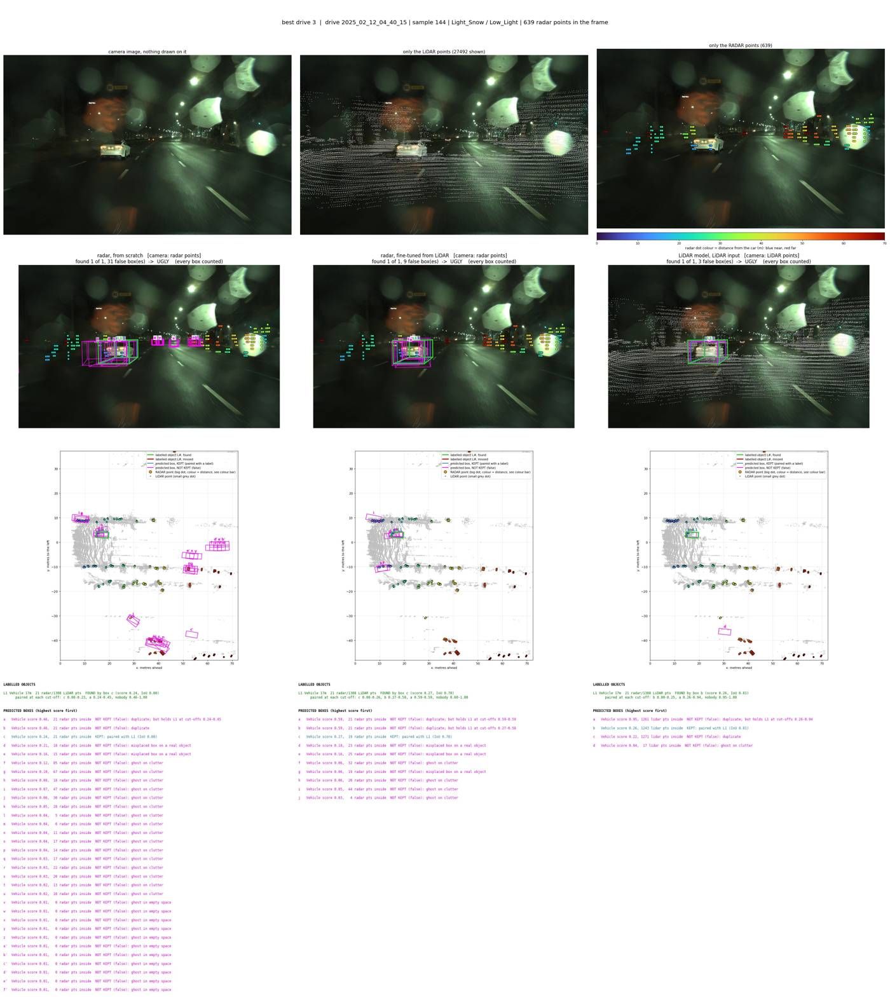

In [18]:
RANK_BY = "radar_ft_from_livox"        # the model whose Vehicle AP ranks the drives
N_DRIVES = 3                            # this many worst and this many best drives get pictures
N_FRAMES = 4                            # pictures per drive, spread evenly over the drive's frames with a labelled vehicle
MIN_LABELLED = 50                       # drives with fewer labelled vehicles are listed but get no pictures
DRIVE_MODELS = SPEED_MODELS             # models in the table and in the pictures

rows = {}
for d, x in FR.groupby("drive"):
    mask = (FR.drive == d).values
    v = V[V.drive == d]
    row = {"weather": x.weather.iloc[0], "light": x.light.iloc[0], "frames": len(x), "labelled vehicles": len(v),
           "standing": "%.0f%%" % (100 * (v.speed_group == 0).sum() / max((v.speed_group < 5).sum(), 1)),
           "no radar point": "%.0f%%" % (100 * (v.radar_pts == 0).mean()) if len(v) else "",
           "median distance (m)": round(v.dist.median()) if len(v) else np.nan}
    for m in DRIVE_MODELS:
        row["AP " + NAME.get(m, m)] = round(vehicle_ap(*AS_IS[m], mask), 3)
    rows[d] = row
DRIVES = pd.DataFrame.from_dict(rows, orient="index").sort_values("AP " + NAME.get(RANK_BY, RANK_BY))
print("Every validation drive, worst Vehicle AP of '%s' first (AP over the drive's frames, computed as in section 2)"
      % NAME.get(RANK_BY, RANK_BY))
with pd.option_context("display.max_rows", 200):
    display(DRIVES)

ranked = DRIVES[DRIVES["labelled vehicles"] >= MIN_LABELLED]
picks = [("worst", i + 1, d) for i, d in enumerate(ranked.index[:N_DRIVES])] + \
        [("best", i + 1, d) for i, d in enumerate(ranked.index[::-1][:N_DRIVES])]
for which, rank, d in picks:
    r = DRIVES.loc[d]
    print("\n%s %d: drive %s | %s / %s | %d labelled vehicles, %s standing | %s"
          % (which.upper(), rank, d, r.weather, r.light, r["labelled vehicles"], r.standing,
             ", ".join("%s AP %.3f" % (NAME.get(m, m), r["AP " + NAME.get(m, m)]) for m in DRIVE_MODELS)))
    ks = FR.index[(FR.drive == d).values & FR.has_image.values & (n_veh > 0)]
    for k in ([ks[int(i)] for i in np.linspace(0, len(ks) - 1, N_FRAMES)] if len(ks) > N_FRAMES else ks):
        show(int(k), models=DRIVE_MODELS, title="%s drive %d" % (which, rank),
             folder="6c_worst_and_best_drives/%s_%d_%s_%s" % (which, rank, r.weather, d))

## 6d. Frames by number of vehicles

How the models do on frames with 0, 1, 2, 3, 4 or more labelled vehicles: the GOOD / BAD / UGLY verdicts of section 5,
false vehicle boxes per frame, and the Vehicle AP over those frames.

In [19]:
# Frames sorted by how many labelled vehicles they hold. Verdicts are those of section 5 (all classes, every box
# counted): GOOD = nothing missed and no false box, BAD = something missed, UGLY = a false box, BAD+UGLY = both.
COUNT_SETS = {"0 vehicles": n_veh == 0, "1 vehicle": n_veh == 1, "2 vehicles": n_veh == 2, "3 vehicles": n_veh == 3,
              "4 or more": n_veh >= 4, "more than 2": n_veh > 2, "more than 3": n_veh > 3, "all frames": n_veh >= 0}
for m in SPEED_MODELS:
    s = S[S.model == m].set_index("k").verdict.reindex(range(N))
    false_veh = PRED[(PRED.model == m) & (PRED.cls == "Vehicle") & (PRED.status == "FP")].groupby("k").size() \
        .reindex(range(N), fill_value=0).values
    rows = {}
    for n, mask in COUNT_SETS.items():
        v = s[mask].value_counts()
        rows[n] = {"frames": int(mask.sum()), **{c: int(v.get(c, 0)) for c in ["GOOD", "BAD", "UGLY", "BAD+UGLY"]},
                   "labelled vehicles": int(n_veh[mask].sum()),
                   "false vehicle boxes per frame": round(false_veh[mask].mean(), 1),
                   "Vehicle AP": round(vehicle_ap(*AS_IS[m], mask), 4)}
    print("\n%s" % NAME.get(m, m))
    display(pd.DataFrame.from_dict(rows, orient="index"))


radar, from scratch


,frames,GOOD,BAD,UGLY,BAD+UGLY,labelled vehicles,false vehicle boxes per frame,Vehicle AP
0 vehicles,660,39,4,367,250,0,14.4,NaN
1 vehicle,2455,1,8,1436,1010,2455,17.9,0.3977
2 vehicles,1278,0,0,456,822,2556,23.5,0.3639
3 vehicles,812,0,0,130,682,2436,26.1,0.2668
4 or more,432,0,0,26,406,1856,33.4,0.2091
more than 2,1244,0,0,156,1088,4292,28.6,0.2429
more than 3,432,0,0,26,406,1856,33.4,0.2091
all frames,5637,40,12,2415,3170,9303,21.1,0.3170



radar, fine-tuned from LiDAR


,frames,GOOD,BAD,UGLY,BAD+UGLY,labelled vehicles,false vehicle boxes per frame,Vehicle AP
0 vehicles,660,47,7,368,238,0,11.4,NaN
1 vehicle,2455,2,4,1449,1000,2455,16.2,0.4335
2 vehicles,1278,0,4,468,806,2556,17.4,0.3969
3 vehicles,812,0,4,127,681,2436,19.9,0.3120
4 or more,432,0,0,29,403,1856,26.3,0.2587
more than 2,1244,0,4,156,1084,4292,22.1,0.2896
more than 3,432,0,0,29,403,1856,26.3,0.2587
all frames,5637,49,19,2441,3128,9303,17.2,0.3564



LiDAR model, LiDAR input


,frames,GOOD,BAD,UGLY,BAD+UGLY,labelled vehicles,false vehicle boxes per frame,Vehicle AP
0 vehicles,660,175,25,338,122,0,2.6,NaN
1 vehicle,2455,100,19,2089,247,2455,3.9,0.9179
2 vehicles,1278,5,1,1098,174,2556,5.9,0.8834
3 vehicles,812,2,0,651,159,2436,6.8,0.8775
4 or more,432,0,0,244,188,1856,8.0,0.7914
more than 2,1244,2,0,895,347,4292,7.2,0.8401
more than 3,432,0,0,244,188,1856,8.0,0.7914
all frames,5637,282,45,4420,890,9303,4.9,0.8719


### Crowded scenes: are the models confused when objects are close together?

Vehicle AP over frames with 1, 2, 3, 4+ labelled objects (any class) and the change against single-object frames;
the same for frames whose vehicles all move (so parked rows do not explain the drop); Vehicle AP of vehicles with
another object within `NEAR` m against vehicles alone; and per weather a crowded frame where predicted boxes sit
between two objects. Pictures: `pictures/6d_crowded/`.

1. Vehicle AP by the number of labelled objects in the frame: all frames with a vehicle


,frames,labelled vehicles,"AP radar, from scratch","change vs 1 object | radar, from scratch","AP radar, fine-tuned from LiDAR","change vs 1 object | radar, fine-tuned from LiDAR","AP LiDAR model, LiDAR input","change vs 1 object | LiDAR model, LiDAR input"
1 object,2065,2065,0.4311,0.0000,0.4720,0.0000,0.9150,0.0000
2 objects,1442,2630,0.3712,-0.0599,0.4033,-0.0687,0.8986,-0.0165
3 objects,841,2363,0.2545,-0.1765,0.2956,-0.1764,0.8701,-0.0449
4 or more objects,629,2245,0.2118,-0.2193,0.2588,-0.2132,0.8071,-0.1080


1. Vehicle AP by the number of labelled objects in the frame: frames whose vehicles all move


,frames,labelled vehicles,"AP radar, from scratch","change vs 1 object | radar, from scratch","AP radar, fine-tuned from LiDAR","change vs 1 object | radar, fine-tuned from LiDAR","AP LiDAR model, LiDAR input","change vs 1 object | LiDAR model, LiDAR input"
1 object,1821,1821,0.4829,0.0000,0.5234,0.0000,0.9274,0.0000
2 objects,1082,2020,0.4279,-0.0550,0.4628,-0.0606,0.8888,-0.0385
3 objects,472,1350,0.3283,-0.1546,0.3768,-0.1467,0.8905,-0.0368
4 or more objects,390,1523,0.2621,-0.2208,0.3263,-0.1971,0.8317,-0.0957



2. Vehicle AP of vehicles with and without another labelled object close by (all weathers)


,labelled vehicles,"AP radar, from scratch","AP radar, fine-tuned from LiDAR","AP LiDAR model, LiDAR input"
nothing within 6 m,8337,0.3317,0.3680,0.8749
another object within 6 m,966,0.1295,0.1857,0.8320
change (close by minus alone),<NA>,-0.2022,-0.1823,-0.0429



2. Vehicle AP of vehicles with and without another labelled object close by (all weathers)
   Check, as in 6b: without the boxes that overlap no labelled vehicle (they weigh more on the small group)


,labelled vehicles,"AP radar, from scratch","AP radar, fine-tuned from LiDAR","AP LiDAR model, LiDAR input"
nothing within 6 m,8337,0.3416,0.3772,0.8786
another object within 6 m,966,0.1864,0.2523,0.8481
change (close by minus alone),<NA>,-0.1552,-0.1249,-0.0305



3. Crowded frames (4+ labelled objects): 629; with a 'radar, fine-tuned from LiDAR' vehicle box touching two objects: 19 (3%)


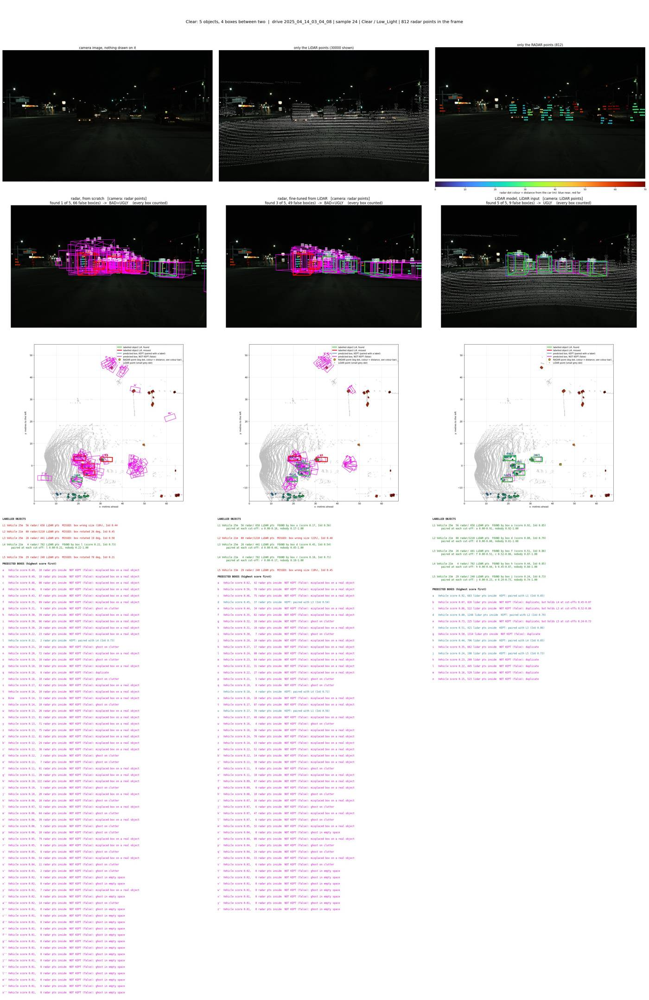

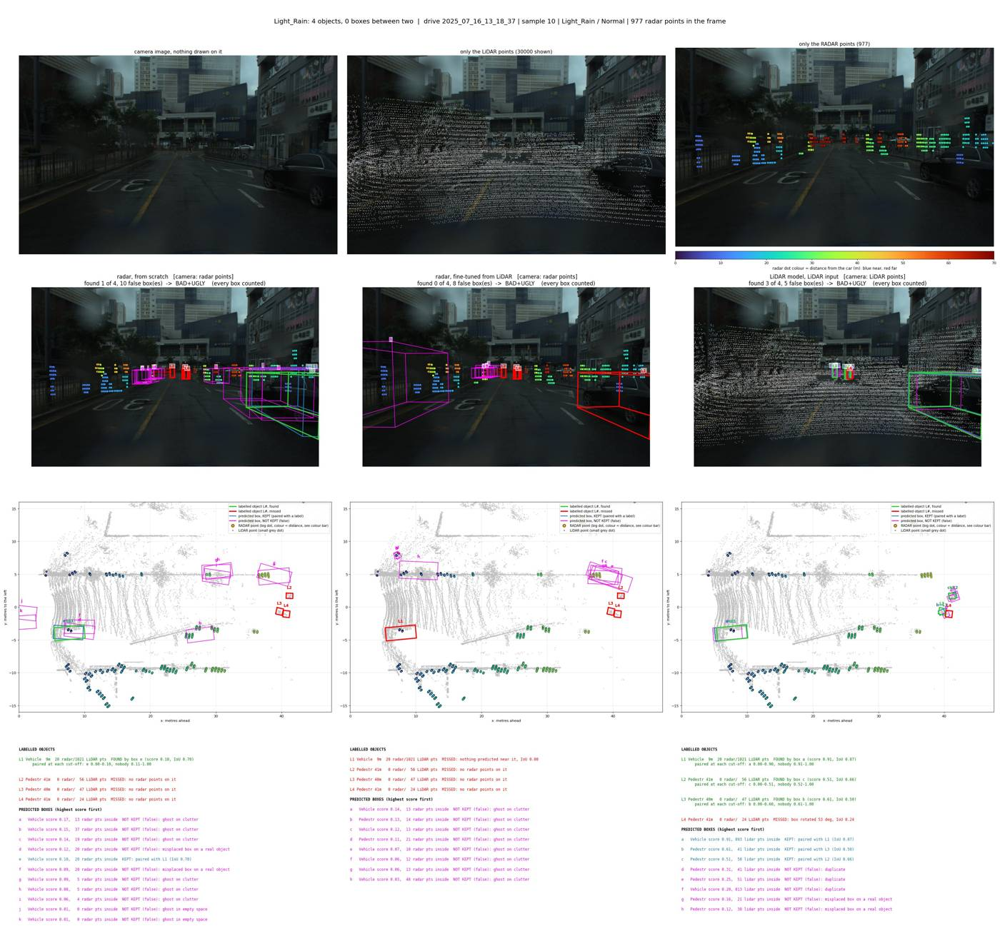

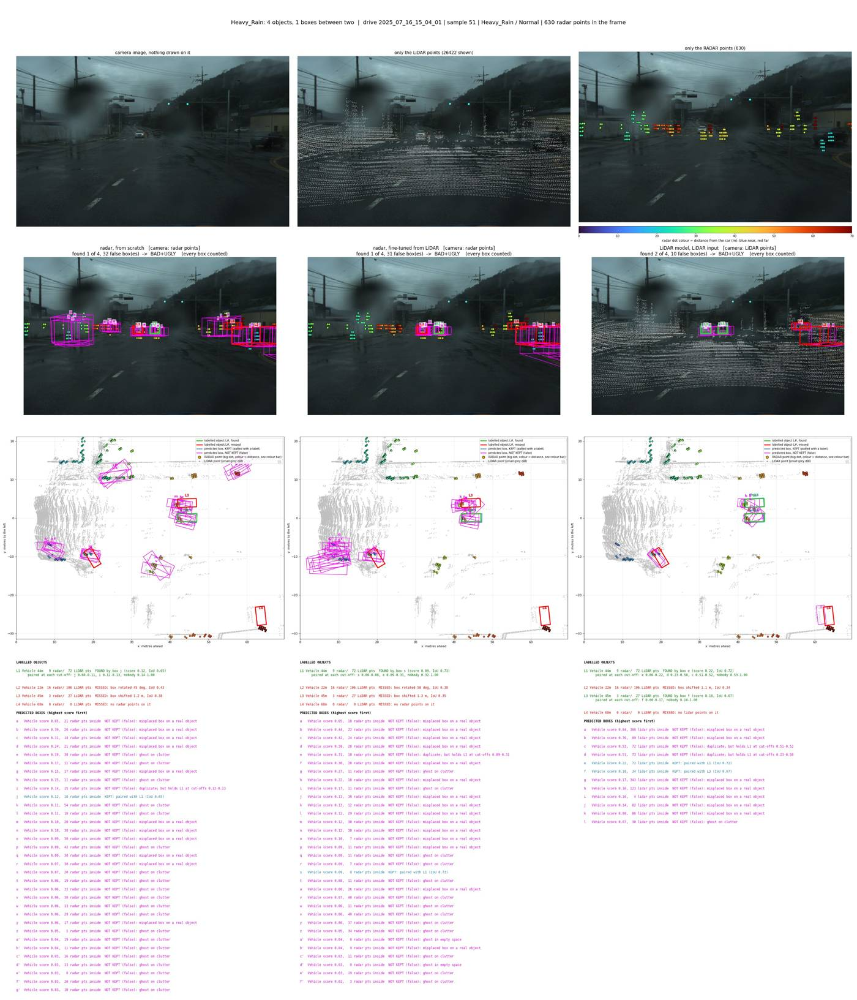

   Fog: no crowded frame with a camera image
   Light_Snow: no crowded frame with a camera image
   Heavy_Snow: no crowded frame with a camera image


In [20]:
# Crowded scenes: do the models get confused when objects are close together?
#  1. Vehicle AP over frames with 1, 2, 3, 4+ labelled objects of any class (vehicles, pedestrians, bikes), and the
#     change against frames with a single object. Crowded frames are often rows of parked cars (section 6b), so the
#     table is repeated for frames whose vehicles all move.
#  2. Vehicle AP of vehicles that have another labelled object close by (centres less than NEAR m apart, seen from
#     above) against vehicles with nothing close by, scored like Waymo's velocity breakdown (as in 6b).
#  3. Pictures: per weather, the crowded frame where the most predicted vehicle boxes touch two labelled objects at
#     once (3D IoU >= TOUCH with both), i.e. boxes that sit between objects; if there is none, the most crowded frame.
#     Saved in pictures/6d_crowded/.
NEAR = 6.0                  # m between centres: about one car length plus a gap
TOUCH = 0.1                 # IoU with a labelled object that counts as touching it
CROWDED = 4                 # frames with at least this many labelled objects are crowded
CROWD_MODEL = "radar_ft_from_livox"
N_EACH = 1                  # pictures per weather

n_obj = np.diff(F["gt_off"])                                            # labelled objects per frame, any class
OBJ_SETS = {"1 object": n_obj == 1, "2 objects": n_obj == 2, "3 objects": n_obj == 3,
            "%d or more objects" % CROWDED: n_obj >= CROWDED}
n_standing = V[V.speed_group == 0].groupby("k").size().reindex(range(N), fill_value=0).values
n_moving = V[V.speed_group.between(1, 4)].groupby("k").size().reindex(range(N), fill_value=0).values
for label, extra in [("all frames with a vehicle", n_veh > 0), ("frames whose vehicles all move", (n_standing == 0) & (n_moving > 0))]:
    rows = {}
    for name, mask in OBJ_SETS.items():
        mask = mask & extra
        rows[name] = {"frames": int(mask.sum()), "labelled vehicles": int(n_veh[mask].sum())}
        for m in SPEED_MODELS:
            ap = vehicle_ap(*AS_IS[m], mask)
            rows[name]["AP " + NAME.get(m, m)] = round(ap, 4)
            rows[name]["change vs 1 object | " + NAME.get(m, m)] = round(ap - vehicle_ap(*AS_IS[m], OBJ_SETS["1 object"] & extra), 4)
    print("1. Vehicle AP by the number of labelled objects in the frame: %s" % label)
    display(pd.DataFrame.from_dict(rows, orient="index"))

near = np.zeros(len(F["gt_box"]), int)                                 # 1 = another labelled object within NEAR m
for k in range(N):
    b = F["gt_box"][part("gt", k)].astype(float)
    if len(b) > 1:
        d = np.hypot(b[:, None, 0] - b[None, :, 0], b[:, None, 1] - b[None, :, 1])
        np.fill_diagonal(d, np.inf)
        near[F["gt_off"][k]:F["gt_off"][k + 1]] = (d.min(1) < NEAR).astype(int)
NEAR_SETS = {"nothing within %.0f m" % NEAR: [0], "another object within %.0f m" % NEAR: [1]}
for check in [False, True]:
    rows = {name: {"labelled vehicles": int(np.isin(near[F["gt_off"][V.k.values] + V.j.values], g).sum())}
            for name, g in NEAR_SETS.items()}
    for m in SPEED_MODELS:
        ap = group_ap(m, near, NEAR_SETS, without_boxes_on_nothing=check)
        for name in NEAR_SETS:
            rows[name]["AP " + NAME.get(m, m)] = round(ap[name, "all"], 4)
    T = pd.DataFrame.from_dict(rows, orient="index")
    T.loc["change (close by minus alone)"] = T.iloc[1] - T.iloc[0]
    T["labelled vehicles"] = T["labelled vehicles"].astype("Int64")
    T.loc["change (close by minus alone)", "labelled vehicles"] = pd.NA
    print("\n2. Vehicle AP of vehicles with and without another labelled object close by (all weathers)")
    if check:
        print("   Check, as in 6b: without the boxes that overlap no labelled vehicle (they weigh more on the small group)")
    display(T)

between = np.zeros(N, int)                                              # boxes touching two labelled objects
for k in range(N):
    s = part("pred_" + CROWD_MODEL, k)
    pb, pc = F["pred_%s_box" % CROWD_MODEL][s], F["pred_%s_cls" % CROWD_MODEL][s]
    I = IOU[CROWD_MODEL, k]
    if I.shape[1] > 1:
        inside = (pc == 1) & (np.hypot(pb[:, 0], pb[:, 1]) < MAX_DIST)
        between[k] = int(((I[inside] >= TOUCH).sum(1) >= 2).sum())
crowd = n_obj >= CROWDED
print("\n3. Crowded frames (%d+ labelled objects): %d; with a '%s' vehicle box touching two objects: %d (%.0f%%)"
      % (CROWDED, crowd.sum(), NAME.get(CROWD_MODEL, CROWD_MODEL), (crowd & (between > 0)).sum(),
         100 * (crowd & (between > 0)).sum() / max(crowd.sum(), 1)))
for w in WEATHERS:
    sel = crowd & (FR.weather == w).values & FR.has_image.values
    d = FR[sel].assign(between=between[sel], objects=n_obj[sel]).sort_values(["between", "objects"], ascending=False)
    if d.empty:
        print("   %s: no crowded frame with a camera image" % w)
    first = d.drop_duplicates("drive")
    for k in pd.concat([first, d.drop(first.index)]).index[:N_EACH]:
        show(int(k), models=SPEED_MODELS, title="%s: %d objects, %d boxes between two" % (w, n_obj[k], between[k]),
             folder="6d_crowded")

## 6e. What height errors cost

Every predicted vehicle box gets the height position and box height of the vehicle it overlaps most from above; the
rest of the box and its score stay. The difference in Vehicle AP is what wrong heights cost, overall and per Waymo
distance band. This uses the labels, so it is an upper limit, not a method. Run it for every new model.

In [21]:
# What the height errors cost in Vehicle AP: every predicted vehicle box gets the height position (z) and box height
# of the labelled vehicle it overlaps most seen from above; its x, y, length, width, heading and score stay. This uses
# the labels, so it is an upper limit that shows where AP is lost, not a method.
# Per distance: Waymo's range breakdown (0-30, 30-50, 50+ m from the sensor, 3D distance of the box centre;
# predicted and labelled boxes are each put in the band of their own distance).
RANGE_BANDS = {"0-30 m": (0, 30), "30-50 m": (30, 50), "50 m and more": (50, np.inf)}
OVERLAP = {}                                       # (model, frame) -> top-view overlap area, predicted x labelled
for m in SPEED_MODELS:
    for k in range(N):
        pi, pb, ps, gj, gb, gl = vehicle_boxes(m, k)
        OVERLAP[m, k] = top_view_overlap(pb, gb)

def height_variant(m, fix, band=None):
    def get(k):
        pi, pb, ps, gj, gb, gl = vehicle_boxes(m, k)
        A = OVERLAP[m, k]
        if fix and len(pi) and len(gj):
            top = A / np.maximum((pb[:, 3] * pb[:, 4])[:, None] + (gb[:, 3] * gb[:, 4])[None] - A, 1e-9)
            has = top.max(1) > 0
            pb = pb.copy()
            pb[has, 2], pb[has, 5] = gb[top[has].argmax(1), 2], gb[top[has].argmax(1), 5]
        iou = iou3d_from_overlap(A, pb, gb) if len(pi) and len(gj) else np.zeros((len(pi), len(gj)))
        if band is None:
            return ps, iou, gl
        lo, hi = band
        dp, dg = np.linalg.norm(pb[:, :3], axis=1), np.linalg.norm(gb[:, :3], axis=1)
        p_in, g_in = (dp >= lo) & (dp < hi), (dg >= lo) & (dg < hi)
        return ps[p_in], iou[np.ix_(p_in, g_in)], gl[g_in]
    return get

rows = {}
for m in SPEED_MODELS:
    for fix in [False, True]:
        row = {"all": vehicle_ap(*tp_fp_custom(height_variant(m, fix)))}
        if not fix:
            assert abs(row["all"] - AP[m, "Vehicle", "all"]) < 1e-4       # IoU from the overlap = the evaluation's IoU
        row.update({b: vehicle_ap(*tp_fp_custom(height_variant(m, fix, lim))) for b, lim in RANGE_BANDS.items()})
        rows[NAME.get(m, m), "height from the label" if fix else "as is"] = row
T = pd.DataFrame.from_dict(rows, orient="index")
for m in SPEED_MODELS:
    T.loc[(NAME.get(m, m), "gain"), :] = T.loc[(NAME.get(m, m), "height from the label")] - T.loc[(NAME.get(m, m), "as is")]
T = T.loc[[(NAME.get(m, m), v) for m in SPEED_MODELS for v in ["as is", "height from the label", "gain"]]]
print("Vehicle AP, all distances and per Waymo distance band")
display(T.round(4))

Vehicle AP, all distances and per Waymo distance band


all  0-30 m  30-50 m  50 m and more
radar, from scratch          as is                  0.3170  0.4014   0.3307         0.1229
                             height from the label  0.4693  0.4833   0.5233         0.3494
                             gain                   0.1523  0.0820   0.1926         0.2265
radar, fine-tuned from LiDAR as is                  0.3564  0.4555   0.3593         0.1356
                             height from the label  0.5088  0.5334   0.5690         0.3569
                             gain                   0.1524  0.0779   0.2097         0.2213
LiDAR model, LiDAR input     as is                  0.8719  0.9348   0.8954         0.6769
                             height from the label  0.8934  0.9420   0.9099         0.7389
                             gain                   0.0215  0.0072   0.0146         0.0620

## 6f. Does the model trust its best box?

Each predicted vehicle box is put on the labelled vehicle it overlaps most. Per vehicle: how many boxes, whether the
box with the highest score is a good one (IoU >= 0.5), whether it is the best-fitting one, and how far apart the
boxes are. The score of these models is the square root of (first-stage heat-map score x second-stage predicted IoU),
so a perfect model would score the best-fitting box highest.

The last table bins vehicles by how far apart their boxes are: if the score is a usable confidence, it drops where the
boxes disagree.

In [22]:
from scipy.stats import spearmanr
# Every predicted vehicle box is put on the labelled vehicle it overlaps most (3D IoU >= ON_CAR); then, per labelled
# vehicle: how many boxes, the top-scored one, the best-fitting one, and how much the boxes disagree.
ON_CAR = 0.1
rows = []
for m in SPEED_MODELS:
    for k in np.flatnonzero(n_veh > 0):
        pi, pb, ps, gj, gb, gl = vehicle_boxes(m, k)
        if not len(pi):
            for q in np.flatnonzero(gl == 1):
                rows.append((m, k, gj[q], 0) + (np.nan,) * 8)
            continue
        sub = IOU[m, k][np.ix_(pi, gj)]
        owner = np.where(sub.max(1) >= ON_CAR, sub.argmax(1), -1)
        for q in np.flatnonzero(gl == 1):
            on = np.flatnonzero(owner == q)
            if not len(on):
                rows.append((m, k, gj[q], 0) + (np.nan,) * 8)
                continue
            iou, sc = sub[on, q], ps[on]
            top, best = on[sc.argmax()], on[iou.argmax()]
            rho = spearmanr(sc, iou)[0] if len(on) >= 3 and np.ptp(sc) > 0 and np.ptp(iou) > 0 else np.nan
            rows.append((m, k, gj[q], len(on), sub[top, q], iou.max(), ps[top], float(top == best), rho,
                         np.sqrt(pb[on, 0].var() + pb[on, 1].var()) if len(on) > 1 else np.nan,
                         pb[on, 2].std() if len(on) > 1 else np.nan, np.hypot(gb[q, 0], gb[q, 1])))
R = pd.DataFrame(rows, columns=["model", "k", "j", "boxes", "top_iou", "best_iou", "top_score", "top_is_best", "rank_corr",
                                "spread_xy", "spread_z", "dist"])
R = R.merge(FR[["weather", "drive", "sample"]], left_on="k", right_index=True)
R["good_exists"] = R.best_iou >= IOU_THR["Vehicle"]
R["top_good"] = R.top_iou >= IOU_THR["Vehicle"]
R["ranking_error"] = R.good_exists & ~R.top_good          # a good box exists, but the model trusts another one more

def ranking_table(r):
    on = r[r.boxes > 0]; g = on[on.good_exists]
    return {"labelled vehicles": len(r), "with a box on them": len(on), "boxes per vehicle (mean)": round(on.boxes.mean(), 1),
            "with a good box (IoU >= 0.5)": len(g),
            "top-scored box is good (of those)": "%.0f%%" % (100 * g.top_good.mean()),
            "top-scored box fits best (2+ boxes)": "%.0f%%" % (100 * on[on.boxes > 1].top_is_best.mean()),
            "IoU of top-scored box (median)": round(on.top_iou.median(), 2),
            "IoU of best-fitting box (median)": round(on.best_iou.median(), 2),
            "score follows IoU on one vehicle (rank corr., 3+ boxes)": round(on.rank_corr.mean(), 2),
            "spread of the box centres on one vehicle (median, m)": round(on.spread_xy.median(), 2),
            "spread of the box heights z (median, m)": round(on.spread_z.median(), 2)}
print("How each model ranks the boxes it puts on one labelled vehicle (all weathers)")
display(pd.DataFrame({NAME.get(m, m): ranking_table(R[R.model == m]) for m in SPEED_MODELS}))

for col, label in [("top_good", "top-scored box is good, of the vehicles that have a good box"),
                   ("rank_corr", "score follows IoU on one vehicle (mean rank correlation, 3+ boxes)"),
                   ("spread_z", "spread of the box heights z on one vehicle (median, m)")]:
    r = R[R.good_exists] if col == "top_good" else R[R.boxes > 0]
    t = r.groupby(["weather", "model"])[col].agg("mean" if col != "spread_z" else "median").unstack()
    print("\nPer weather: " + label)
    display(t.reindex(WEATHERS)[SPEED_MODELS].rename(columns=NAME).round(2))

rows = {}
for w in WEATHERS:
    rows[w] = {"frames with a labelled vehicle": int(((FR.weather == w).values & (n_veh > 0)).sum())}
    for m in SPEED_MODELS:
        e = R[(R.model == m) & (R.weather == w)].groupby("k").ranking_error.any()
        rows[w]["with a ranking error | " + NAME.get(m, m)] = "%d (%.0f%%)" % (e.sum(), 100 * e.mean())
print("\nFrames where some vehicle has a good box but the model scored a worse box on it higher")
display(pd.DataFrame(rows).T)

# Is the disagreement between a vehicle's boxes a usable warning? Vehicles binned by how far apart their boxes are.
r = R[(R.boxes > 1)].copy()
r["spread"] = pd.cut(r.spread_xy, [0, 0.2, 0.5, 1.0, 100], right=False, labels=["< 0.2 m", "0.2-0.5 m", "0.5-1 m", ">= 1 m"])
t = r.groupby(["spread", "model"], observed=False).agg(vehicles=("j", "size"), good=("good_exists", "mean"),
                                                       top_good=("top_good", "mean"), top_score=("top_score", "median"))
print("\nVehicles with 2+ boxes, by how far apart the box centres are: share with a good box, share whose top-scored box\n"
      "is good, median score of the top box. If the score were a good confidence, it would drop where the boxes disagree.")
display(t.unstack("model").swaplevel(axis=1)[SPEED_MODELS].rename(columns=NAME, level=0).round(2))

How each model ranks the boxes it puts on one labelled vehicle (all weathers)


,"radar, from scratch","radar, fine-tuned from LiDAR","LiDAR model, LiDAR input"
labelled vehicles,9303,9303,9303
with a box on them,7851,7593,9018
boxes per vehicle (mean),5.5,5.1,2.8
with a good box (IoU >= 0.5),5324,5409,8678
top-scored box is good (of those),77%,80%,98%
top-scored box fits best (2+ boxes),47%,47%,66%
IoU of top-scored box (median),0.51,0.53,0.77
IoU of best-fitting box (median),0.58,0.6,0.78
"score follows IoU on one vehicle (rank corr., 3+ boxes)",0.56,0.56,0.55
"spread of the box centres on one vehicle (median, m)",0.78,0.73,0.31



Per weather: top-scored box is good, of the vehicles that have a good box


model,"radar, from scratch","radar, fine-tuned from LiDAR","LiDAR model, LiDAR input"
weather,,,
Clear,0.76,0.78,0.98
Light_Rain,0.83,0.87,0.99
Heavy_Rain,0.76,0.81,0.96
Fog,0.75,0.79,0.93
Light_Snow,0.81,0.84,0.98
Heavy_Snow,0.76,0.82,0.97



Per weather: score follows IoU on one vehicle (mean rank correlation, 3+ boxes)


model,"radar, from scratch","radar, fine-tuned from LiDAR","LiDAR model, LiDAR input"
weather,,,
Clear,0.54,0.55,0.56
Light_Rain,0.58,0.53,0.68
Heavy_Rain,0.59,0.60,0.54
Fog,0.61,0.60,0.54
Light_Snow,0.51,0.49,0.46
Heavy_Snow,0.58,0.59,0.40


... (2 outputs left out)


Frames where some vehicle has a good box but the model scored a worse box on it higher


,frames with a labelled vehicle,"with a ranking error | radar, from scratch","with a ranking error | radar, fine-tuned from LiDAR","with a ranking error | LiDAR model, LiDAR input"
Clear,3004,663 (22%),612 (20%),107 (4%)
Light_Rain,383,80 (21%),70 (18%),4 (1%)
Heavy_Rain,496,134 (27%),113 (23%),30 (6%)
Fog,481,109 (23%),96 (20%),34 (7%)
Light_Snow,390,56 (14%),49 (13%),11 (3%)
Heavy_Snow,223,48 (22%),36 (16%),9 (4%)



Vehicles with 2+ boxes, by how far apart the box centres are: share with a good box, share whose top-scored box
is good, median score of the top box. If the score were a good confidence, it would drop where the boxes disagree.


model     radar, from scratch                          radar, fine-tuned from LiDAR                          LiDAR model, LiDAR input                         
                     vehicles  good top_good top_score                     vehicles  good top_good top_score                 vehicles  good top_good top_score
spread                                                                                                                                                        
< 0.2 m                   286  0.82     0.76      0.64                          471  0.88     0.83      0.68                     2316  0.98     0.98      0.90
0.2-0.5 m                 990  0.71     0.61      0.56                         1434  0.78     0.69      0.65                     3333  0.97     0.95      0.87
0.5-1 m                  3897  0.71     0.57      0.52                         3184  0.71     0.58      0.52                     1780  0.94     0.90      0.80
>= 1 m                   2378  0.66     0.42      0.35                         2249  0.69     0.46      0.41                      531  0.93     0.85      0.73

### The same as a picture (saved as `pictures/6f_ranking/overview.jpg`)

Left two panels: for boxes in each score range, their mean IoU and the share that are good. A model that ranks well
has a steep curve. Then: boxes per vehicle, and per weather the share of vehicles whose top-scored box is good.

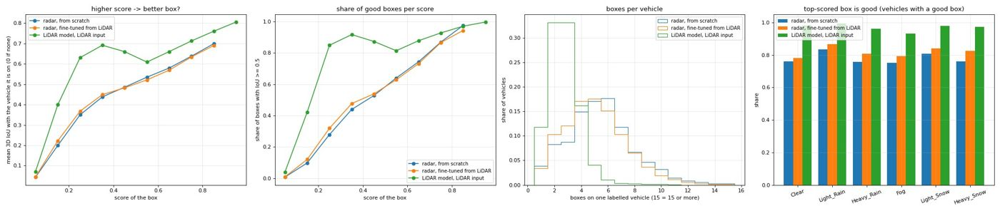

saved /kaggle/working/pictures/6f_ranking/overview.jpg


In [23]:
# The same as pictures: does a higher score mean a better box?  Saved as pictures/6f_ranking/overview.jpg
BOX = {m: [] for m in SPEED_MODELS}
for m in SPEED_MODELS:
    for k in range(N):
        pi, pb, ps, gj, gb, gl = vehicle_boxes(m, k)
        if len(pi):
            BOX[m].append(np.c_[ps, IOU[m, k][np.ix_(pi, gj)].max(1) if len(gj) else np.zeros(len(pi))])
    BOX[m] = np.concatenate(BOX[m])
bins = np.linspace(0, 1, 11)
fig, ax = plt.subplots(1, 4, figsize=(26, 5.5))
for m in SPEED_MODELS:
    s, iou = BOX[m][:, 0], BOX[m][:, 1]
    b = np.clip(np.digitize(s, bins) - 1, 0, 9)
    mid = (bins[:-1] + bins[1:]) / 2
    has = np.bincount(b, minlength=10) > 20
    ax[0].plot(mid[has], [iou[b == i].mean() for i in range(10) if has[i]], "o-", label=NAME.get(m, m))
    ax[1].plot(mid[has], [(iou[b == i] >= 0.5).mean() for i in range(10) if has[i]], "o-", label=NAME.get(m, m))
    ax[2].hist(R[(R.model == m) & (R.boxes > 0)].boxes.clip(upper=15), bins=np.arange(1, 17) - 0.5, histtype="step", lw=2,
               density=True, label=NAME.get(m, m))
x = np.arange(len(WEATHERS))
for i, m in enumerate(SPEED_MODELS):
    v = R[(R.model == m) & R.good_exists].groupby("weather").top_good.mean().reindex(WEATHERS)
    ax[3].bar(x + (i - 1) * 0.27, v.values, 0.27, label=NAME.get(m, m))
ax[0].set(xlabel="score of the box", ylabel="mean 3D IoU with the vehicle it is on (0 if none)", title="higher score -> better box?")
ax[1].set(xlabel="score of the box", ylabel="share of boxes with IoU >= 0.5", title="share of good boxes per score")
ax[2].set(xlabel="boxes on one labelled vehicle (15 = 15 or more)", ylabel="share of vehicles", title="boxes per vehicle")
ax[3].set(xticks=x, ylabel="share", title="top-scored box is good (vehicles with a good box)", ylim=(0, 1.05))
ax[3].set_xticklabels(WEATHERS, rotation=20)
for a in ax:
    a.grid(alpha=0.3); a.legend(fontsize=9)
plt.tight_layout()
os.makedirs(os.path.join(PIC_DIR, "6f_ranking"), exist_ok=True)
path = os.path.join(PIC_DIR, "6f_ranking", "overview.jpg")
fig.savefig(path, dpi=SAVE_DPI, pil_kwargs={"quality": 88})
plt.close(fig)
im = Image.open(path); im = im.resize((SHOW_WIDTH, round(im.size[1] * SHOW_WIDTH / im.size[0])))
buf = io.BytesIO(); im.save(buf, "JPEG", quality=80); display(ShowImage(data=buf.getvalue(), format="jpeg"))
print("saved", path)

### What ranking and duplicates cost in Vehicle AP

The boxes stay where they are; only which box gets which score, or which boxes stay, changes. These use the labels, so
they are upper limits that show where the AP is lost:
- **scores re-ordered on each vehicle**: perfect ranking among the boxes on one vehicle;
- **one box per vehicle, the top-scored**: duplicates removed, the model's own choice kept;
- **one box per vehicle, the best-fitting**: both.

In [24]:
# What ranking and duplicates cost in Vehicle AP. Every change below uses the labels, so these are upper limits that
# show where AP is lost, not methods. The boxes themselves never move; boxes on no vehicle always stay as they are.
#  * "scores re-ordered on each vehicle": the boxes on one vehicle swap scores so that the best-fitting box gets the
#    highest of their scores, the second best the second highest, and so on (perfect ranking on each vehicle).
#  * "one box per vehicle, the top-scored": only the box the model scored highest stays on each vehicle (no duplicates).
#  * "one box per vehicle, the best-fitting": only the best-fitting box stays, with the vehicle's highest score (both).
def per_vehicle(m, how):
    def get(k):
        pi, pb, ps, gj, gb, gl = vehicle_boxes(m, k)
        sub = IOU[m, k][np.ix_(pi, gj)]
        if not len(pi) or not len(gj):
            return ps, sub, gl
        owner = np.where(sub.max(1) >= ON_CAR, sub.argmax(1), -1)
        ps, keep = ps.copy(), owner < 0
        for q in np.unique(owner[owner >= 0]):
            on = np.flatnonzero(owner == q)
            by_iou = on[np.argsort(-sub[on, q], kind="stable")]
            if how == "re-order":
                ps[by_iou] = np.sort(ps[on])[::-1]
                keep[on] = True
            elif how == "top-scored":
                keep[on[ps[on].argmax()]] = True
            else:
                ps[by_iou[0]] = ps[on].max()
                keep[by_iou[0]] = True
        return ps[keep], sub[keep], gl
    return get

VARIANTS = {}
for m in SPEED_MODELS:
    VARIANTS[m] = {"as is": AS_IS[m],
                   "scores re-ordered on each vehicle": tp_fp_custom(per_vehicle(m, "re-order")),
                   "one box per vehicle, the top-scored": tp_fp_custom(per_vehicle(m, "top-scored")),
                   "one box per vehicle, the best-fitting": tp_fp_custom(per_vehicle(m, "best-fitting"))}
rows = {}
for m in SPEED_MODELS:
    for v, res in VARIANTS[m].items():
        rows[NAME.get(m, m), v] = {g: round(vehicle_ap(*res, mask), 4) for g, mask in WEATHER_MASKS.items()}
print("Vehicle AP, all frames and per weather")
display(pd.DataFrame.from_dict(rows, orient="index"))

Vehicle AP, all frames and per weather


all   Clear  Light_Rain  Heavy_Rain     Fog  Light_Snow  Heavy_Snow
radar, from scratch          as is                                  0.3170  0.2898      0.5001      0.3139  0.4442      0.3460      0.1922
                             scores re-ordered on each vehicle      0.3694  0.3368      0.5409      0.3980  0.5222      0.4037      0.2132
                             one box per vehicle, the top-scored    0.3225  0.2916      0.5507      0.3068  0.4382      0.3534      0.2212
                             one box per vehicle, the best-fitting  0.4541  0.4123      0.6789      0.4907  0.6383      0.4675      0.2847
radar, fine-tuned from LiDAR as is                                  0.3564  0.3181      0.5343      0.3616  0.5240      0.3960      0.3232
                             scores re-ordered on each vehicle      0.4069  0.3676      0.5741      0.4204  0.6014      0.4397      0.3543
                             one box per vehicle, the top-scored    0.3581  0.3138      0.5574      0.3663  0.5312      0.4000      0.3712
                             one box per vehicle, the best-fitting  0.4781  0.4278      0.6650      0.5101  0.7165      0.4943      0.4632
LiDAR model, LiDAR input     as is                                  0.8719  0.9034      0.9584      0.7576  0.7188      0.8766      0.7131
                             scores re-ordered on each vehicle      0.8803  0.9106      0.9590      0.7772  0.7263      0.8883      0.7146
                             one box per vehicle, the top-scored    0.8923  0.9226      0.9816      0.7500  0.7644      0.9056      0.7721
                             one box per vehicle, the best-fitting  0.9165  0.9442      0.9861      0.7874  0.8115      0.9284      0.7868

### Pictures of ranking errors

Per weather, a frame where the model scored a worse box higher than a good one on the same vehicle. In the object list
the boxes are named a, b, c ... from the highest score down, with their IoU. Pictures: `pictures/6f_ranking_errors/`.

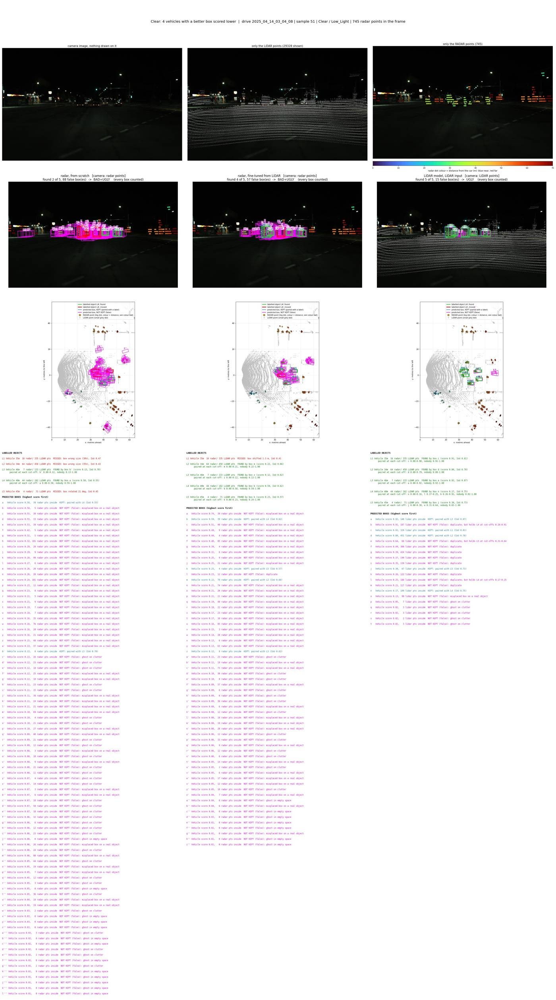

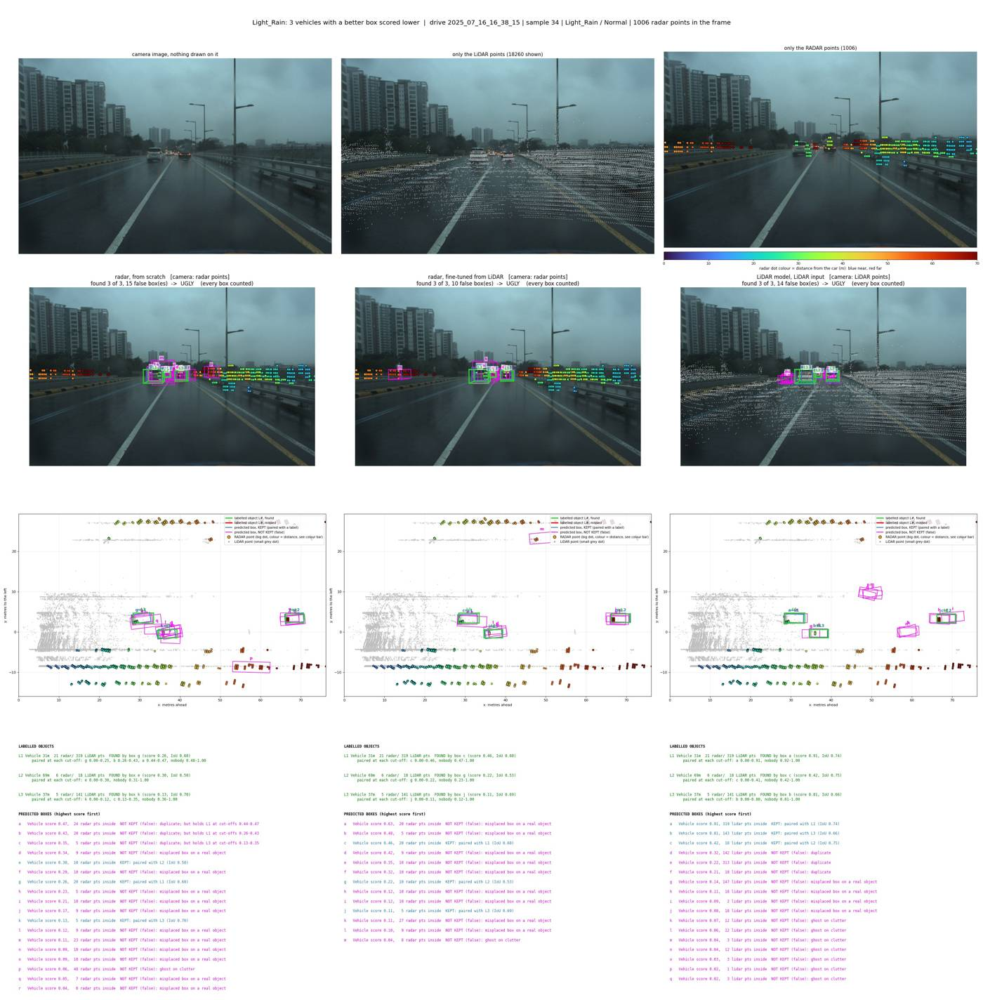

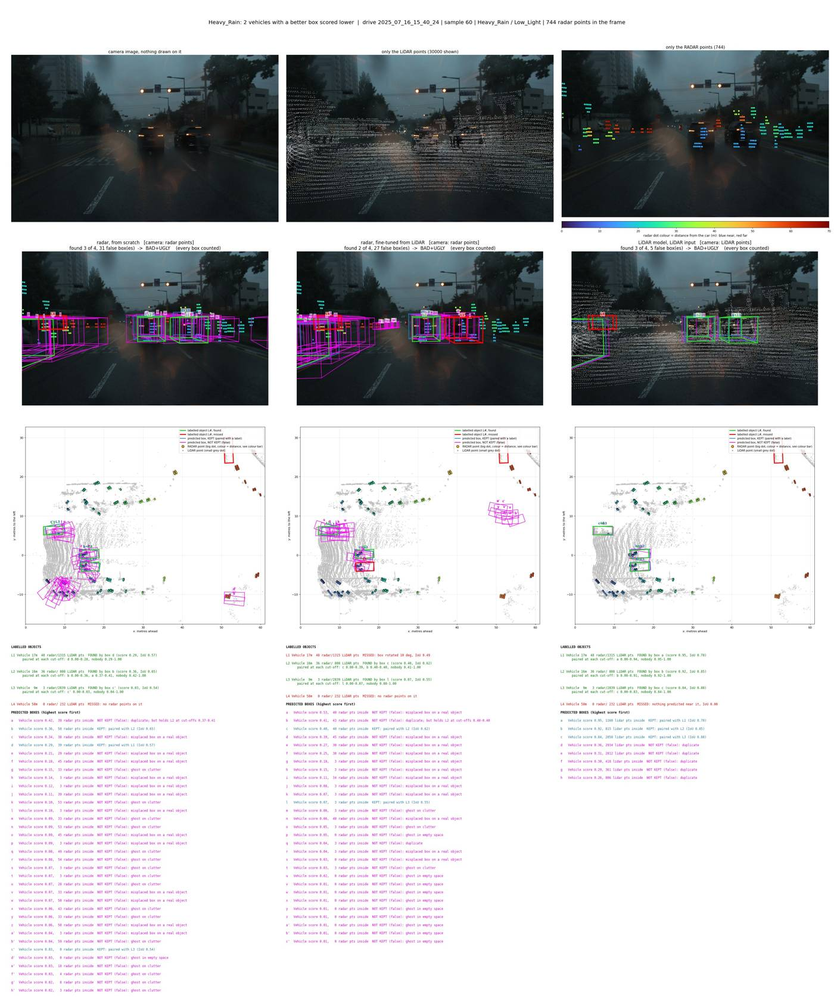

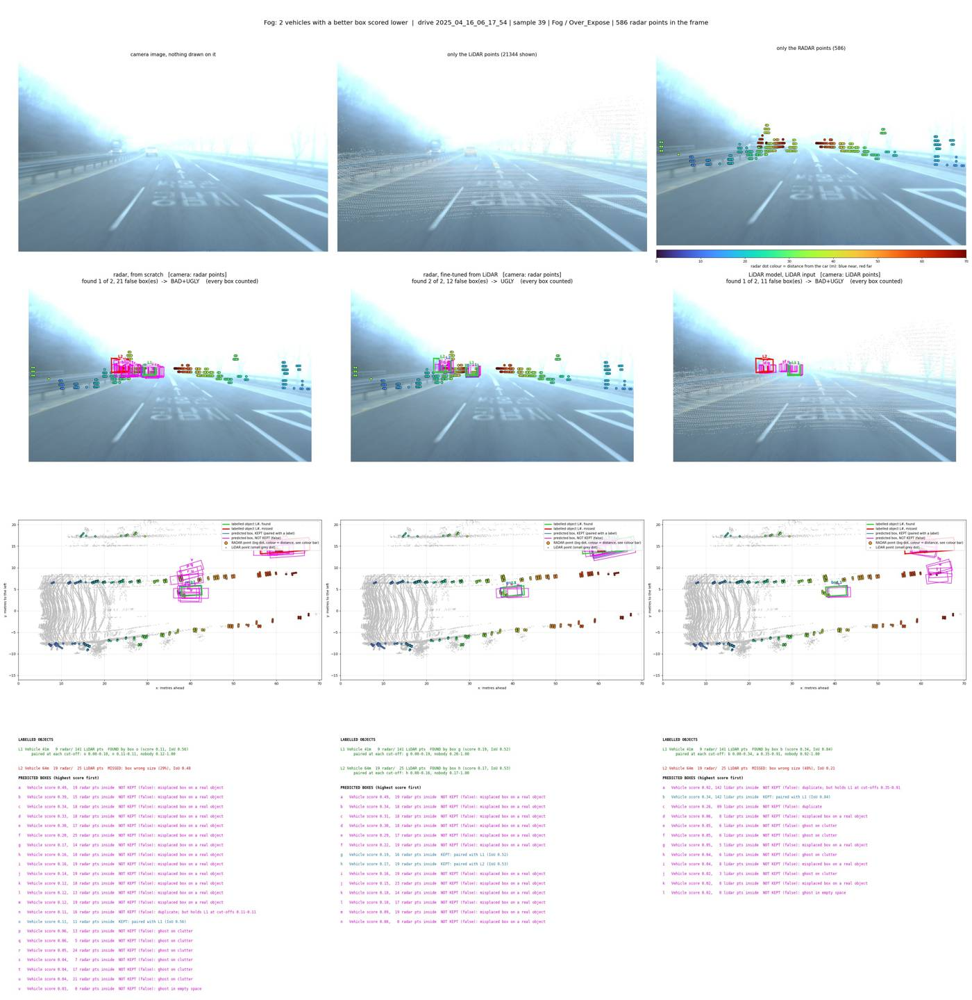

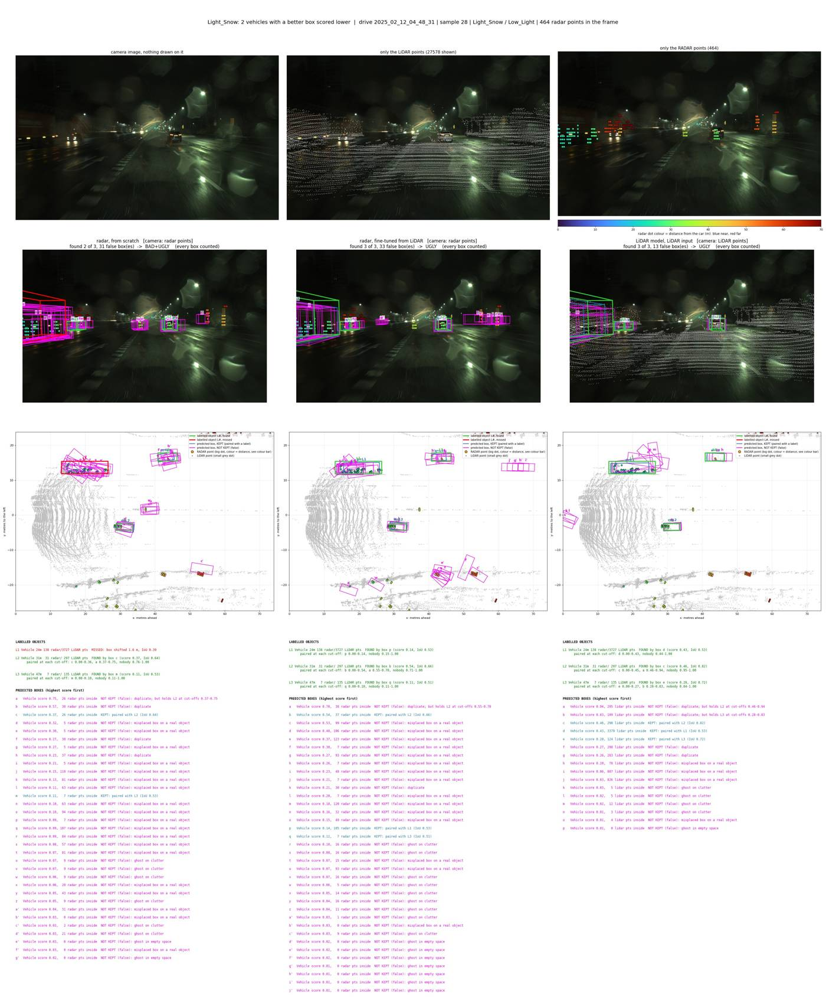

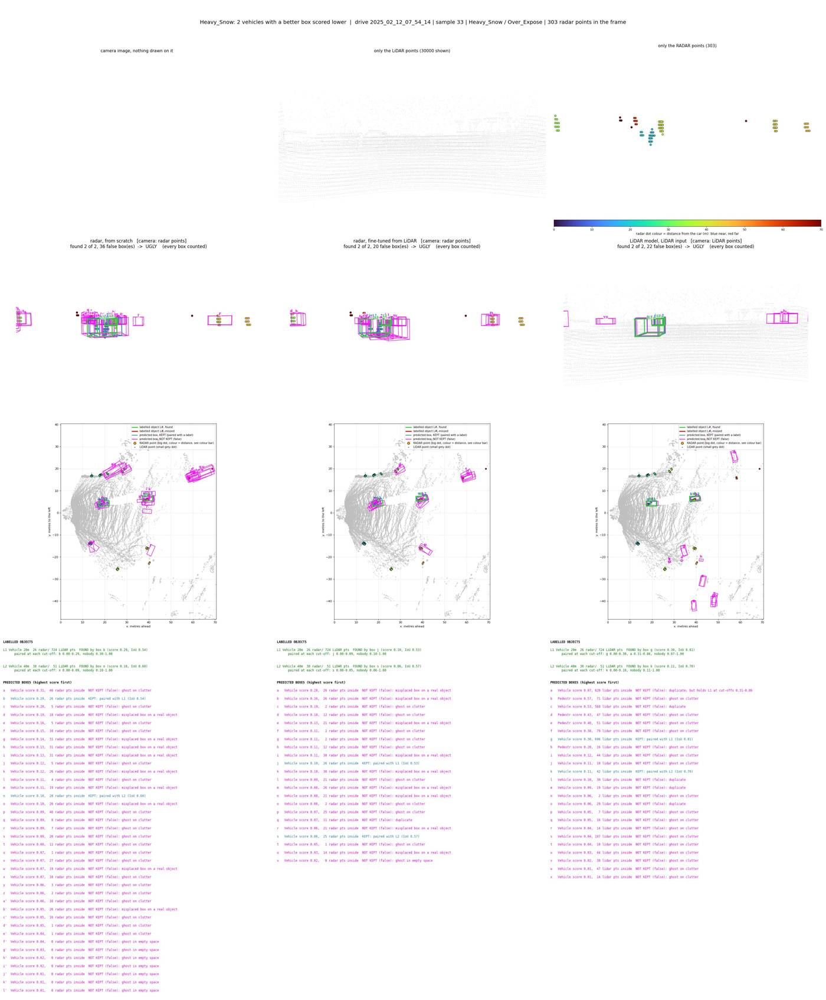

In [25]:
# Pictures of ranking errors: per weather, the frames where RANKING_MODEL has the most vehicles with a good box that
# it scored lower than a worse box on the same vehicle (one frame per drive first). In the object list under each
# picture the boxes are named a, b, c ... from the highest score down, with their IoU.
RANKING_MODEL = "radar_ft_from_livox"
N_EACH = 1
e = R[(R.model == RANKING_MODEL)].groupby("k").ranking_error.sum()
for w in WEATHERS:
    d = FR.loc[e.index].assign(errors=e.values)
    d = d[(d.weather == w) & d.has_image & (d.errors > 0)].sort_values("errors", ascending=False)
    first = d.drop_duplicates("drive")
    for k in pd.concat([first, d.drop(first.index)]).index[:N_EACH]:
        show(int(k), models=SPEED_MODELS, title="%s: %d vehicles with a better box scored lower" % (w, e[k]),
             folder="6f_ranking_errors")

## 6g. Removing duplicate boxes after the model (no retraining)

The authors' post-processing removes no duplicate vehicle boxes after the second stage, so several refined boxes can
sit on one vehicle. Here an extra NMS step runs on the saved boxes (`NMS 0.5`, `NMS 0.3`), and one variant merges each
kept box with the boxes it removed. This changes the model's output, not the evaluation. The thresholds were chosen
on the validation set, so confirm any choice on other data before reporting it as a result. Takes about 8 minutes.

In [26]:
# Post-processing on the saved boxes, without retraining. The authors' code (CenterPointPC.post_processing in
# centerpoint_waymo.py) runs no NMS on vehicle boxes after the second stage: the proposals are de-duplicated at 0.7
# before refinement, and refined boxes that move onto the same vehicle all stay. Variants:
#  * "NMS t": per frame, go down the vehicle boxes by score and drop every box whose top-view IoU with an already kept
#    box is above t.
#  * "NMS t + merge": the same, but each kept box becomes the score-weighted mean (x, y, z, length, width, height) of
#    itself and the boxes it removed; heading and score stay those of the kept box.
# This changes the model's output; the evaluation stays the official one. The thresholds were chosen by looking at
# validation results, so a threshold picked here has to be confirmed on other data before it is reported as a result.
NMS_THRESHOLDS = [0.5, 0.3]
MERGE_AT = 0.5

PAIR_IOU = {}                          # (model, frame) -> top-view IoU between the model's vehicle boxes, computed once

def pair_iou(m, k, pb):
    if (m, k) not in PAIR_IOU:
        M = np.zeros((len(pb), len(pb)))
        r = np.hypot(pb[:, 3], pb[:, 4]) / 2
        close = np.hypot(pb[:, None, 0] - pb[None, :, 0], pb[:, None, 1] - pb[None, :, 1]) <= r[:, None] + r[None]
        a = pb[:, 3] * pb[:, 4]
        for i, j in zip(*np.nonzero(np.triu(close, 1))):
            inter = area(clip_polygon(bev_corners(pb[i]), bev_corners(pb[j])))
            M[i, j] = M[j, i] = inter / max(a[i] + a[j] - inter, 1e-9)
        PAIR_IOU[m, k] = M
    return PAIR_IOU[m, k]

def nms_groups(M, ps, thr):
    "Kept boxes (by score) and, for each, the boxes it removed (itself included). M = top-view IoU between the boxes."
    groups = {}
    for i in np.argsort(-ps, kind="stable"):
        over = [j for j in groups if M[i, j] > thr]
        if over:
            groups[over[0]].append(i)          # the highest-scored kept box it overlaps
        else:
            groups[i] = [i]
    return groups

def post_variant(m, thr, merge):
    def get(k):
        pi, pb, ps, gj, gb, gl = vehicle_boxes(m, k)
        groups = nms_groups(pair_iou(m, k, pb), ps, thr)
        keep = np.array(list(groups), int)
        if not merge:
            return ps[keep], IOU[m, k][np.ix_(pi[keep], gj)], gl
        nb = pb[keep].copy()
        for n, i in enumerate(keep):
            g = groups[i]
            nb[n, :6] = np.average(pb[g, :6], axis=0, weights=ps[g])
        return ps[keep], iou3d_from_overlap(top_view_overlap(nb, gb), nb, gb) if len(gj) else np.zeros((len(keep), 0)), gl
    return get

rows = {}
for m in SPEED_MODELS:
    variants = {"as saved": AS_IS[m]}
    for t in NMS_THRESHOLDS:
        variants["NMS %.1f" % t] = tp_fp_custom(post_variant(m, t, False))
    variants["NMS %.1f + merge" % MERGE_AT] = tp_fp_custom(post_variant(m, MERGE_AT, True))
    for v, res in variants.items():
        rows[NAME.get(m, m), v] = {g: round(vehicle_ap(*res, mask), 4) for g, mask in WEATHER_MASKS.items()}
        rows[NAME.get(m, m), v]["vehicle boxes per frame"] = round((res[0][:, 0] + res[1][:, 0]).mean(), 1)
print("Vehicle AP, all frames and per weather")
display(pd.DataFrame.from_dict(rows, orient="index"))

Vehicle AP, all frames and per weather


all   Clear  Light_Rain  Heavy_Rain     Fog  Light_Snow  Heavy_Snow  vehicle boxes per frame
radar, from scratch          as saved         0.3170  0.2898      0.5001      0.3139  0.4442      0.3460      0.1922                     22.1
                             NMS 0.5          0.3434  0.3132      0.5740      0.3277  0.4646      0.3675      0.2314                     15.3
                             NMS 0.3          0.3319  0.3017      0.5587      0.3133  0.4465      0.3582      0.2282                      9.7
                             NMS 0.5 + merge  0.3468  0.3112      0.5861      0.3449  0.4763      0.3732      0.2497                     15.3
radar, fine-tuned from LiDAR as saved         0.3564  0.3181      0.5343      0.3616  0.5240      0.3960      0.3232                     18.2
                             NMS 0.5          0.3779  0.3346      0.5765      0.3807  0.5580      0.4082      0.3831                     12.0
                             NMS 0.3          0.3663  0.3223      0.5638      0.3689  0.5370      0.4061      0.3839                      7.8
                             NMS 0.5 + merge  0.3746  0.3267      0.5868      0.3904  0.5609      0.4040      0.3849                     12.0
LiDAR model, LiDAR input     as saved         0.8719  0.9034      0.9584      0.7576  0.7188      0.8766      0.7131                      6.5
                             NMS 0.5          0.8961  0.9256      0.9829      0.7502  0.7751      0.9079      0.7835                      3.4
                             NMS 0.3          0.8953  0.9249      0.9835      0.7508  0.7711      0.9088      0.7828                      2.8
                             NMS 0.5 + merge  0.8979  0.9319      0.9796      0.7478  0.7616      0.9020      0.7673                      3.4

## 7. Look at anything you want

Set `WEATHER`, `DRIVE`, `SAMPLES` (or `FRAMES`), optionally `MISSED_BY` / `NO_RADAR_BOX`, and run the cell: it draws the
matching frames (at most `N_MAX`) for the models in `MODELS_SHOWN`.

**Every picture in this notebook is also saved** as a `.jpg` in the output folder under `pictures/` (one sub-folder per
section: `4_frames`, `5_good_bad_ugly`, `6_pretraining_difference`, `6b_clear_standing_vs_moving`,
`6b_standing_missed`, `6c_worst_and_best_drives/<worst or best>_<n>_<weather>_<drive>`, `6d_crowded`, `6f_ranking`, `6f_ranking_errors`, `7_my_picks`,
`drive_<name>`), and this cell ends by
packing them all into **`pictures.zip`**. On Kaggle: Output tab (or the folder icon on the right) -> `pictures.zip` ->
download. `save_drive(drive)` saves one picture per frame of a whole drive without showing them.

drives matching: {('Clear', '2025_04_01_15_47_26'): 101, ('Clear', '2025_04_01_16_03_50'): 76, ('Clear', '2025_04_01_16_11_05'): 88, ('Clear', '2025_04_01_16_13_05'): 96, ('Clear', '2025_04_01_16_15_57'): 124, ('Clear', '2025_04_01_16_20_38'): 104, ('Clear', '2025_04_14_03_02_53'): 121, ('Clear', '2025_04_14_03_04_08'): 108, ('Clear', '2025_04_14_03_15_38'): 118, ('Clear', '2025_04_14_03_56_32'): 148, ('Clear', '2025_04_14_04_08_56'): 148, ('Clear', '2025_04_15_08_11_34'): 100, ('Clear', '2025_04_15_08_25_27'): 100, ('Clear', '2025_06_22_01_05_57'): 78, ('Clear', '2025_06_27_02_20_51'): 148, ('Clear', '2025_06_27_02_28_58'): 128, ('Clear', '2025_06_27_02_37_51'): 148, ('Clear', '2025_07_04_15_16_17'): 91, ('Clear', '2025_07_04_15_41_51'): 98, ('Clear', '2025_07_04_15_55_05'): 88, ('Clear', '2025_07_04_15_59_01'): 60, ('Clear', '2025_07_04_16_00_23'): 81, ('Clear', '2025_07_04_16_10_52'): 121, ('Clear', '2025_07_04_17_10_48'): 98, ('Clear', '2025_07_04_17_14_22'): 98, ('Clear', '2025_07

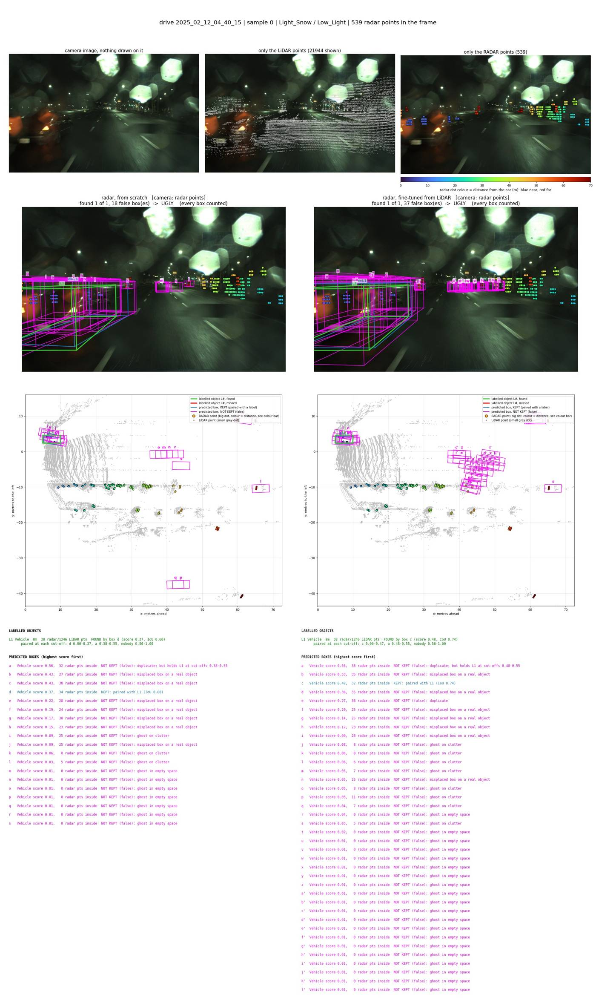

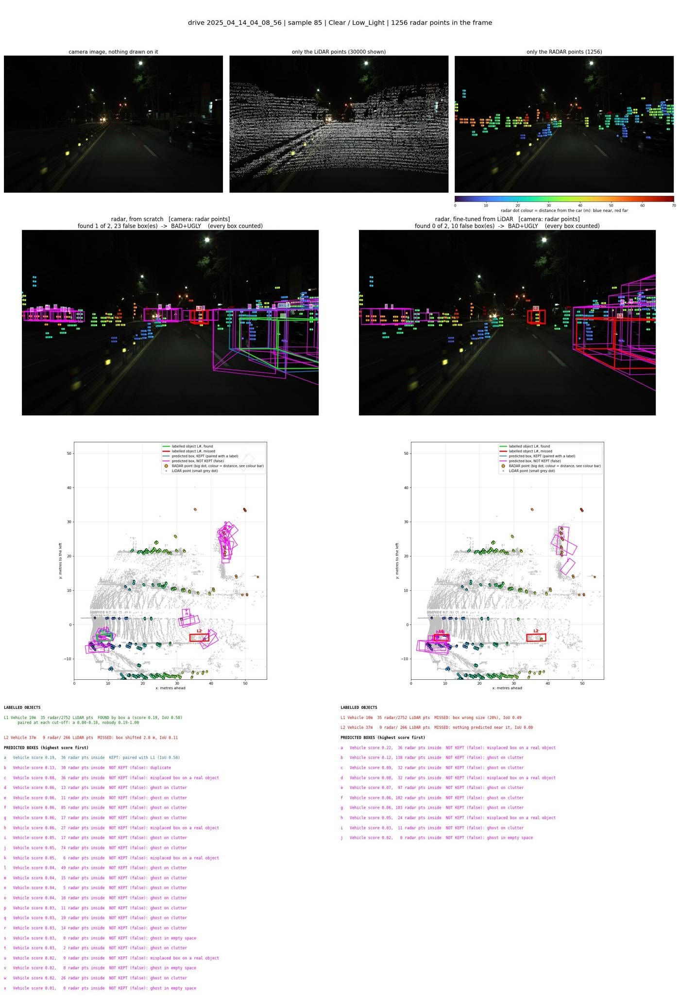

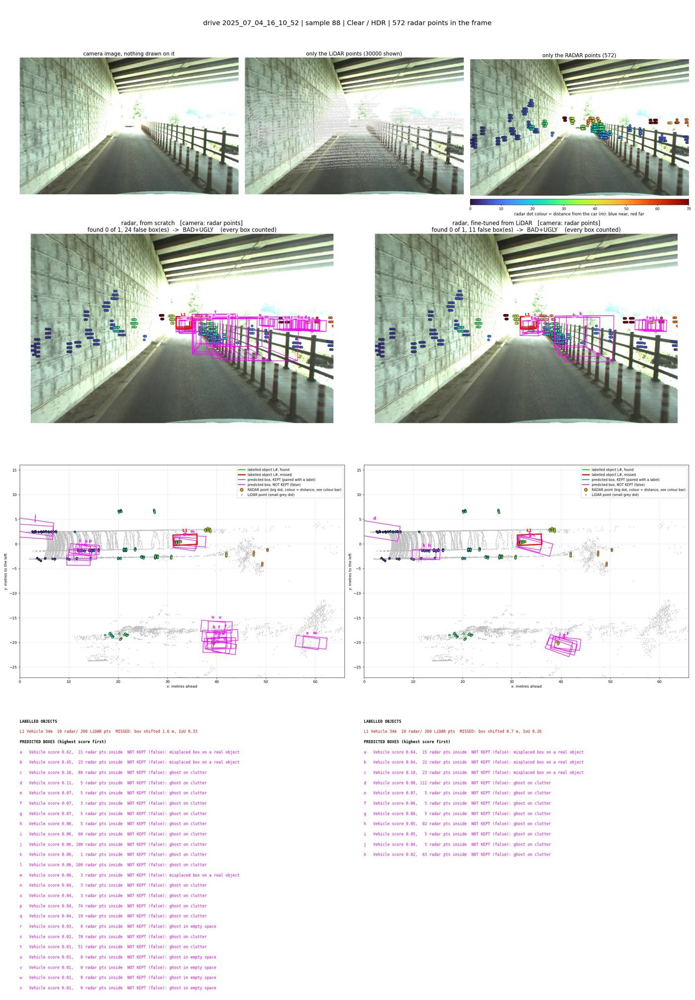

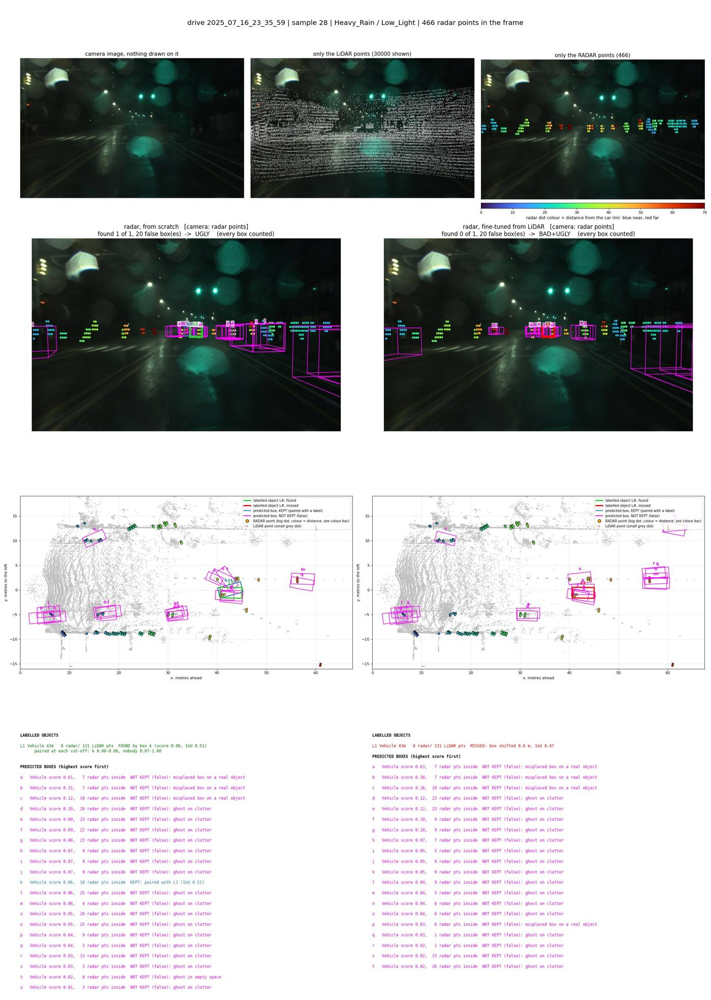

pictures shown in this notebook: about 35 MB of the notebook file (its download from Kaggle stops at 50 MB; if this gets close, lower N_EACH in sections 5-6 or SHOW_WIDTH_MANY in section 4; the full-size pictures are in pictures.zip)
119 pictures in /kaggle/working/pictures.zip


In [27]:
def save_drive(drive, every=1, models=("radar_scratch", "radar_ft_from_livox")):
    "One picture per frame (every n-th) of a drive into pictures/drive_<drive>/, saved only, small resolution."
    ks = list(FR.index[FR.drive == drive])[::every]
    for k in ks:
        show(k, models=models, folder="drive_" + drive, inline=False, dpi=50)
    print("%d pictures in %s" % (len(ks), os.path.join(PIC_DIR, "drive_" + drive)))

# ---- Look at anything: set what you want, run the cell. None = any. ----
WEATHER = None        # "Clear", "Light_Rain", "Heavy_Rain", "Fog", "Light_Snow", "Heavy_Snow", or None
DRIVE = None          # a drive name, e.g. "2025_04_16_07_04_30", or None
SAMPLES = None        # one sample number, a list [10, 20, 30], range(0, 200, 20), or None
FRAMES = None         # frame numbers k as printed elsewhere in this notebook (e.g. [111, 112]); overrides the three above
MISSED_BY = None      # only frames where this model missed a labelled object, e.g. "radar_ft_from_livox", or None
NO_RADAR_BOX = False  # True: only frames with a labelled object that has no radar point on it
MODELS_SHOWN = ("radar_scratch", "radar_ft_from_livox")   # add "livox_pretrain" / "livox_e20_on_radar" to compare
N_MAX = 4             # draw at most this many of the matching frames (spread over the matches)
FOLDER = "7_my_picks" # sub-folder of pictures/ the drawings are saved in

if FRAMES is not None:
    ks = [int(k) for k in np.atleast_1d(FRAMES)]
else:
    sel = FR.copy()
    if WEATHER:
        sel = sel[sel.weather == WEATHER]
    if DRIVE:
        sel = sel[sel.drive == DRIVE]
    if SAMPLES is not None:
        sel = sel[sel["sample"].isin([int(s) for s in np.atleast_1d(list(SAMPLES) if isinstance(SAMPLES, range) else SAMPLES)])]
    if MISSED_BY:
        sel = sel[sel.index.isin(S[(S.model == MISSED_BY) & (S.missed > 0)].k)]
    if NO_RADAR_BOX:
        sel = sel[sel.index.isin(GT[(GT.level == 1) & (GT.radar_pts == 0)].k)]
    ks = list(sel.index)
    if not DRIVE:
        print("drives matching:", sel.groupby(["weather", "drive"]).size().to_dict())
print("%d frames match" % len(ks), "" if len(ks) <= N_MAX else "-> drawing %d of them, spread over the matches" % N_MAX)
for k in ([ks[int(i)] for i in np.linspace(0, len(ks) - 1, N_MAX)] if len(ks) > N_MAX else ks):
    show(k, models=MODELS_SHOWN, folder=FOLDER)

# A whole drive, one picture per frame, saved only (not shown here), to flip through like a video:
# save_drive("2025_04_16_07_04_30", every=2)

print("pictures shown in this notebook: about %.0f MB of the notebook file (its download from Kaggle stops at 50 MB; if this "
      "gets close, lower N_EACH in sections 5-6 or SHOW_WIDTH_MANY in section 4; the full-size pictures are in pictures.zip)"
      % (INLINE_BYTES[0] * 4 / 3 / 1e6))
zip_pictures()   # every picture saved so far -> pictures.zip in the output folder (Kaggle: Output tab -> download)